# Project: Imputing MAC3 Factor History at Low Risk Capital Management

## Background Scenario

Welcome back to Low Risk Capital Management (LRCM). This time you join the Risk and Factor Research team. LRCM's portfolio construction and risk systems were built on Bloomberg's older US equity factor model (the `us_` columns in your data, which we call PORT US). That model is being retired at LRCM, and the firm is being forced to upgrade to Bloomberg's newer factor model, **MAC3**.

Your manager, Professor Low, explains: "MAC3 is the better model, but it only has history back to about 2020. Our risk committee will not sign off on a factor model it cannot test through the two great crashes, the dot-com bust after March 2000 and the financial crisis after October 2007. Nobody can sell us MAC3 for those dates, so we have to build it. Your job is to reconstruct MAC3 for every stock at the two market peaks, prove the reconstruction is good on the years where we can check it, and then show that the reconstructed factors would have pointed at the stocks that crashed. And before anyone on the desk says 'just train a crash model on 2000 and use it next time', I want you to test that idea too."

You do not need to know why stocks crash; this is a data science problem. LRCM's research analysts have already told you which factors to look at (see **The Analysts' Hint** below). Treat their hint as a requirement from the business.

## The Data

One tar file, `20261012_mac3_bloomberg_ports.tar`, holds the raw Bloomberg PORT exports exactly as Bloomberg produced them. Each date has two Excel files covering the same top ~1,600 US-listed stocks and ADRs by traded value that day: **file A**, `<date>_BLG_Port.xlsx`, and **file B**, `<date>_BLG_Port_2.xlsx`.

| Date | Role | MAC3 | Crash returns |
|---|---|---|---|
| 2000-03-24 (dot-com peak) | Imputation target | Empty | In file B |
| 2007-10-09 (financial-crisis peak) | Imputation target | Empty | In file B |
| 2022-11-30, 2023-11-30, 2024-11-30 | Training years | Known | |
| 2025-11-30 | First test year | Known | |
| 2026-10-09 | Second test year, and the extra credit | Known | |

The tar also holds `sector_fill_20000324.csv` and `sector_fill_20071009.csv`. Bloomberg has no GICS sector for 55 percent of the 2000 stocks and 22 percent of the 2007 stocks, mostly companies that later disappeared. These two files give each of them a sector, an industry and a confidence level, assigned from the company name alone, without looking at returns.

**What the files hold** (Part 1 renames them):
- **File A:** the PORT US factor exposures (`PORT US Vol Fact Exp:D-1` and so on), valuation (P/S, P/B, P/E and Bloomberg's forward estimates), ROE, beta, prior returns, market cap, GICS sector and industry, free-cash-flow yield, employees, traded value.
- **File B:** buybacks, shares outstanding, BI STOX scores, the 17 MAC3 exposures (`PORT MAC3 Vol Factor Exp:D-1` and so on), and on the two peak dates only, total-return windows named `TOTAL_RET_<peak>_<end>`, in percent. The last window ends at the bottom of each crash: 9 Oct 2002 and 9 Mar 2009.

**Names used in this template.** PORT US factors become `us_` plus the factor in lower case (`us_vol`, `us_val`, `us_lev`, `us_sz`); MAC3 factors become `mac3_` plus the factor in lower case with underscores (`mac3_vol`, `mac3_value`, `mac3_lvrg`, `mac3_mid_cap`, `mac3_lt_rev`); the sector is `sector`; the crash return you build in Part 1 is `total_return`.

**`total_return` never enters an imputation model.** It grades your reconstruction at the end, and in Part 6 one crash's total returns may train a model that is tested on the other crash.

## The Analysts' Hint

LRCM's research analysts have studied both crashes and give you this:

1. **Both crashes:** the most **volatile** stocks fell hardest.
2. **2000:** the damage centred on technology (Information Technology and Communication Services), and inside it the most **expensive** stocks fell hardest.
3. **2007:** the damage centred on **Financials**, and inside it the most **levered** stocks fell hardest.

## Project Requirements

### Part 1: Data Inventory, Merging and EDA (6 points)
> **From the desk:** "Bloomberg just sent us fourteen spreadsheets with banner rows on top, a footer at the bottom, and no sector for half of the companies in 2000. Welcome to real data. Nobody at LRCM builds a model on a panel they have not counted, row by row."

1. **Inventory the files.** For each of the 14 Excel files report rows, columns and the layout around the data: the banner rows above the header, the `None (1600 securities)` row, and the Bloomberg footer at the bottom. Then make a table of the columns: which are in file A only, which in file B only, and which in both (for example `Ticker` and `Short Name`). Mark which dates have MAC3 filled and which have total-return windows.
2. **Merge file A and file B for each date** on `Ticker`, keeping only the rows that are securities (the ticker ends in `Equity`). Confirm that all 1,600 stocks match, and take each shared column from one file only.
3. **Stack the dates** into one panel with a `date` column, and rename the columns to the short names above.
4. **Fill the missing sectors** on the two peak dates: use Bloomberg's GICS sector where it exists and the sector-fill file only where Bloomberg is blank. Report how many stocks each source covers.
5. **Build `total_return`** for each peak-date stock from the `TOTAL_RET_` windows: the last window if it is filled; if it is blank, because the stock stopped trading before the bottom (mostly takeovers, some bankruptcies), the latest earlier window that is filled; if every window is blank, leave it missing and drop that stock from Parts 5 and 6.
6. **Check for duplicate listings.** A few companies appear twice on the peak dates under an old and a new ticker with identical history (identical market cap and identical return windows). Find them and keep one.
7. **EDA**, with a chart or table for each:
   - Missingness: the share of each feature filled on each date. Several features are much sparser in 2000 than in 2025; find them, because your models will meet them.
   - Each MAC3 factor's distribution in the training years: which look continuous, which look clipped or bounded, and which barely change from year to year.
   - Market cap and sector mix by date: how different is the market of 2000 from the market of 2025?
   - Each MAC3 factor against its closest PORT US twin in 2025: which are nearly the same, and which carry new information?
   - `total_return` in each crash: the median stock and the equal-weighted average of all stocks.

### Part 2: Baseline and Validation Framework (4 points)
> **From the desk:** "If your fancy model cannot beat the old model's own factor, it does not get a seat at the table. And if your test year leaked into your training, I will find it, and so will the regulators."

1. **Walk-forward validation:** train on 2022 to 2024, test on 2025 (the Week 7 setup); then train on 2022 to 2025, test on 2026. Lock every parameter, scaler and feature choice on the training years.
2. **Score with Spearman rank correlation** per factor and per test year. LRCM's downstream models use ranks, so ranks are what must be right.
3. **Twin baseline:** for each MAC3 factor, predict it from its closest PORT US twin alone (for example `us_sz` for `mac3_size`). Every model you build must beat this number to earn its place.

### Part 3: Imputation Models (8 points)
> **From the desk:** "Seventeen factors, seventeen personalities. Size will be easy. Mid Cap will humble you, the way it humbled us in Week 7. Show me you know which is which before you show me a single average."

Repeat every step of the Week 7 walkthrough, this time for **all 17 MAC3 factors**:
1. **Engineered features:** turn raw dollars into comparable features (log market cap, turnover, share growth, buyback yield, employee growth) and add sector columns.
2. **Preprocessing on the training years only:** clip at the 1st and 99th percentiles, fill blanks with training medians, add a missing-value flag per feature, and scale.
3. **Linear family:** OLS, Ridge and Lasso, with alpha chosen by leave-one-year-out on the training years. Report how many features Lasso keeps.
4. **The degree-2 expansion:** every feature squared and every pair multiplied (about 870 columns). Show where OLS overfits and how much Ridge and Lasso recover.
5. **A feature built from the definition:** the Week 7 mid-cap band from cumulative market-cap share, plus at least one feature of your own for another factor. Show the gain factor by factor.
6. **Tree models:** XGBoost and CatBoost (or LightGBM). Print the feature importances for at least two factors, and refit once without your engineered feature to show whether the tree still needs it.
7. **Diagnose before you tune:** sort the 17 factors into easy, curved and hard, and say why each hard one is hard.
8. **Choose a model per factor** and report the walk-forward Spearman of your final choice.

### Part 4: Back to 2000 and 2007 (6 points)
> **From the desk:** "2000 is a foreign country. Forward P/B does not exist there, half the balance-sheet fields are blank, and the whole market was a fraction of today's size. Prove you can live there before you report from it."

1. **Coverage:** the share of each feature that is filled at each peak against 2025. Name the fields that 2000 barely has.
2. **Stress test before you trust it:** blank out of the 2025 test set each feature at the rate it is missing in 2000, re-score, and report how much Spearman each factor loses. Do the same for 2007.
3. **Fill the gaps, three ways,** and score each on the stress test:
   - **Twin fill:** rebuild each forward ratio from its trailing twin (forward P/B from P/B, forward P/S from P/S, forward P/E from P/E) with a log-linear fit on the training years. Report how close the rebuilt forward P/B is to the true one on the blanked 2025 rows.
   - **MICE** (`IterativeImputer`): fill every missing input from all the others, fit on the training years only. Never apply it to the MAC3 targets or to `total_return`.
   - **Train with the future's gaps:** add a copy of the training rows with features blanked at 2000's rates.

   Create a table: factor by method (as is, gaps with no fix, twin plus MICE, train with gaps, all three).
4. **Impute** all 17 MAC3 factors for both peak dates with your chosen models and your best gap fix.
5. **Drift and structure checks:** compare the 2000 and 2007 feature distributions with the training years (does each engineered feature still mean the same thing?), and compare the correlation matrix of your imputed factors with the real MAC3 correlation matrix in 2025.
6. **State a confidence level per factor:** which ones you would let the risk committee use.

### Part 5: Crash Validation with the Analysts' Hint (8 points)
> **From the desk:** "The risk committee asks one question, and it is not about Spearman. If we had held your 30 riskiest names on 24 March 2000, what would have happened to us?"

This part is pandas, not modelling. Follow the steps exactly. The measure you build here, the **basket return**, is the same one you use to score Part 6.

**The measure.** A *basket* is the n stocks with the highest risk score, held in an equal-weighted portfolio over the crash. Its return is the plain average of their `total_return`:
- `basket_return = df.nlargest(n, score_column)["total_return"].mean()`
- Use n = 30 and n = 50 throughout.
- **Benchmark:** the equal-weighted return of all stocks on that date, `df["total_return"].mean()`. A basket only shows skill if it fell further than this.

**Steps, for each peak date separately** (all ranks are percentile ranks within that date, `rank(pct=True)`, so 1.0 is the highest value):
1. Take that date's rows with your imputed MAC3 columns, and drop rows where `total_return` is missing.
2. **Volatility-only baskets.** Over all stocks, `vol_rank = mac3_vol.rank(pct=True)`. Report the top-30 and top-50 basket returns by `vol_rank`.
3. **Keep the epicenter.** 2000: rows whose `sector` is Information Technology or Communication Services. 2007: rows whose `sector` is Financials.
4. **Rank inside the epicenter.** Recompute `vol_rank` on the epicenter rows only. Then the excess rank:
   - 2000, expensive: high MAC3 Value means cheap, so `excess_rank = (-mac3_value).rank(pct=True)`
   - 2007, levered: `excess_rank = mac3_lvrg.rank(pct=True)`
5. **Hint score:** `hint_score = vol_rank + excess_rank`, on the epicenter rows. Report the top-30 and top-50 basket returns by `hint_score`.
6. **Old model:** repeat steps 2 to 5 with the PORT US columns: `us_vol` for volatility, `-us_val` for expensive (high PORT US Value is also cheap), `us_lev` for leverage.
7. **Name names:** list the top 10 stocks by `hint_score` for each peak, with their `name`, `sector` and actual `total_return`.

Create a table like this:
```
Crash     | Score                       | Top-30 EW total return | Top-50 EW total return | All stocks EW total return
----------|-----------------------------|------------------------|------------------------|---------------------------
2000-2002 | Volatility only, MAC3       |
2000-2002 | Hint score, imputed MAC3    |
2000-2002 | Hint score, PORT US         |
2007-2009 | Volatility only, MAC3       |
2007-2009 | Hint score, imputed MAC3    |
2007-2009 | Hint score, PORT US         |
```
Then answer in a sentence each: did the imputed MAC3 baskets beat the all-stocks portfolio, did they beat PORT US, and did the hint beat volatility alone in both crashes?

### Part 6: Can One Crash Predict the Next? (6 points)
> **From the desk:** "Every year someone on this floor says: just train it on the last crash. This year you get to test that idea, on paper, before anyone tries it with the firm's money."

The desk's idea: skip the analysts, learn what crashing stocks looked like in one crash, and use that model for the next one. Test it.
1. **Train a regression model on the 2000 peak** that predicts `total_return` (2000 to 2002) from your imputed MAC3 factors and sector, and **test it on the 2007 peak**. Turn the predictions into a risk score (`risk_score = -predicted_return`, so the stocks predicted to fall furthest score highest) and score it with the Part 5 basket return, top 30 and top 50. Then the reverse: train on 2007, test on 2000. Ranking stocks within each date, for both the features and the target, puts the two crashes on one scale.
2. **Compare with the plain rule:** the volatility-only baskets from Part 5 need no training at all. Did the trained model beat them?
3. **Look inside the model:** print the largest coefficients of the 2000 linear model, positive and negative. Which factors did it treat as signs of danger and which as signs of safety? Compare that with the analysts' hint for 2007: which half of what it learned should carry over, and which half should not?
4. **Vary the model and its regularization.** Repeat step 1 with each of these, every one trained on one crash and applied to the other:
   - Linear regression, with no regularization
   - Ridge, alpha from small to large (for example 1, 10, 100, 1000)
   - Lasso, at least three alphas; report how many features each keeps
   - CatBoost, from deep and lightly regularized (for example `depth=6`, `l2_leaf_reg=3`) to shallow and heavily regularized (`depth=1`, `l2_leaf_reg=100`)

   Did more regularization help in both directions, in one, or in neither? Did the most flexible model transfer best or worst, and why might that be?
5. **Say the lesson out loud** in your presentation, in one or two plain sentences.

Create a table like this:
```
Train on  | Test on   | Model and regularization    | Top-30 EW total return | Top-50 EW total return | All stocks EW total return
----------|-----------|-----------------------------|------------------------|------------------------|---------------------------
2000-2002 | 2007-2009 | Linear regression           |
2000-2002 | 2007-2009 | Ridge, alpha = 1 ... 1000   |
2000-2002 | 2007-2009 | Lasso, each alpha           |
2000-2002 | 2007-2009 | CatBoost, deep ... shallow  |
none      | 2007-2009 | Volatility only (Part 5)    |
2007-2009 | 2000-2002 | (the same rows, reversed)   |
none      | 2000-2002 | Volatility only (Part 5)    |
```

### Part 7: Code Quality and Reproducibility (2 points)
> **From the desk:** "If it does not run top to bottom on a clean machine, it did not happen."

- The notebook runs top to bottom after **Restart and run all**, with no hidden cell order.
- Every number in your slides and video is printed by the notebook.

### Bonus
- **2026 watch list (extra credit):** apply your method to the 2026-10-09 files and list the 30 stocks you predict are most likely to crash. MAC3 is real in 2026, so no imputation is needed. You choose the method: volatility alone, your Part 6 model, or a hint of your own (name the epicenter and the excess you would screen for, and say why, for example from the sector weights you studied in Project 1). There is no answer key; this is graded on method and reasoning. Save it as `watchlist_2026.csv`.
- **Beyond the epicenter:** list stocks your score flags as risky that sit outside the hint's epicenter, and report whether they crashed.
- **Uncertainty:** give each imputed factor a range instead of a single number (quantile models, or the spread across your top models), and show whether the crash results survive it.

### Part 8: Presentation (40 points)
Create a **12 to 15 minute video presentation** covering:

1. **Problem and Methodology** (about 4 minutes)
   - Why LRCM needs MAC3 history, in one minute
   - Your validation framework and why it cannot leak
   - Your models, your engineered features, and the per-factor choice

2. **Results** (about 6 minutes)
   - Walk-forward Spearman per factor, and the hard factors
   - The 2000 and 2007 stress tests, drift and structure checks
   - The crash validation table, and old model against new
   - The cross-crash test and its lesson

3. **Critical Evaluation** (about 3 minutes)
   - Which reconstructed factors you would and would not let the risk committee use, and why
   - What you cannot check (there is no MAC3 answer key for 2000 or 2007)
   - Suggested improvements

## Suggested Team Split (four members)

One way to divide the work so that every member owns a part they can present:

| Member | Owns | Hands off to |
|---|---|---|
| A | Parts 1 and 2: inventory, merging files A and B, EDA, validation framework, twin baseline | B and C: the clean panel and the scoring function |
| B | Part 3: the 17 imputation models, the degree-2 expansion, engineered features, importances | C: one fitted model per factor |
| C | Part 4: coverage, stress test, twin fill, MICE, training with gaps, imputing 2000 and 2007 | D: the imputed factors |
| D | Parts 5 and 6: the hint score, crash validation, the cross-crash test | everyone: the final tables |

Teams of two or three combine roles (for example A with B, and C with D). Larger teams are expected to complete the bonus items.

## Key Implementation Notes
1. **Leakage:** anything a model learns (scalers, alphas, medians used for filling, feature selections) comes from training rows only. A transform computed within one date from that date's own features, such as ranking stocks against each other, is fair.
2. **Missing values:** tree models route them on their own; linear models need a filling rule fit on the training years.
3. **Ranks:** score with Spearman, and consider rank-transforming within each date so that the much smaller market of 2000 lines up with 2025. The same applies to the cross-crash models in Part 6.
4. **`total_return`** is read only in Parts 5 and 6.

## Critical Evaluation Points to Address

Students should discuss:
- Why a random 80/20 split overstates accuracy on this problem
- Which MAC3 factors are nearly a relabelled PORT US factor, and which carry new information
- How far 2000 is from the training years, and what that does to trust in the imputation
- Whether a good Spearman on 2025 guarantees a good reconstruction in 2000
- What the cross-crash test says about learning from one crash to predict the next

## Deliverables

### Required Submissions:
1. **Presentation Video** (12 to 15 minutes)
   - All team members appear on camera and present the part they own
   - Include screen recordings showing code execution, the Spearman tables, the crash validation table and the cross-crash table

2. **Code Notebook** (`.ipynb`), run top to bottom, with outputs saved

3. **Trello Board Screenshot**
   - Clear task assignments
   - Completion status
   - Individual contributions documented

4. **Results Files:**
   - `imputed_mac3_20000324.csv` and `imputed_mac3_20071009.csv`: ticker plus your 17 imputed factors
   - `spearman_by_factor.csv`: walk-forward Spearman per factor, per model, per test year
   - `crash_validation.csv`: the Part 5 table
   - `cross_crash.csv`: the Part 6 table

5. **AI Disclosure Statement** in the notebook

## Grading Breakdown

### Presentation (40%)
- Problem, methodology and results: 25%
- Critical evaluation and insights: 15%

### Technical Implementation (40%)
- Data inventory, merging, EDA and validation framework: 10%
- Imputation models and feature engineering: 8%
- Transfer to 2000 and 2007: 6%
- Crash validation with the hint: 8%
- Cross-crash test: 6%
- Code quality and reproducibility: 2%

### Project Management (20%)
- Trello board with clear tasks, owners and progress

**Individual Grading:**
- Different grades based on Trello-documented contributions

## Critical Considerations

**Professor Low's Guidance on Performance Evaluation:**

1. **Spearman Reality Check (from the Week 7 walkthrough, 2025 test year):**
   - Twin baseline: about 0.60 on average
   - Linear models with good features: about 0.77 to 0.84
   - Tree models: about 0.87
   - Size, Value and Momentum: above 0.90. Liquidity: about 0.66, the hardest of the five shown in class.
   - If you see 0.99 on Liquidity or Long-Term Reversal, you have a leak, not a breakthrough.

2. **Crash Validation Reality Check:**
   - An equal-weighted portfolio of all stocks lost about 46 percent over 2000 to 2002 and about 58 percent over 2007 to 2009, so "my riskiest stocks fell" proves nothing. Compare every basket with the all-stocks portfolio.
   - If your riskiest 30 did better than the all-stocks portfolio, your score points the wrong way.
   - In Part 6, a trained model that does no better than volatility alone is a result, not a bug. Report it and explain it.

3. **Common Errors:**
   - Fitting a scaler or filling rule on all six dates
   - Training an imputation model on `total_return`, or choosing features because they correlate with it
   - Dropping the 2000 stocks with missing features, which quietly removes many of the companies that crashed

"Financial data is dirty, and history is dirtier. The goal is not a perfect number for a year we cannot check; it is a reconstruction you can defend to a risk committee: validated where we can check it, stress-tested where we cannot, and honest about which factors, and which ideas, do not survive the test."

## AI Usage Policy

Students must review the complete policy on the course webpage. Key points:

- **Required Disclosure:** Document all AI assistance
- **Zero Credit Triggers:**
  - Non-functional code
  - Fabricated results
  - Missing AI disclosure
  - Hallucinated functions/libraries

- **Enhanced Scrutiny:** AI-assisted work faces stricter grading. Bugs and hallucinations incur penalties beyond standard deductions.

## Final Tips

Remember:
- Document your assumptions clearly
- Show your validation before your results
- Be honest about which factors you cannot reconstruct well
- Focus on learning, not on a perfect-looking score

Good luck with your analysis!


# Data and Walkthrough

* Data: `20261012_mac3_bloomberg_ports.tar`, 14 Bloomberg Excel files (file A and file B for seven dates) and two sector-fill files. The next cell downloads and unpacks it.
* Week 7 walkthrough notebook (loads the same files and imputes five MAC3 factors): https://colab.research.google.com/drive/<redacted-course-data-file>


In [ ]:
# Download and unpack the Bloomberg exports (file A and file B for each date) and the two sector-fill files
!gdown <redacted-course-data-file>
!tar xvf 20261012_mac3_bloomberg_ports.tar

## Warning about Gen AI usage (from the brief)

AI assistants take shortcuts on this kind of problem that make only the appearance of analysis. Shortcuts like these, if still present in the submission, will earn a zero grade:

* **Imputing with the answer.** Using `total_return` as a feature in an imputation model, or choosing features because they correlate with it.
* **Filling the past with the future.** Copying a ticker's 2025 MAC3 value into 2000 or 2007, or filling missing features with medians computed over all dates, including the test years.
* **Shrinking the universe "for speed."** Dropping the 2000 stocks with missing features, or sampling a few hundred stocks. The crash validation needs the whole universe.
* **A score tuned on the outcome.** Searching weights for the Part 5 crash score until the top-30 basket looks good. The hint tells you what to combine; how you combine it is decided before you look at the outcome.
* **Testing on the training crash.** In Part 6, a model trained on 2000 is scored on 2007 only, and the reverse. A score on the crash it was trained on is not a test.


# Part 1: Data Inventory, Merging and EDA  *(Member A: Muhammad Talha Khan)*

## 1.1 Inventory the 14 files

In [ ]:
import os, glob, re, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 200)
np.random.seed(42)

DATA_DIR = os.environ.get("MAC3_DATA", ".")
DATES = ["20000324", "20071009", "20221130", "20231130", "20241130", "20251130", "20261009"]
PEAKS = ["20000324", "20071009"]
TRAIN_YEARS = ["20221130", "20231130", "20241130"]
TEST_YEARS = ["20251130", "20261009"]
print("data folder:", os.path.abspath(DATA_DIR))
print(sorted(os.path.basename(f) for f in glob.glob(os.path.join(DATA_DIR, "*BLG_Port*.xlsx"))))

In [ ]:
def file_path(date, which):
    return os.path.join(DATA_DIR, f"{date}_BLG_Port.xlsx" if which == "A" else f"{date}_BLG_Port_2.xlsx")

RAW = {}
inv_rows = []
for date in DATES:
    for which in ["A", "B"]:
        raw = pd.read_excel(file_path(date, which), header=None)
        RAW[(date, which)] = raw
        first = raw.iloc[:, 0].astype(str)
        header_row = int(np.where(first.values == "Ticker")[0][0])
        none_row = int(np.where(first.str.startswith("None (").values)[0][0])
        sec_rows = np.where(first.str.endswith(" Equity").values)[0]
        footer_rows = [i for i in range(sec_rows.max() + 1, len(raw)) if raw.iloc[i].notna().any()]
        inv_rows.append({
            "date": date, "file": which, "raw_rows": raw.shape[0], "raw_cols": raw.shape[1],
            "banner_rows": header_row, "banner_text": " | ".join(str(v) for v in raw.iloc[:header_row].values.ravel() if pd.notna(v)),
            "header_row": header_row, "none_row": none_row, "none_text": first.iloc[none_row],
            "first_security_row": int(sec_rows.min()), "last_security_row": int(sec_rows.max()),
            "n_securities": len(sec_rows),
            "blank_rows_after": int(sum(raw.iloc[i].isna().all() for i in range(sec_rows.max() + 1, len(raw)))),
            "footer_rows": len(footer_rows),
            "footer_start": first.iloc[footer_rows[0]][:45] + "..." if footer_rows else "",
        })
inventory = pd.DataFrame(inv_rows)
inventory.drop(columns=["banner_text"])

In [ ]:
print("Banner text above the header (identical in every file):", inventory["banner_text"].unique())
print("Securities per file:", inventory["n_securities"].unique())

Every file has the same frame: **2 banner rows** (`EQY_FUND_CRNCY / REL_INDEX / FA_ADJUSTED` and `LCL`), the header in the
third row, a **`None (1600 securities)`** grouping row, exactly **1,600 security rows**, one blank row and a **one-row
Bloomberg disclaimer footer**. So the clean read is `header=2`, then keep only rows whose ticker ends in `Equity`.

In [ ]:
def read_clean(date, which):
    raw = RAW[(date, which)]
    hdr = raw.iloc[2].tolist()
    # Bloomberg repeats "Ticker" (the second one is the short "ZRAN US" form); make the names unique
    seen, cols = {}, []
    for c in hdr:
        c = str(c)
        if c in seen:
            seen[c] += 1
            cols.append(f"{c}.{seen[c]}")
        else:
            seen[c] = 0
            cols.append(c)
    df = raw.iloc[3:].copy()
    df.columns = cols
    df = df[df["Ticker"].astype(str).str.endswith("Equity")].reset_index(drop=True)
    for c in df.columns:
        if c not in ("Ticker", "Short Name", "Ticker.1", "GICS Sector", "GICS Ind Name", "GICS SubInd Name", "CUSIP"):
            df[c] = pd.to_numeric(df[c], errors="coerce")
    return df

CLEAN = {(d, w): read_clean(d, w) for d in DATES for w in ["A", "B"]}
colsA = {d: list(CLEAN[(d, "A")].columns) for d in DATES}
colsB = {d: list(CLEAN[(d, "B")].columns) for d in DATES}
print("file A columns identical across dates:", all(colsA[d] == colsA[DATES[0]] for d in DATES))
print("file B columns excluding TOTAL_RET identical across dates:",
      all([c for c in colsB[d] if not c.startswith("TOTAL_RET")] == [c for c in colsB[DATES[0]] if not c.startswith("TOTAL_RET")] for d in DATES))

### Column table: file A only, file B only, both

In [ ]:
all_cols = list(dict.fromkeys([c for d in DATES for c in colsA[d] + colsB[d]]))
coltab = []
for c in all_cols:
    inA = any(c in colsA[d] for d in DATES)
    inB = any(c in colsB[d] for d in DATES)
    where = "both" if inA and inB else ("A only" if inA else "B only")
    src = "A" if inA else "B"
    filled = {d: round(100 * CLEAN[(d, src)][c].notna().mean(), 1) if c in CLEAN[(d, src)] else np.nan for d in DATES}
    coltab.append({"column": c, "in": where, **{f"%filled {d}": filled[d] for d in DATES}})
column_table = pd.DataFrame(coltab)
print(column_table["in"].value_counts().to_string())
column_table

In [ ]:
mac3_raw_cols = [c for c in all_cols if c.startswith("PORT MAC3")]
ret_cols = {d: [c for c in colsB[d] if c.startswith("TOTAL_RET")] for d in DATES}
date_tab = pd.DataFrame({
    "MAC3 % filled (mean of 17)": {d: round(100 * CLEAN[(d, "B")][mac3_raw_cols].notna().mean().mean(), 1) for d in DATES},
    "total-return windows": {d: ", ".join(ret_cols[d]) if ret_cols[d] else "-" for d in DATES},
})
date_tab["role"] = ["imputation target"] * 2 + ["training"] * 3 + ["test 1", "test 2 / extra credit"]
date_tab

## 1.2 Merge file A and file B for each date on `Ticker`
Shared columns (`Short Name`, the short `Ticker.1`, `Equity Traded Val:D-1` and its rank) are taken from **file A only**;
before dropping file B's copy we check that the two copies agree.

In [ ]:
merged = {}
for d in DATES:
    A, B = CLEAN[(d, "A")], CLEAN[(d, "B")]
    shared = [c for c in B.columns if c in A.columns and c != "Ticker"]
    assert A["Ticker"].is_unique and B["Ticker"].is_unique
    m = A.merge(B, on="Ticker", how="outer", suffixes=("", "__B"), indicator=True)
    both = m[m["_merge"] == "both"]
    agree = all(((both[c] == both[c + "__B"]) | (both[c].isna() & both[c + "__B"].isna())).all() for c in shared)
    print(f"{d}: A={len(A)} B={len(B)} matched={len(both)} "
          f"A-only={(m['_merge']=='left_only').sum()} {list(m.loc[m._merge=='left_only','Ticker'])} "
          f"B-only={(m['_merge']=='right_only').sum()} {list(m.loc[m._merge=='right_only','Ticker'])} "
          f"| shared columns identical on matched rows: {agree}")
    # inner merge: a stock needs both halves (PORT US features from A, MAC3 / returns from B)
    merged[d] = both.drop(columns=[c + "__B" for c in shared] + ["_merge"]).reset_index(drop=True)

In [ ]:
# 2026: which shared columns disagree between file A and file B on the matched tickers?
A26, B26 = CLEAN[("20261009", "A")], CLEAN[("20261009", "B")]
shared26 = [c for c in B26.columns if c in A26.columns and c != "Ticker"]
mm = A26.merge(B26, on="Ticker", suffixes=("", "__B"))
for c in shared26:
    diff = ~((mm[c] == mm[c + "__B"]) | (mm[c].isna() & mm[c + "__B"].isna()))
    print(f"{c}: {diff.sum()} of {len(mm)} matched rows differ")

On the six dates from 2000 to 2025 all 1,600 tickers match, and every shared column carries the same values in both
files, so taking them from file A loses nothing. **2026-10-09 is the exception:**

1. **Different universe.** 4 tickers are only in file A (e.g. QRVO, ASH) and 4 only in file B (e.g. TEVA). We keep the
   1,596 that are in both, since a stock needs file A (inputs) and file B (MAC3) to be used.
2. **Only the rank differs on matched rows.** The check above shows that `Short Name`, `Ticker.1` and the traded value
   itself (`Equity Traded Val:D-1`) are identical on all 1,596 matched tickers, so both files come from the same
   snapshot. Only `Rank(Equity Traded Val 1 Day ago)` differs, on 1,381 rows. Bloomberg computes that rank *within
   each file's own universe*, and the two universes differ by 4 stocks each way, so any stock that is added or removed
   high up the list moves the rank of every stock below it. We take the rank from file A, and it is not used as a model
   input anyway (the models use the traded value itself).

File A lists stocks in reverse alphabetical order and file B by traded value, which is why we merge on `Ticker` and
never on row position.

## 1.3 Stack the dates into one panel and rename

In [ ]:
RENAME = {
    "Ticker": "ticker", "Short Name": "name", "Ticker.1": "ticker_short", "CUSIP": "cusip",
    "PORT US Prof Fact Exp:D-1": "us_prof", "PORT US Vol Fact Exp:D-1": "us_vol", "PORT US Lev Fact Exp:D-1": "us_lev",
    "PORT US Mom Fact Exp:D-1": "us_mom", "PORT US Val Fact Exp:D-1": "us_val", "PORT US Gr Fact Exp:D-1": "us_gr",
    "PORT US Dvd Yld Fact Exp:D-1": "us_dvd_yld", "PORT US Earn Var Fact Exp:D-1": "us_earn_var", "PORT US Sz Fact Exp:D-1": "us_sz",
    "P/S": "ps", "BEst P/S BF12M": "fwd_ps", "P/B": "pb", "BEst P/B BF12M": "fwd_pb", "P/E": "pe", "BEst P/E BF12M": "fwd_pe",
    "ROE LF": "roe", "GICS SubInd": "gics_subind_code", "GICS Sector": "gics_sector", "GICS Ind Name": "gics_industry",
    "GICS SubInd Name": "gics_subindustry", "Beta:Y-1": "beta", "Total Return:Y-1": "ret_1y", "Total Return:M-3": "ret_3m",
    "Number of Employees:Y": "employees", "Number of Employees:Y-5": "employees_5y", "Market Cap": "mcap",
    "Gr PoP of Tot Debt:Q:Q[currency=LCL], -12)": "debt_growth_3y", "Insider Sells Volume 1 Year:Y-1": "insider_sells",
    "FCF Yld": "fcf_yld", "FCF Yld:Q-12": "fcf_yld_q12", "FCF Yld:Y": "fcf_yld_y", "FCF Yld:Y-1": "fcf_yld_y1",
    "Net Fixed Asset Turnover LF": "fa_turnover", "Gr PoP of Net Fixed Asset Turnover:Y:Y, -5)": "fa_turnover_growth_5y",
    "Equity Traded Val:D-1": "traded_val", "Rank(Equity Traded Val 1 Day ago)": "traded_val_rank",
    "Avg Px Pd Repurch LF": "buyback_px", "Val Sh Repurch fr Repurch Prog:Y": "buyback_val", "Val Sh Repurch fr Repurch Prog:Y-1": "buyback_val_y1",
    "Shares Out:Y": "shares_out", "Shares Out:Y-1": "shares_out_y1", "BEst CAPEX BF12M": "capex_fwd", "BEst CAPEX:CQ-4 BF12M": "capex_fwd_q4",
    "BI STOX Quality (BLOOMBERG L.P.)": "stox_quality", "BI STOX Leverage (BLOOMBERG L.P.)": "stox_leverage",
    "BI STOX Low Volatility (BLOOMBERG L.P.)": "stox_lowvol", "BI STOX Profitability (BLOOMBERG L.P.)": "stox_prof",
    "BI STOX Multi-Factor Score (BLOOMBERG L.P.)": "stox_multi", "BI STOX Momentum (BLOOMBERG L.P.)": "stox_mom",
}
for c in mac3_raw_cols:
    short = c.replace("PORT MAC3 ", "").replace(" Factor Exp:D-1", "")
    RENAME[c] = "mac3_" + short.lower().replace(" ", "_")
MAC3 = [RENAME[c] for c in mac3_raw_cols]
US = ["us_prof", "us_vol", "us_lev", "us_mom", "us_val", "us_gr", "us_dvd_yld", "us_earn_var", "us_sz"]
print("17 MAC3 factors:", MAC3)

frames = []
for d in DATES:
    m = merged[d].rename(columns=RENAME)
    m.insert(0, "date", pd.Timestamp(d))
    frames.append(m)
panel = pd.concat(frames, ignore_index=True)
panel["date_str"] = panel["date"].dt.strftime("%Y%m%d")
assert not [c for c in panel.columns if c not in RENAME.values() and not c.startswith("TOTAL_RET") and c not in ("date", "date_str")]
print(panel.shape)
panel.groupby("date_str").size()

## 1.4 Fill the missing sectors on the two peak dates
Bloomberg's GICS sector wins wherever it exists; the sector-fill file is used only where Bloomberg is blank.
The fill files were built from company names alone, without returns.

In [ ]:
panel["sector"] = panel["gics_sector"]
panel["industry"] = panel["gics_industry"]
panel["sector_source"] = np.where(panel["gics_sector"].notna(), "Bloomberg GICS", "missing")
panel["sector_confidence"] = np.where(panel["gics_sector"].notna(), "gics", None)
src_rows = []
for d in PEAKS:
    fill = pd.read_csv(os.path.join(DATA_DIR, f"sector_fill_{d}.csv"))
    assert fill["ticker"].is_unique
    idx = panel.index[(panel["date_str"] == d)]
    sub = panel.loc[idx]
    f = fill.set_index("ticker")
    need = sub["gics_sector"].isna() & sub["ticker"].isin(f.index)
    tick = sub.loc[need, "ticker"]
    panel.loc[tick.index, "sector"] = f.loc[tick, "sector"].values
    panel.loc[tick.index, "industry"] = f.loc[tick, "industry"].values
    panel.loc[tick.index, "sector_source"] = "sector-fill file"
    panel.loc[tick.index, "sector_confidence"] = f.loc[tick, "confidence"].values
    s = panel.loc[idx]
    overlap = sub["gics_sector"].notna() & sub["ticker"].isin(f.index)
    src_rows.append({"date": d, "stocks": len(s), "Bloomberg GICS": int((s.sector_source == "Bloomberg GICS").sum()),
                     "sector-fill file": int((s.sector_source == "sector-fill file").sum()),
                     "still missing": int(s.sector.isna().sum()), "fill rows": len(fill),
                     "fill rows where GICS existed (ignored)": int(overlap.sum()),
                     **{f"fill conf={k}": int((s.sector_confidence == k).sum()) for k in ["high", "medium", "low"]}})
for d in DATES[2:]:
    s = panel[panel.date_str == d]
    src_rows.append({"date": d, "stocks": len(s), "Bloomberg GICS": int(s.gics_sector.notna().sum()), "sector-fill file": 0,
                     "still missing": int(s.sector.isna().sum())})
sector_sources = pd.DataFrame(src_rows).fillna(0)
sector_sources

In [ ]:
pd.crosstab(panel.loc[panel.date_str.isin(PEAKS), "sector"].fillna("(missing)"),
            [panel.loc[panel.date_str.isin(PEAKS), "date_str"], panel.loc[panel.date_str.isin(PEAKS), "sector_source"]])

## 1.5 Build `total_return` for each peak-date stock
The last window if filled; otherwise the latest earlier window that is filled (the stock stopped trading before the
bottom); if all windows are blank, missing. Returns are in percent.

In [ ]:
panel["total_return"] = np.nan
panel["total_return_window"] = None
tr_rows = []
for d in PEAKS:
    wins = sorted(ret_cols[d])                       # chronological: window end dates sort as strings
    idx = panel.index[panel.date_str == d]
    tr = pd.Series(np.nan, index=idx)
    used = pd.Series(None, index=idx, dtype=object)
    for w in wins:                                   # later windows overwrite earlier ones
        ok = panel.loc[idx, w].notna()
        tr[ok] = panel.loc[idx, w][ok]
        used[ok] = w
    panel.loc[idx, "total_return"] = tr
    panel.loc[idx, "total_return_window"] = used
    row = {"date": d}
    for w in wins:
        row[f"from {w}"] = int((used == w).sum())
    row["all blank"] = int(tr.isna().sum())
    tr_rows.append(row)
pd.DataFrame(tr_rows).set_index("date").T

## 1.6 Duplicate listings
On the peak dates a few companies appear twice, under an old and a new ticker, with identical market cap and
identical return windows. We flag rows whose market cap **and** every return window are identical to another row on
the same date, and keep one (the one with more filled fields; ties broken by the larger traded value). On the other
dates there are no return windows, so the key is market cap plus the 1-year and 3-month returns; the same old/new-ticker
pairs show up there (e.g. XOM and 9666655D EXXON MOBIL CORP, PNFP and 9998819D), and we drop them too so that no
company is counted twice in training or testing.

In [ ]:
dup_reports, drop_idx = [], []
for d in DATES:
    s = panel[panel.date_str == d]
    keys = ["mcap"] + (ret_cols[d] if d in PEAKS else ["ret_1y", "ret_3m"])
    s_ok = s.dropna(subset=["mcap"])
    grp = s_ok.groupby(keys, dropna=False)
    for _, g in grp:
        if len(g) > 1:
            g = g.assign(n_filled=g.notna().sum(axis=1)).sort_values(["n_filled", "traded_val"], ascending=False)
            for i, (ix, r) in enumerate(g.iterrows()):
                dup_reports.append({"date": d, "ticker": r.ticker, "name": r["name"], "mcap": r.mcap, "traded_val": r.traded_val,
                                    "filled_fields": r.n_filled, "keep": i == 0})
            drop_idx += list(g.index[1:])
dups = pd.DataFrame(dup_reports)
print("duplicate rows dropped per date:", dups[~dups.keep].groupby("date").size().to_dict() if len(dups) else {})
dups

In [ ]:
panel = panel.drop(index=drop_idx).reset_index(drop=True)
panel.groupby("date_str").size().rename("stocks after de-duplication")

## 1.7 EDA

### Missingness: share of each feature filled on each date

In [ ]:
NUM_RAW = ["us_prof", "us_vol", "us_lev", "us_mom", "us_val", "us_gr", "us_dvd_yld", "us_earn_var", "us_sz",
           "ps", "fwd_ps", "pb", "fwd_pb", "pe", "fwd_pe", "roe", "beta", "ret_1y", "ret_3m", "employees", "employees_5y",
           "mcap", "debt_growth_3y", "insider_sells", "fcf_yld", "fcf_yld_q12", "fcf_yld_y", "fcf_yld_y1", "fa_turnover",
           "fa_turnover_growth_5y", "traded_val", "buyback_px", "buyback_val", "buyback_val_y1", "shares_out", "shares_out_y1",
           "capex_fwd", "capex_fwd_q4", "stox_quality", "stox_leverage", "stox_lowvol", "stox_prof", "stox_multi", "stox_mom"]
miss = (panel.groupby("date_str")[NUM_RAW + ["gics_sector", "sector"]].apply(lambda g: g.notna().mean()) * 100).T.round(1)
miss["2000 minus 2025"] = (miss["20000324"] - miss["20251130"]).round(1)
miss.sort_values("2000 minus 2025")

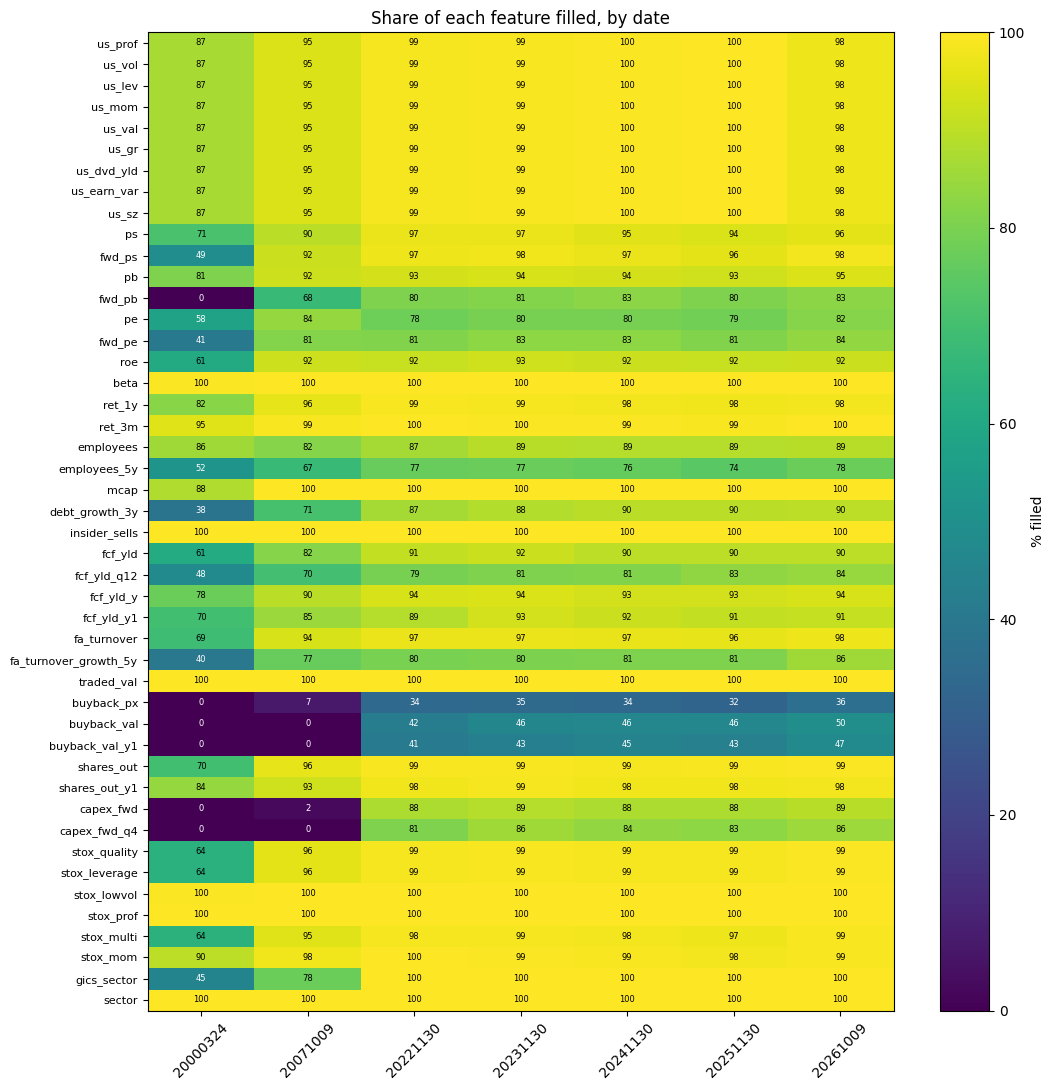

In [ ]:
fig, ax = plt.subplots(figsize=(11, 11))
im = ax.imshow(miss[DATES].values, aspect="auto", cmap="viridis", vmin=0, vmax=100)
ax.set_xticks(range(len(DATES))); ax.set_xticklabels(DATES, rotation=45)
ax.set_yticks(range(len(miss))); ax.set_yticklabels(miss.index, fontsize=8)
for i in range(len(miss)):
    for j, d in enumerate(DATES):
        ax.text(j, i, f"{miss.iloc[i][d]:.0f}", ha="center", va="center", fontsize=6, color="w" if miss.iloc[i][d] < 60 else "k")
plt.colorbar(im, ax=ax, label="% filled"); ax.set_title("Share of each feature filled, by date"); plt.tight_layout(); plt.show()

sparse_2000 = miss[(miss["2000 minus 2025"] <= -25)].sort_values("2000 minus 2025")
print("Features at least 25 points sparser in 2000 than in 2025:")
sparse_2000[["20000324", "20071009", "20251130", "2000 minus 2025"]]

**What the missingness table says.** 19 features are at least 25 points sparser in 2000 than in 2025. The ones 2000
barely has at all:

| Feature | 2000 | 2007 | 2025 |
|---|---|---|---|
| `capex_fwd`, `capex_fwd_q4` | 0% | 2.5% / 0.1% | 88% / 83% |
| `fwd_pb` (forward P/B) | 0% | 68% | 81% |
| `buyback_val`, `buyback_px` | 0% / 0.3% | 0.2% / 6.8% | 46% / 32% |
| `debt_growth_3y` | 38% | 71% | 90% |
| `fa_turnover_growth_5y` | 40% | 77% | 81% |
| `fwd_pe` | 41% | 81% | 81% |
| GICS sector | 45% | 78% | 100% |

Even the PORT US factors are only 87% filled in 2000 (99.7% in 2025), and market cap 88%. 2007 is much closer to
today: apart from capex and buybacks, most fields are within about 15 points of 2025.
**Consequence for the models:** capex and buyback price are left out of the feature list (Part 3.1), and every model
must cope with blanks. Part 4 stress-tests exactly these gaps.

### MAC3 distributions in the training years

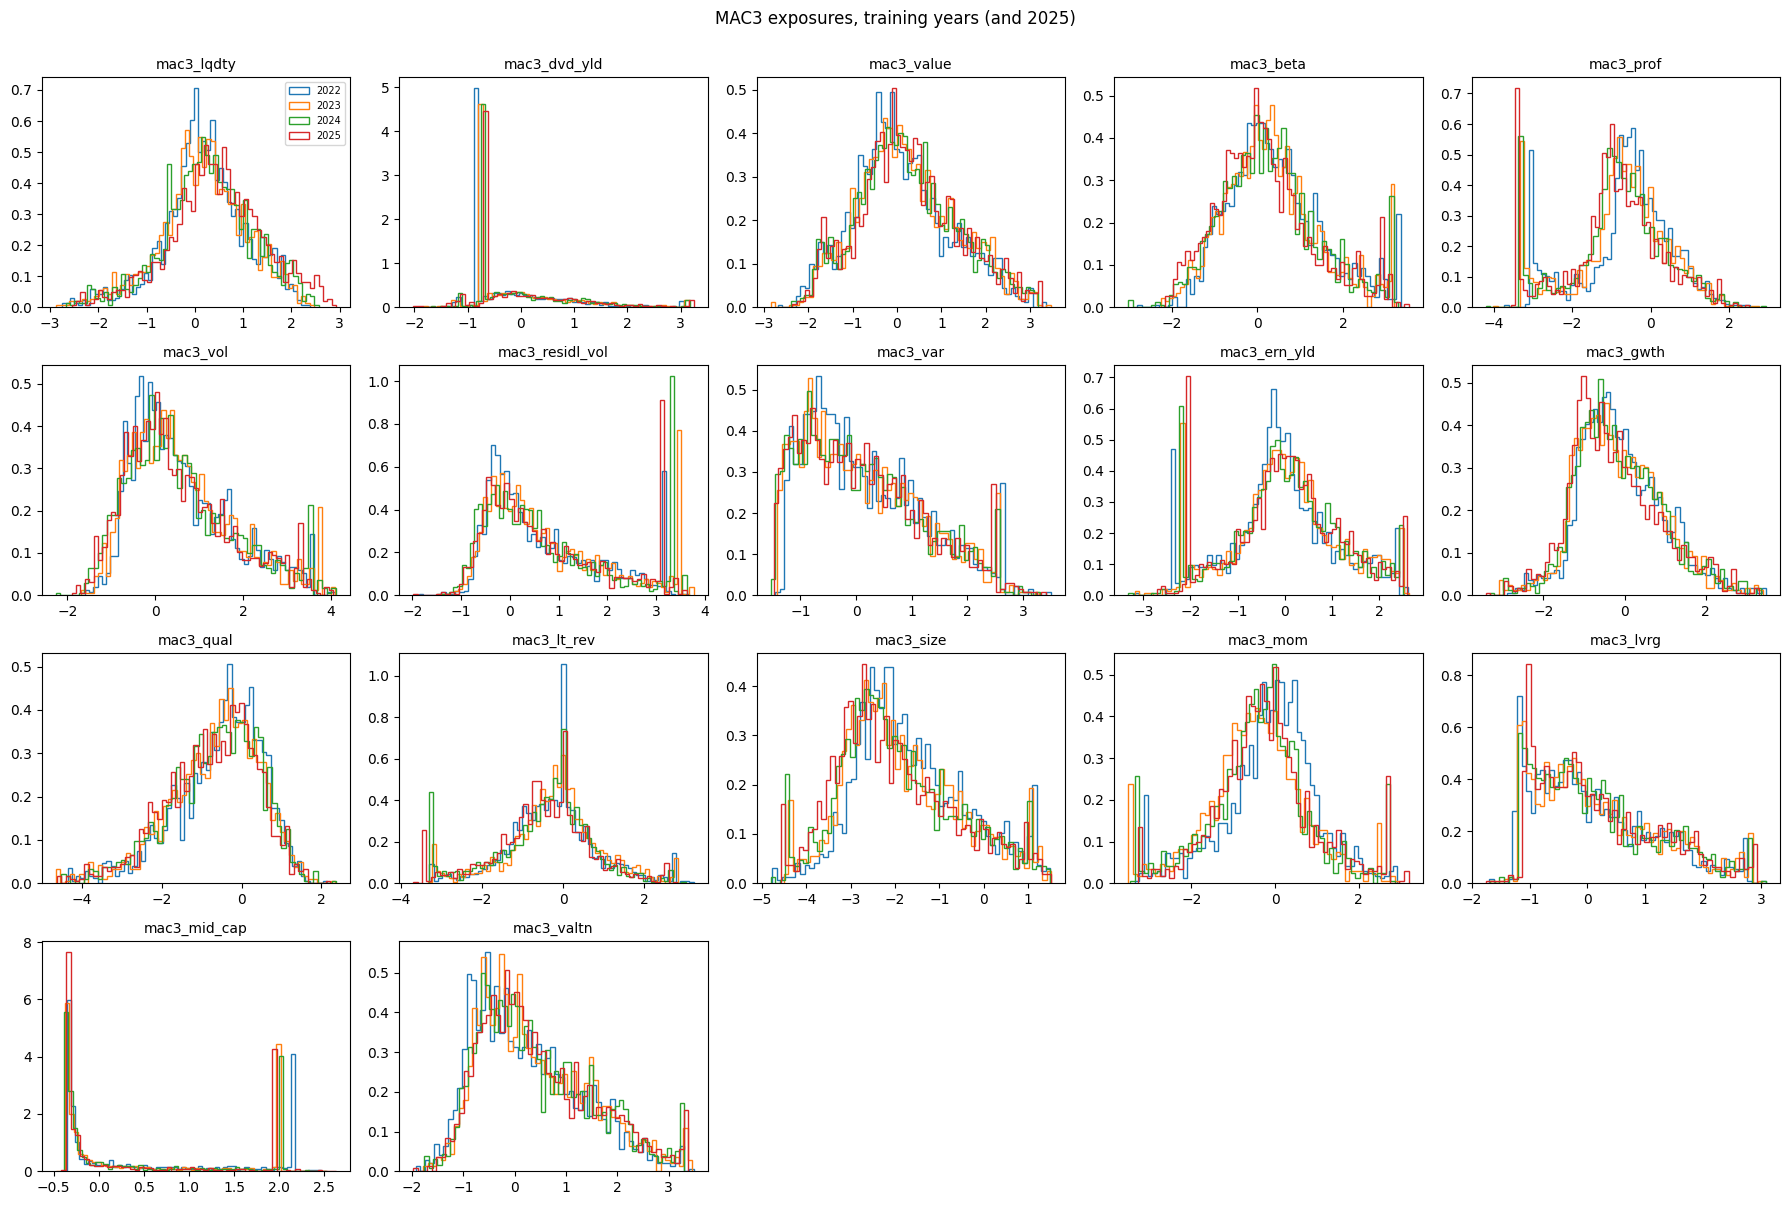

In [ ]:
train = panel[panel.date_str.isin(TRAIN_YEARS)]
fig, axes = plt.subplots(4, 5, figsize=(18, 12)); axes = axes.ravel()
for ax, f in zip(axes, MAC3):
    for d in TRAIN_YEARS + ["20251130"]:
        ax.hist(panel.loc[panel.date_str == d, f].dropna(), bins=60, histtype="step", label=d[:4], density=True)
    ax.set_title(f, fontsize=10)
axes[0].legend(fontsize=7)
for ax in axes[len(MAC3):]: ax.axis("off")
plt.suptitle("MAC3 exposures, training years (and 2025)", y=1.0); plt.tight_layout(); plt.show()

In [ ]:
def dist_summary(f):
    x = train[f].dropna()
    vc = x.round(4).value_counts()
    by_year = train.groupby("date_str")[f]
    # year-to-year stability: same ticker, consecutive training years
    piv = train.pivot_table(index="ticker", columns="date_str", values=f)
    yy = [spearmanr(piv[a], piv[b], nan_policy="omit")[0] for a, b in zip(TRAIN_YEARS[:-1], TRAIN_YEARS[1:])]
    return {"mean": x.mean(), "std": x.std(), "min": x.min(), "max": x.max(), "skew": x.skew(),
            "% at min": 100 * (x <= x.min() + 1e-6).mean(), "% at max": 100 * (x >= x.max() - 1e-6).mean(),
            "top value share %": 100 * vc.iloc[0] / len(x), "distinct values": x.nunique(),
            "yr-to-yr rank corr (same stock)": np.mean(yy)}
mac3_dist = pd.DataFrame({f: dist_summary(f) for f in MAC3}).T.round(3)
def shape_label(r):
    if r["top value share %"] > 5 or r["% at min"] > 2 or r["% at max"] > 2: return "clipped / bounded / spiked"
    if abs(r["skew"]) > 1.5: return "skewed"
    return "continuous"
mac3_dist["shape"] = mac3_dist.apply(shape_label, axis=1)
mac3_dist["persistence"] = pd.cut(mac3_dist["yr-to-yr rank corr (same stock)"], [-1, 0.6, 0.85, 1.01],
                                  labels=["changes a lot", "moderate", "barely changes"])
mac3_dist.sort_values("yr-to-yr rank corr (same stock)", ascending=False)

**What the distributions say.**
* **Clipped / bounded / spiked:** `mac3_dvd_yld` (13.5% of stocks share one value: the non-payers pile up at a single
  exposure) and `mac3_mid_cap` (a hard floor near −0.48 that 7.3% of stocks sit on: anything that is not mid cap gets
  the same low score). For these, a rank-based score matters, because a model cannot separate tied values.
* **Continuous:** the other 15 factors, with standardised-looking means near 0 and standard deviations near 1. None is
  heavily skewed (largest |skew| is 1.39, Dividend Yield).
* **Barely change (same stock, year to year, rank corr ≥ 0.85):** 11 of 17: Size (0.96), Earnings Variability (0.95),
  Leverage (0.94), Dividend Yield (0.93), Volatility, Liquidity, Valuation (0.90), Value, Quality, Residual Vol, Beta.
* **Moderate:** Earnings Yield (0.84), Mid Cap (0.83), Profitability (0.81), Growth (0.73).
* **Change a lot:** Long-Term Reversal (0.51) and Momentum (**0.09**: last year's momentum ranking tells you almost
  nothing about this year's).

The high persistence is the reason a random 80/20 split is misleading (Part 2): the model would see the same stock in
the neighbouring year.

### Market cap and sector mix by date

In [ ]:
mc = panel.groupby("date_str")["mcap"].describe(percentiles=[.1, .5, .9])[["count", "10%", "50%", "90%", "max"]] / 1e9
mc["count"] *= 1e9
mc["total ($bn)"] = panel.groupby("date_str")["mcap"].sum() / 1e9
mc.round(2)

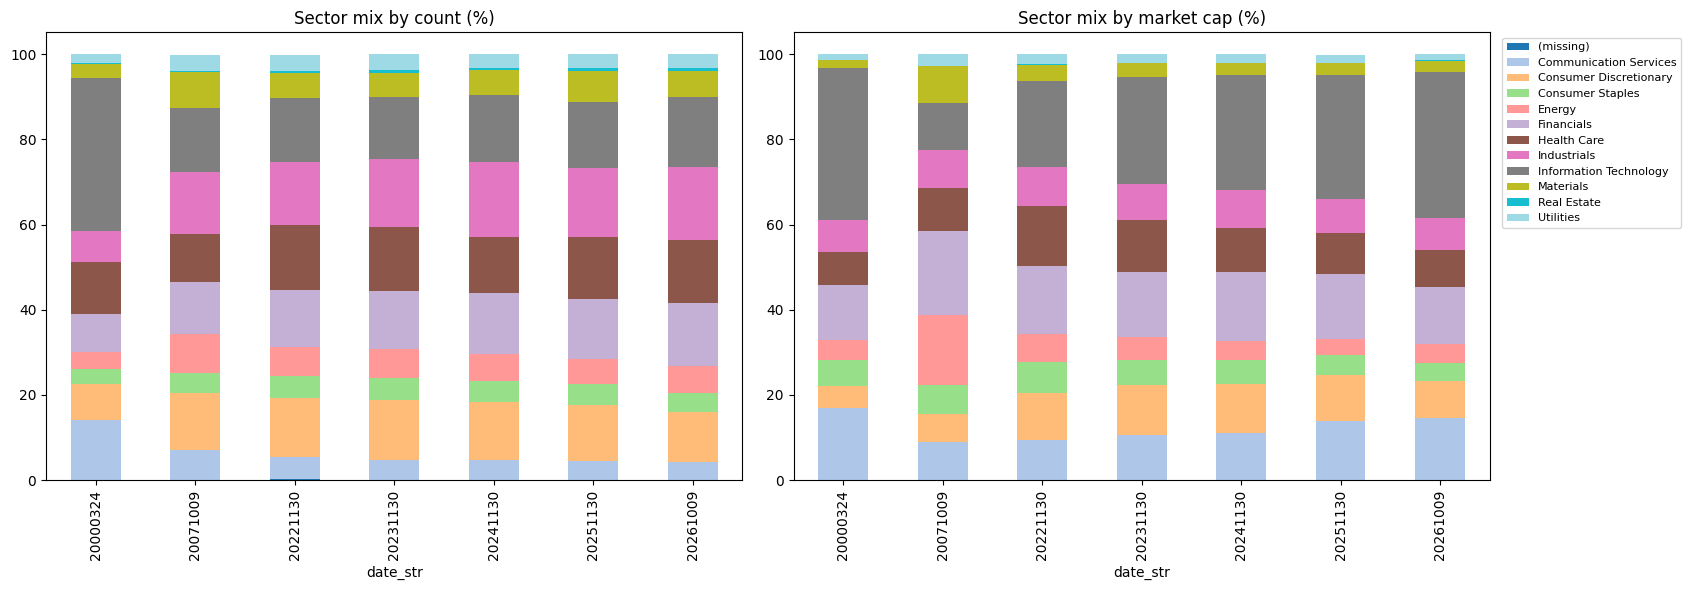

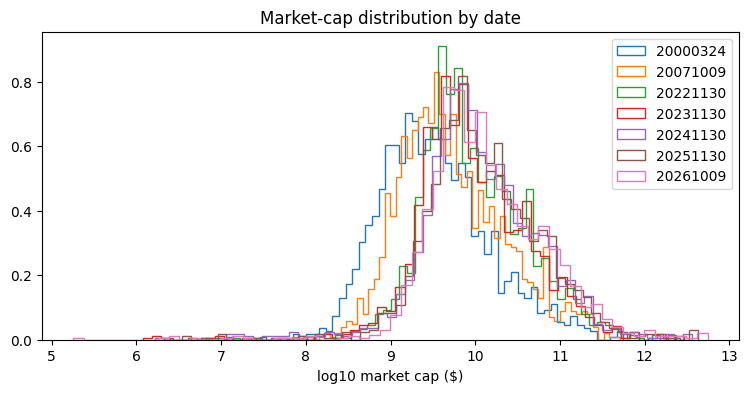

In [ ]:
mix = (pd.crosstab(panel.date_str, panel.sector.fillna("(missing)"), normalize="index") * 100).round(1).T
capmix = (panel.groupby(["date_str", panel.sector.fillna("(missing)")])["mcap"].sum()
          / panel.groupby("date_str")["mcap"].sum() * 100).unstack(0).round(1)
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
mix.T.plot.bar(stacked=True, ax=axes[0], legend=False, colormap="tab20"); axes[0].set_title("Sector mix by count (%)")
capmix.T.plot.bar(stacked=True, ax=axes[1], colormap="tab20"); axes[1].set_title("Sector mix by market cap (%)")
axes[1].legend(bbox_to_anchor=(1.01, 1), fontsize=8); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(9, 4))
for d in DATES:
    ax.hist(np.log10(panel.loc[panel.date_str == d, "mcap"].dropna()), bins=60, histtype="step", label=d, density=True)
ax.set_xlabel("log10 market cap ($)"); ax.legend(); ax.set_title("Market-cap distribution by date"); plt.show()
capmix

**How different is 2000 from 2025?**
* **Size:** total market cap of our universe was \$17.4tn in 2000 and \$26.9tn in 2007, against \$86.0tn in 2025, so the
  2000 market was about **a fifth** of 2025's. The median stock was \$2.9bn (2000) against \$10.6bn (2025). Any feature in
  raw dollars would put a 2000 stock in the wrong place, so we use logs, ratios and within-date shares (Part 3.1).
* **Sector mix by market cap:** in 2000, Information Technology (35.8%) and Communication Services (16.9%) were over
  half the market, the dot-com bubble. In 2007, Financials (19.6%) and Energy (16.4%) were the largest. 2025 looks more
  like 2000 than 2007: IT 29.0% plus Communication Services 14.0%.
* **Coverage:** only 1,399 of 1,600 stocks have a market cap in 2000 (88%), against about 1,595 in 2025.

### Each MAC3 factor against its closest PORT US twin in 2025
The twin is chosen on the **training years only** (largest absolute Spearman among the nine PORT US factors); the
2025 column then shows how close they are out of sample. This same twin is used as the Part 2 baseline.

In [ ]:
NAME_TWIN = {"mac3_dvd_yld": "us_dvd_yld", "mac3_value": "us_val", "mac3_prof": "us_prof", "mac3_vol": "us_vol",
             "mac3_var": "us_earn_var", "mac3_gwth": "us_gr", "mac3_size": "us_sz", "mac3_mom": "us_mom",
             "mac3_lvrg": "us_lev", "mac3_mid_cap": "us_sz"}
twin_rows = []
for f in MAC3:
    cors = {u: spearmanr(train[f], train[u], nan_policy="omit")[0] for u in US}
    best = max(cors, key=lambda u: abs(cors[u]))
    t25 = panel[panel.date_str == "20251130"]
    name_twin = NAME_TWIN.get(f)
    twin_rows.append({"mac3": f, "name twin": name_twin or "-",
                      "name-twin train spearman": cors[name_twin] if name_twin else np.nan,
                      "twin": best, "train spearman": cors[best],
                      "2025 spearman": spearmanr(t25[f], t25[best], nan_policy="omit")[0]})
twins = pd.DataFrame(twin_rows).set_index("mac3")
twins["relationship"] = pd.cut(twins["2025 spearman"].abs(), [0, .5, .8, .95, 1.01],
                               labels=["new information", "related", "close", "nearly the same"])
TWIN = twins["twin"].to_dict()
twins.round(3).sort_values("2025 spearman", key=abs, ascending=False)

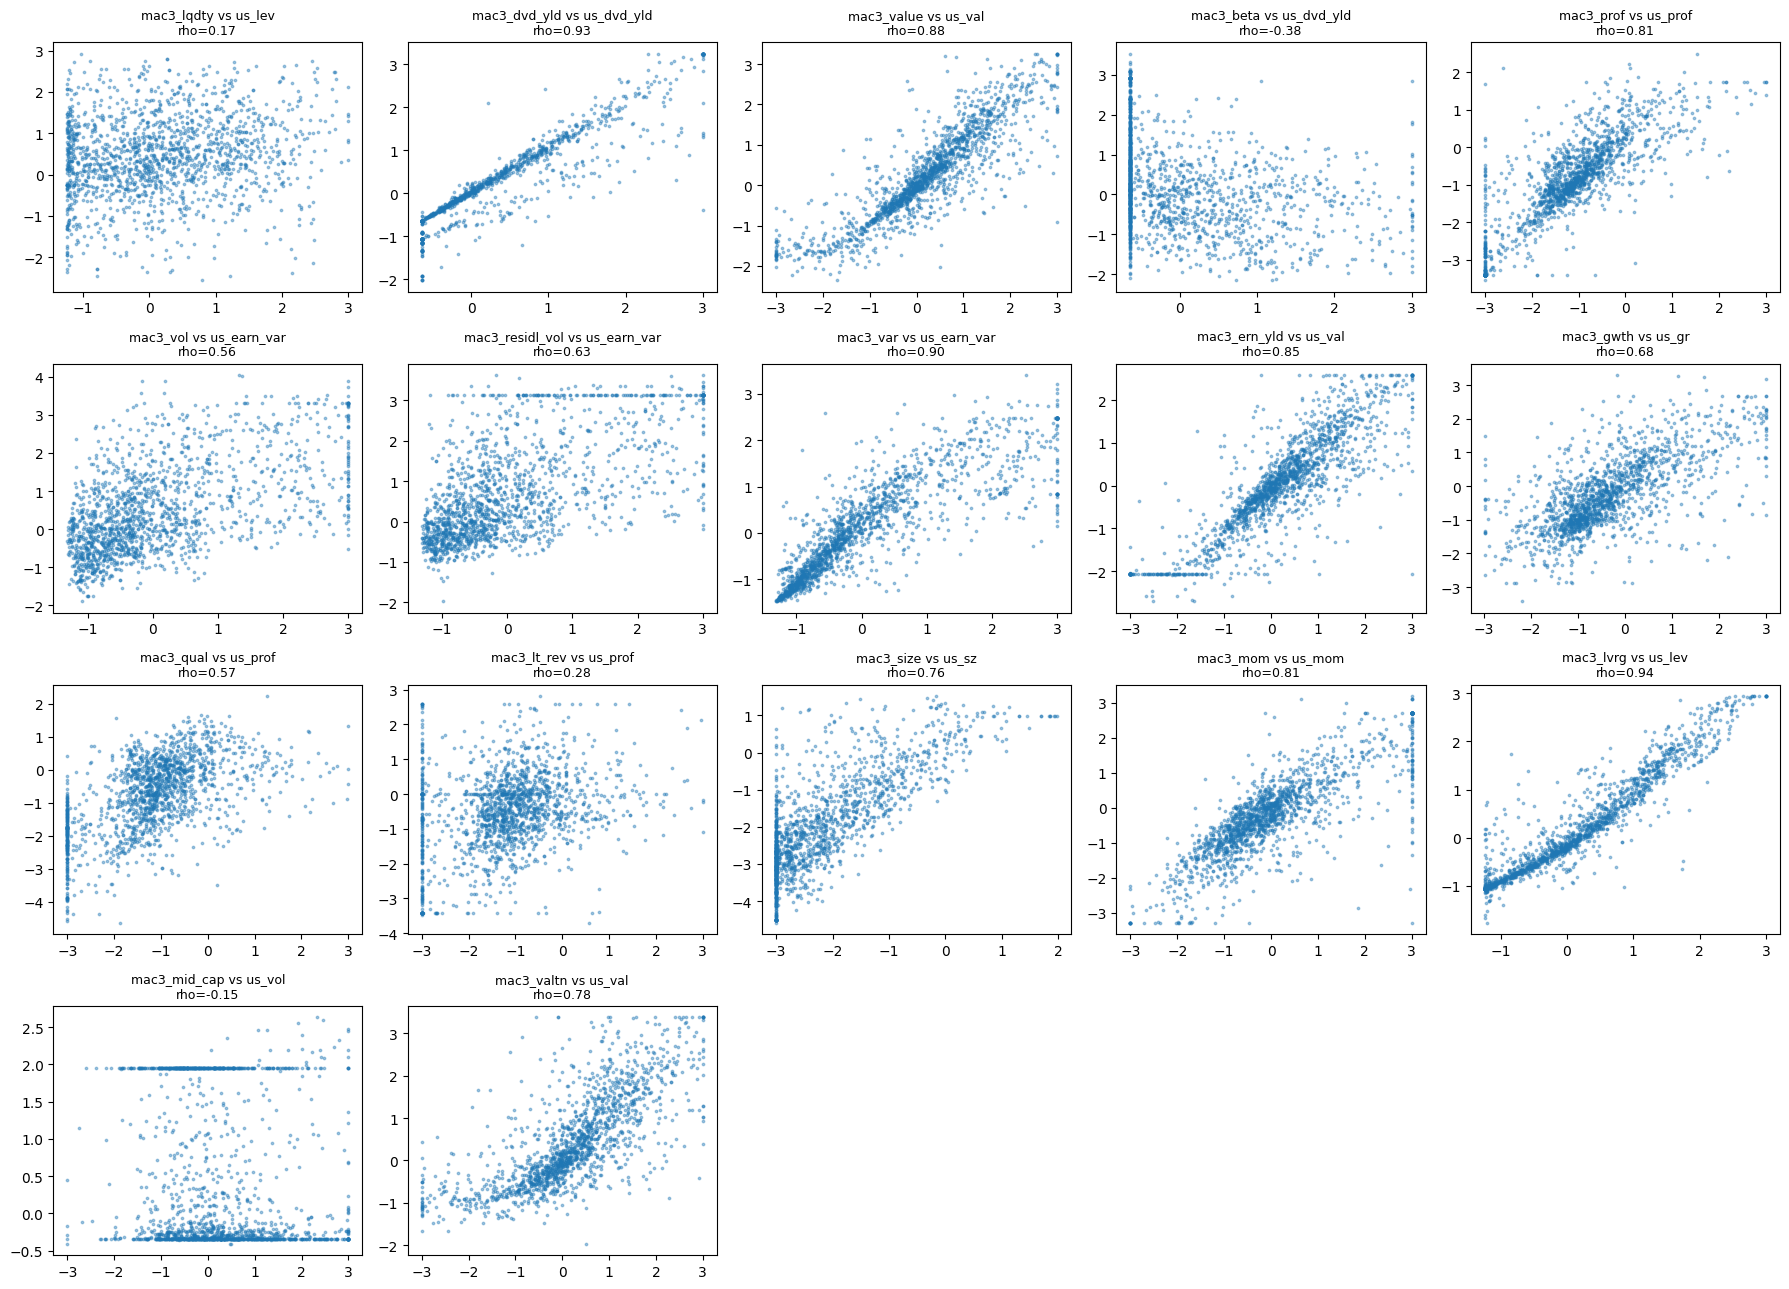

In [ ]:
fig, axes = plt.subplots(4, 5, figsize=(18, 13)); axes = axes.ravel()
t25 = panel[panel.date_str == "20251130"]
for ax, f in zip(axes, MAC3):
    ax.scatter(t25[TWIN[f]], t25[f], s=3, alpha=.4)
    ax.set_title(f"{f} vs {TWIN[f]}\nrho={twins.loc[f,'2025 spearman']:.2f}", fontsize=9)
for ax in axes[len(MAC3):]: ax.axis("off")
plt.tight_layout(); plt.show()

**Which MAC3 factors are nearly a relabelled PORT US factor, and which carry new information?** (2025 Spearman with the
twin chosen on 2022 to 2024)
* **Close (0.80 to 0.95):** Leverage (0.94, `us_lev`), Dividend Yield (0.93), Earnings Variability (0.90), Value (0.88),
  Earnings Yield (0.85, `us_val`), Profitability (0.81), Momentum (0.81). None reaches 0.95, so even these are not
  copies.
* **Related (0.50 to 0.80):** Valuation, Size (0.76: MAC3 Size is not just PORT US Size), Growth, Residual Volatility,
  Quality, Volatility.
* **New information (below 0.50):** Beta (−0.38, and its best twin is Dividend Yield, not a volatility factor),
  Long-Term Reversal (0.28), Liquidity (0.17), Mid Cap (−0.15).

Two surprises: MAC3 Volatility's closest twin is **PORT US Earnings Variability** (0.52), not PORT US Volatility (0.46);
and MAC3 Mid Cap is unrelated to PORT US Size (0.05) even though both are about size, because Mid Cap is a hump (high only
in the middle), which a straight-line size measure cannot capture. These four new-information factors are where we expect
the models to struggle.

### `total_return` in each crash

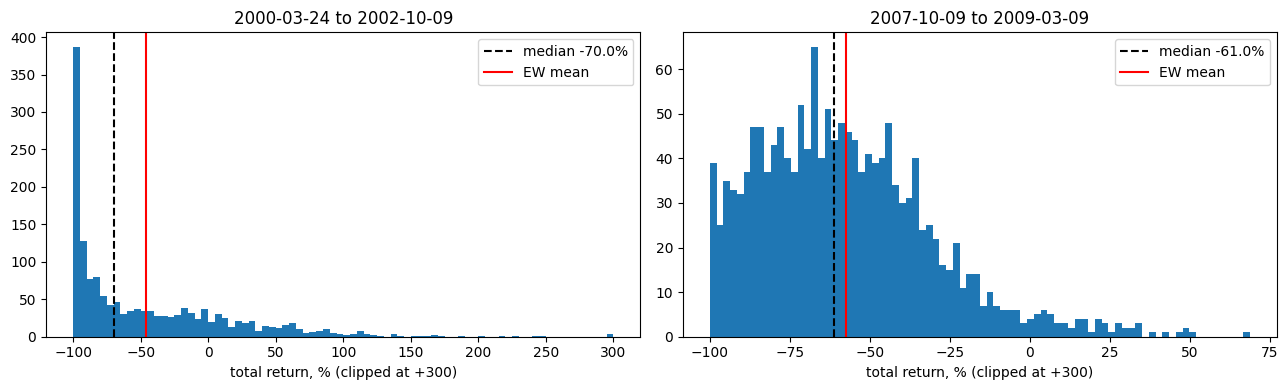

In [ ]:
tr_tab = panel[panel.date_str.isin(PEAKS)].groupby("date_str")["total_return"].agg(
    stocks_with_return="count", missing=lambda s: s.isna().sum(), median="median", equal_weighted_mean="mean",
    share_fell_50pct=lambda s: (s < -50).mean() * 100, share_fell_90pct=lambda s: (s < -90).mean() * 100).round(2)
tr_tab.index = ["2000-03-24 to 2002-10-09", "2007-10-09 to 2009-03-09"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, d, lab in zip(axes, PEAKS, tr_tab.index):
    x = panel.loc[panel.date_str == d, "total_return"].dropna().clip(upper=300)
    ax.hist(x, bins=80); ax.axvline(x.median(), color="k", ls="--", label=f"median {x.median():.1f}%")
    ax.axvline(panel.loc[panel.date_str == d, "total_return"].mean(), color="r", label="EW mean")
    ax.set_title(lab); ax.legend(); ax.set_xlabel("total return, % (clipped at +300)")
plt.tight_layout(); plt.show()
tr_tab

In [ ]:
pd.concat({d: panel[panel.date_str == d].groupby("sector")["total_return"].agg(["count", "median", "mean"]).round(1)
           for d in PEAKS}, axis=1)

**`total_return` in each crash.**

| Crash | Stocks with a return | Missing | Median stock | Equal-weighted mean | Fell > 50% | Fell > 90% |
|---|---|---|---|---|---|---|
| 2000-03-24 to 2002-10-09 | 1,539 | 47 | **−70.0%** | **−46.1%** | 57.9% | 32.5% |
| 2007-10-09 to 2009-03-09 | 1,540 | 30 | **−61.0%** | **−57.6%** | 63.3% | 10.0% |

* Both equal-weighted means match the brief (about −46% and −58%). These are the benchmarks every Part 5 basket must
  beat: "my riskiest stocks fell" proves nothing when the average stock fell this much.
* **2000:** the median (−70%) is far below the mean (−46%) because a few stocks rose a lot (a long right tail). The damage
  was concentrated: IT median −92.6% and Communication Services −89.7%, while Consumer Staples (+29.5%), Utilities
  (+8.3%) and Financials (−7.7%) held up. A third of all stocks lost more than 90%.
* **2007:** the damage was broad. Every sector fell, Financials (median −69.6%) and Consumer Discretionary (−70.3%) the
  most, and even defensive Consumer Staples lost 44%. Fewer stocks were wiped out (10% fell > 90%), but more fell by half.
* The 47 and 30 stocks with no return at all stay in the panel for imputation, and are dropped only in Parts 5 and 6.

# Part 2: Baseline and Validation Framework  *(Member A: Muhammad Talha Khan)*

**Walk-forward, never random.** A stock's MAC3 exposures barely change from one year to the next (Part 1.7: the
year-to-year rank correlation of the same stock is above 0.85 for 11 of the 17 factors). A random 80/20 split puts
Apple-2023 in the training set and Apple-2024 in the test set, so the model can simply recognise the stock, and the
score says nothing about a year it has never seen, which is exactly the 2000 and 2007 situation. So:

| Split | Train on | Test on |
|---|---|---|
| `2025` | 2022-11-30, 2023-11-30, 2024-11-30 | 2025-11-30 |
| `2026` | 2022 to 2025 | 2026-10-09 |

Every learned quantity (clip bounds, medians, scaler, alpha, feature choices, model choice) is fit on the training
rows of a split only. Within-date transforms that use only that date's own features (ranks, cumulative market-cap share)
are allowed, because they can be computed in 2000 too.

## 2.1 Walk-forward splits and 2.2 Spearman scoring

In [ ]:
SPLITS = {"2025": (TRAIN_YEARS, "20251130"), "2026": (TRAIN_YEARS + ["20251130"], "20261009")}

def split_frames(split):
    tr_years, te_year = SPLITS[split]
    return panel[panel.date_str.isin(tr_years)].copy(), panel[panel.date_str == te_year].copy()

def spearman_score(y_true, y_pred):
    """Spearman rank correlation on the rows where the true MAC3 value exists."""
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    ok = ~np.isnan(y_true) & ~np.isnan(y_pred)
    return spearmanr(y_true[ok], y_pred[ok])[0]

for s, (tr_y, te_y) in SPLITS.items():
    tr, te = split_frames(s)
    assert not set(tr.date_str) & set(te.date_str)
    print(f"split {s}: train {sorted(tr.date_str.unique())} ({len(tr)} rows) -> test {te_y} ({len(te)} rows); "
          f"overlap of dates: {set(tr.date_str) & set(te.date_str) or 'none'}")

## 2.3 Twin baseline
For each MAC3 factor: a one-variable linear fit on its closest PORT US twin, chosen on the 2022 to 2024 training years in
Part 1. A blank twin is filled with the training median. Because the fit is monotone, its Spearman is just the rank
correlation of the twin with the factor (with the sign learned in training), which is what "beating the old model's own
factor" means.

In [ ]:
from sklearn.linear_model import LinearRegression

def twin_baseline(split, f):
    tr, te = split_frames(split)
    u = TWIN[f]
    t = tr.dropna(subset=[f])
    med = t[u].median()
    lr = LinearRegression().fit(t[[u]].fillna(med), t[f])
    return lr.predict(te[[u]].fillna(med)), te[f].values

RESULTS = []          # every (factor, model, split) score lands here and becomes spearman_by_factor.csv
def record(f, model, split, score, **extra):
    RESULTS.append({"factor": f, "model": model, "test_year": split, "spearman": score, **extra})

for f in MAC3:
    for s in SPLITS:
        pred, y = twin_baseline(s, f)
        record(f, "twin baseline", s, spearman_score(y, pred), twin=TWIN[f])
baseline = (pd.DataFrame(RESULTS).pivot_table(index="factor", columns="test_year", values="spearman")
            .join(pd.Series(TWIN, name="twin")).reindex(MAC3))
baseline.loc["MEAN"] = baseline[["2025", "2026"]].mean()
baseline.round(3)

The twin baseline averages **0.651 in 2025 and 0.540 in 2026** across the 17 factors, in line with the Week 7 reality
check (about 0.60).
* **Very strong** where MAC3 is close to a relabelled PORT US factor: Leverage (0.94 / 0.87), Dividend Yield
  (0.93 / 0.89), Earnings Variability (0.90 / 0.84), Value (0.88 / 0.78).
* **Close to useless** where MAC3 measures something PORT US never had: Liquidity (0.17 / 0.12), Mid Cap (0.15 / 0.15),
  Long-Term Reversal (0.28 / 0.09).
* **Momentum collapses in 2026:** 0.806 in 2025 but **0.038** in 2026. On 2026-10-09 the PORT US and MAC3 momentum
  rankings disagree almost completely, presumably because the two models measure momentum over different windows,
  which matters most when the market turns. Momentum is also the least persistent factor (Part 1.7). A twin can look
  safe in one year and fail in the next; only a second test year shows it.

**Every model in Part 3 has to beat this number, factor by factor.**

# Part 3: Imputation Models for all 17 MAC3 factors  *(Member B: Zain Ul Abideen)*

## 3.1 Engineered features
Raw dollars do not compare across years (the 2000 market was a fifth of 2025's), so we turn them into ratios, logs and
within-date shares:

| Feature | Definition | Why |
|---|---|---|
| `log_mcap` | log(market cap) | size on a usable scale |
| `log_traded_val` | log(traded value) | dollar liquidity |
| `turnover` | log(traded value / market cap) | liquidity per dollar of company |
| `share_growth` | shares out / shares out a year ago − 1 | dilution or buybacks |
| `buyback_yield` | value repurchased this year / market cap | buybacks |
| `employee_growth` | log(employees / employees 5 years ago) | real growth |
| `log_employees` | log(employees) | real size |
| `ep, fwd_ep, bp, fwd_bp, sp, fwd_sp` | 1 / (P/E, forward P/E, P/B, ...) | yields stay finite and monotone when earnings are near zero or negative |
| sector dummies | one column per GICS sector | |

**Features built from the definition (3.5):**
* `cum_share`: within each date, sort by market cap and take each stock's cumulative share of the date's total market
  cap. `midcap_band` = 1 when `cum_share` is inside the band where MAC3 Mid Cap is high (edges set on the training years below).
* `size_rel`: log market cap minus that date's average log market cap. Same idea as `log_mcap`, but it means the same
  thing in the much smaller market of 2000. *(our own feature, for Size)*
* `px3`: an implied 3-year price change, log(|FCF yield 3 years ago| / |FCF yield now|) when the two have the same sign.
  FCF yield is FCF / price, so with stable cash flow this ratio moves with the price over 3 years, the only long-horizon price
  information in the files. *(our own feature, for Long-Term Reversal)*

In [ ]:
def add_features(df):
    df = df.copy()
    pos = lambda s: s.where(s > 0)
    df["log_mcap"] = np.log(pos(df["mcap"]))
    df["log_traded_val"] = np.log(pos(df["traded_val"]))
    df["turnover"] = np.log(pos(df["traded_val"] / df["mcap"]))
    df["share_growth"] = df["shares_out"] / df["shares_out_y1"].where(df["shares_out_y1"] > 0) - 1
    df["buyback_yield"] = df["buyback_val"] / pos(df["mcap"])
    df["employee_growth"] = np.log(pos(df["employees"]) / pos(df["employees_5y"]))
    df["log_employees"] = np.log1p(df["employees"].clip(lower=0))
    for r, y in [("pe", "ep"), ("fwd_pe", "fwd_ep"), ("pb", "bp"), ("fwd_pb", "fwd_bp"), ("ps", "sp"), ("fwd_ps", "fwd_sp")]:
        df[y] = 1.0 / df[r].where(df[r].abs() > 1e-6)
    # within-date features: they use only the date's own market caps, so they can be computed in 2000 as well
    df["cum_share"] = np.nan
    df["size_rel"] = np.nan
    for d, g in df.groupby("date_str"):
        g = g.dropna(subset=["mcap"]).sort_values("mcap", ascending=False)
        df.loc[g.index, "cum_share"] = g["mcap"].cumsum() / g["mcap"].sum()
        df.loc[g.index, "size_rel"] = np.log(g["mcap"]) - np.log(g["mcap"]).mean()
    same = np.sign(df["fcf_yld_q12"]) == np.sign(df["fcf_yld"])
    df["px3"] = np.where(same & (df["fcf_yld"].abs() > 1e-6) & (df["fcf_yld_q12"].abs() > 1e-6),
                         np.log(df["fcf_yld_q12"].abs()) - np.log(df["fcf_yld"].abs()), np.nan)
    return df

panel = add_features(panel)
SECTORS = sorted(panel.loc[panel.date_str.isin(TRAIN_YEARS), "sector"].dropna().unique())
for s_ in SECTORS:
    panel["sec_" + s_.replace(" ", "_")] = (panel["sector"] == s_).astype(float)
SEC_COLS = ["sec_" + s_.replace(" ", "_") for s_ in SECTORS]

BASE_NUM = US + ["beta", "ret_1y", "ret_3m", "insider_sells", "roe", "fcf_yld", "fcf_yld_y", "fcf_yld_y1", "fcf_yld_q12",
                 "debt_growth_3y", "fa_turnover", "fa_turnover_growth_5y", "stox_quality", "stox_leverage", "stox_lowvol",
                 "stox_prof", "stox_multi", "stox_mom", "ep", "fwd_ep", "bp", "fwd_bp", "sp", "fwd_sp"]
ENG = ["log_mcap", "log_traded_val", "turnover", "share_growth", "buyback_yield", "employee_growth", "log_employees"]
print(len(BASE_NUM), "base numeric features,", len(ENG), "engineered,", len(SEC_COLS), "sector dummies")
print("Left out on purpose: capex_fwd / capex_fwd_q4 (0% filled in 2000, 2.5% in 2007) and buyback_px (0.3% in 2000).")


### Choosing the mid-cap band (training years only)


In [ ]:
trn = panel[panel.date_str.isin(TRAIN_YEARS)]
band_tab = trn.groupby(pd.cut(trn["cum_share"], [0, .5, .7, .75, .8, .82, .84, .86, .88, .9, .92, .94, .96, .97, .98, 1]),
                       observed=True)["mac3_mid_cap"].agg(["count", "mean", "std"]).round(2)
print(band_tab)
grid = [(lo, hi) for lo in np.arange(0.78, 0.90, 0.01) for hi in np.arange(0.93, 0.995, 0.005)]
band_score = {(lo, hi): spearmanr(trn["mac3_mid_cap"], trn["cum_share"].between(lo, hi), nan_policy="omit")[0] for lo, hi in grid}
BAND = max(band_score, key=band_score.get)
print(f"\nchosen band on 2022-2024: cum_share in [{BAND[0]:.3f}, {BAND[1]:.3f}]  (Spearman of the 0/1 band with Mid Cap = {band_score[BAND]:.3f})")
panel["midcap_band"] = panel["cum_share"].between(*BAND).astype(float).where(panel["cum_share"].notna())
# a smooth version too: 1 at the band centre, falling to 0 at its edges and beyond
c, h = (BAND[0] + BAND[1]) / 2, (BAND[1] - BAND[0]) / 2
panel["midcap_bump"] = (1 - ((panel["cum_share"] - c) / h).abs()).clip(lower=0)
DEF = ["cum_share", "midcap_band", "midcap_bump", "size_rel", "px3"]
NUM = BASE_NUM + ENG + DEF
print("total numeric features:", len(NUM))

Note that the band edges were chosen on 2022 to 2024 only. For the 2026 split the same edges are reused; they are a
within-date share, so they transfer to any year, including 2000.

## 3.2 Preprocessing, fit on the training rows only
Clip each feature at its training 1st and 99th percentiles, fill blanks with the training median, add a 0/1
missing flag for every feature that has blanks in training, and standardise with the training mean and standard deviation.

In [ ]:
class Prep:
    """Clip -> median fill -> missing flags -> scale. Every statistic comes from the rows passed to fit()."""
    def __init__(self, num, cat=SEC_COLS, flags=True):
        self.num, self.cat, self.flags = list(num), list(cat), flags
    def fit(self, df):
        X = df[self.num].astype(float)
        self.lo, self.hi = X.quantile(0.01), X.quantile(0.99)
        Xc = X.clip(self.lo, self.hi, axis=1)
        self.med = Xc.median().fillna(0)
        self.flag_cols = [c for c in self.num if X[c].isna().any()] if self.flags else []
        Xf = Xc.fillna(self.med)
        self.mu, self.sd = Xf.mean(), Xf.std().replace(0, 1).fillna(1)
        return self
    def transform(self, df):
        X = df[self.num].astype(float).clip(self.lo, self.hi, axis=1)
        flags = X[self.flag_cols].isna().astype(float).add_suffix("_na")
        Z = (X.fillna(self.med) - self.mu) / self.sd
        out = pd.concat([Z, flags, df[self.cat].fillna(0).astype(float)], axis=1)
        return out
    @property
    def names(self):
        return self.num + [c + "_na" for c in self.flag_cols] + self.cat

# leakage check: statistics come from 2022-2024 rows only
tr_, te_ = split_frames("2025")
_p = Prep(NUM).fit(tr_)
print("median of log_mcap used for filling:", round(_p.med["log_mcap"], 3),
      "| 2022-24 median:", round(tr_["log_mcap"].clip(_p.lo["log_mcap"], _p.hi["log_mcap"]).median(), 3),
      "| 2025 median (not used):", round(te_["log_mcap"].median(), 3))
print("columns after preprocessing:", len(_p.names), f"({len(NUM)} numeric + {len(_p.flag_cols)} flags + {len(SEC_COLS)} sectors)")

## 3.3 Linear family: OLS, Ridge, Lasso
Alpha is chosen by **leave-one-year-out** on the training years: hold out one training year, fit on the others, score
Spearman on the held-out year, average over the held-out years, and pick the alpha with the best average.
The final model is then refit on all training years with that alpha.

In [ ]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures

RIDGE_ALPHAS = [0.1, 1, 10, 100, 1000, 3000, 10000]
LASSO_ALPHAS = [0.1, 0.03, 0.01, 0.003, 0.001, 0.0003]

class Poly2:
    """Every numeric feature squared and every pair multiplied; flags and sector dummies appended unchanged."""
    def __init__(self, n_num):
        self.n_num = n_num
        self.pf = PolynomialFeatures(2, include_bias=False)
    def fit(self, X):
        self.pf.fit(X[:, :self.n_num]); return self
    def transform(self, X):
        return np.hstack([self.pf.transform(X[:, :self.n_num]), X[:, self.n_num:]])

def design(tr, te, num, poly=False):
    p = Prep(num).fit(tr)
    Xtr, Xte = p.transform(tr).values, p.transform(te).values
    if poly:
        pe = Poly2(len(num)).fit(Xtr)
        Xtr, Xte = pe.transform(Xtr), pe.transform(Xte)
        # re-standardise the products on the training rows
        mu, sd = Xtr.mean(0), Xtr.std(0); sd[sd == 0] = 1
        Xtr, Xte = (Xtr - mu) / sd, (Xte - mu) / sd
    return Xtr, Xte

def fit_linear(kind, alpha, X, y):
    if kind == "ols":
        return LinearRegression().fit(X, y)
    if kind == "ridge":
        return Ridge(alpha=alpha).fit(X, y)
    return Lasso(alpha=alpha, max_iter=3000, tol=1e-3, precompute=True, selection="cyclic").fit(X, y)

def loyo_alpha(kind, alphas, tr, f, num, poly):
    """Leave-one-training-year-out Spearman for each alpha; returns best alpha and the CV table."""
    years = sorted(tr.date_str.unique())
    cv = {a: [] for a in alphas}
    for hold in years:
        a_tr, a_va = tr[(tr.date_str != hold) & tr[f].notna()], tr[(tr.date_str == hold) & tr[f].notna()]
        Xa, Xv = design(a_tr, a_va, num, poly)
        for a in alphas:
            m = fit_linear(kind, a, Xa, a_tr[f].values)
            cv[a].append(spearman_score(a_va[f], m.predict(Xv)))
    cv = {a: np.mean(v) for a, v in cv.items()}
    return max(cv, key=cv.get), cv

def run_linear(f, split, kind, num, poly=False, tag=""):
    tr, te = split_frames(split)
    tr = tr[tr[f].notna()]
    alpha, cv = (None, {None: np.nan})
    if kind != "ols":
        alpha, cv = loyo_alpha(kind, RIDGE_ALPHAS if kind == "ridge" else LASSO_ALPHAS, tr, f, num, poly)
    Xtr, Xte = design(tr, te, num, poly)
    m = fit_linear(kind, alpha, Xtr, tr[f].values)
    pred = m.predict(Xte)
    name = {"ols": "OLS", "ridge": "Ridge", "lasso": "Lasso"}[kind] + (" deg2" if poly else "") + tag
    extra = {"alpha": alpha, "loyo_cv": cv[alpha], "n_cols": Xtr.shape[1],
             "train_spearman": spearman_score(tr[f], m.predict(Xtr))}
    if kind == "lasso":
        extra["n_kept"] = int((np.abs(m.coef_) > 1e-8).sum())
    record(f, name, split, spearman_score(te[f], pred), **extra)
    return m, pred

import time
t0 = time.time()
for f in MAC3:
    for s in SPLITS:
        for kind in ["ols", "ridge", "lasso"]:
            run_linear(f, s, kind, BASE_NUM + ENG, tag=" (no def. feat.)")
            run_linear(f, s, kind, NUM)
print(f"linear family done in {time.time()-t0:.0f}s")
R = pd.DataFrame(RESULTS)
lin = R[R.model.isin(["OLS", "Ridge", "Lasso"])]
lin_tab = lin.pivot_table(index="factor", columns=["model", "test_year"], values="spearman").reindex(MAC3)
lin_tab.loc["MEAN"] = lin_tab.mean()
lin_tab.round(3)

In [ ]:
print("Lasso: alpha chosen by LOYO and number of features kept (out of", int(lin.n_cols.max()), "columns)")
lasso_kept = (R[R.model == "Lasso"].pivot_table(index="factor", columns="test_year", values=["alpha", "n_kept"])
              .reindex(MAC3))
lasso_kept

## 3.4 The degree-2 expansion
Every numeric feature squared and every pair multiplied, plus the flags and sectors: this lets a linear model bend
(Mid Cap is a hump in size, not a line). With 45 numeric features this gives 45 originals + 45 squares + 990 pairwise
products = 1,080 columns, plus 42 missing flags and 11 sector dummies = **1,133 columns** (the brief's "about 870" assumes
fewer base features). With 1,133 columns and about 4,800 training rows, plain OLS has room to memorise.

In [ ]:
t0 = time.time()
for f in MAC3:
    for s in SPLITS:
        for kind in ["ols", "ridge", "lasso"]:
            run_linear(f, s, kind, NUM, poly=True)
print(f"degree-2 family done in {time.time()-t0:.0f}s")
R = pd.DataFrame(RESULTS)
poly_models = ["OLS", "Ridge", "Lasso", "OLS deg2", "Ridge deg2", "Lasso deg2"]
pt = R[R.model.isin(poly_models)]
deg2_tab = pt.pivot_table(index="factor", columns=["model"], values="spearman", aggfunc="mean").reindex(MAC3)[poly_models]
deg2_tab.loc["MEAN"] = deg2_tab.mean()
print("Spearman, average of the 2025 and 2026 test years")
deg2_tab.round(3)

In [ ]:
ovf = pt.groupby("model")[["train_spearman", "spearman", "n_cols"]].mean().reindex(poly_models)
ovf.columns = ["train Spearman (in-sample)", "test Spearman", "columns"]
ovf["gap"] = ovf.iloc[:, 0] - ovf.iloc[:, 1]
print("Overfitting check, averaged over 17 factors and both test years:")
print(ovf.round(3))
print("\nLasso deg2 features kept:")
R[R.model == "Lasso deg2"].pivot_table(index="factor", columns="test_year", values=["alpha", "n_kept"]).reindex(MAC3)

**Where OLS overfits, and how much Ridge and Lasso recover** (averages over 17 factors and both test years):

| Model | Columns | Train Spearman | Test Spearman | Gap |
|---|---|---|---|---|
| OLS / Ridge / Lasso | 98 | 0.879 | 0.846 to 0.848 | 0.03 |
| OLS deg2 | 1,133 | **0.929** | **0.814** | **0.114** |
| Ridge deg2 | 1,133 | 0.916 | 0.854 | 0.061 |
| Lasso deg2 | 1,133 | 0.904 | **0.862** | 0.042 |

* **OLS deg2 overfits:** it has the best training score and the worst test score, below even plain OLS on 98 columns.
  It hurts most on the factors that change from year to year or have little signal: Momentum (0.753 against 0.839 for
  plain OLS), Growth (0.641 against 0.705), Long-Term Reversal (0.430 against 0.494), Beta (0.856 against 0.913).
* **Regularisation recovers it, and more:** Ridge deg2 halves the gap, and Lasso deg2 (gap 0.042) is the best linear
  model overall, 0.014 above plain Lasso. Lasso keeps only 27 of 1,133 columns for Mid Cap and 34 to 153 for Beta, but
  about 590 for Long-Term Reversal, where no small set of features explains the factor.
* **The curve pays off where the factor is curved:** Mid Cap (Ridge deg2 0.831 against 0.766 for plain Ridge),
  Long-Term Reversal (0.542 against 0.490), Profitability (0.894 against 0.865).

## 3.5 Features built from the definition: the gain factor by factor
Same Ridge model, with and without `cum_share`, `midcap_band`, `midcap_bump`, `size_rel` and `px3`.

In [ ]:
gain = R[R.model.isin(["Ridge", "Ridge (no def. feat.)"])].pivot_table(
    index="factor", columns=["model", "test_year"], values="spearman").reindex(MAC3)
g = pd.DataFrame({f"gain {s}": gain[("Ridge", s)] - gain[("Ridge (no def. feat.)", s)] for s in SPLITS})
g = pd.concat([gain.round(3), g.round(3)], axis=1)
g.sort_values("gain 2025", ascending=False)

**The gain from the definition-built features (Ridge, 2025 / 2026):**
* **Mid Cap: +0.256 / +0.329.** Without them Ridge reaches only 0.497 / 0.449; with the mid-cap band it reaches
  0.753 / 0.778. A linear model cannot draw a hump in size on its own, but it can use a 0/1 "inside the band" column.
  This is the Week 7 lesson repeated.
* **Liquidity: +0.030 / +0.018**, and **Long-Term Reversal: +0.016 / +0.021** (our own `px3`, the implied 3-year price
  change): small but positive in both test years.
* **Size: +0.005 / +0.011** (our own `size_rel`).
* **Every other factor: within ±0.004**, as expected, since these features were not designed for them. Adding them did
  not hurt anything.

## 3.6 Tree models: XGBoost and CatBoost
Trees get the features unclipped, unfilled and unscaled (they route blanks on their own), plus the sector as a
category. Hyperparameters are fixed in advance, not tuned on the test years.

In [ ]:
!pip install -q catboost

In [ ]:
import xgboost as xgb
from catboost import CatBoostRegressor

TREE_NUM = NUM
XGB_PARAMS = dict(n_estimators=600, learning_rate=0.03, max_depth=5, subsample=0.8, colsample_bytree=0.8,
                  min_child_weight=5, reg_lambda=1.0, n_jobs=-1, random_state=42)
CAT_PARAMS = dict(iterations=800, learning_rate=0.05, depth=6, l2_leaf_reg=3, random_seed=42, verbose=0, thread_count=-1)

def tree_X(df, num):
    X = df[num].astype(float).copy()
    X["sector"] = df["sector"].fillna("missing").astype(str)
    return X

def fit_tree(kind, tr, f, num):
    t = tr[tr[f].notna()]
    X = tree_X(t, num)
    if kind == "xgb":
        X = pd.concat([X.drop(columns="sector"), t[SEC_COLS]], axis=1)
        return xgb.XGBRegressor(**XGB_PARAMS).fit(X, t[f])
    return CatBoostRegressor(**CAT_PARAMS, cat_features=["sector"]).fit(X, t[f])

def predict_tree(kind, m, df, num):
    X = tree_X(df, num)
    if kind == "xgb":
        X = pd.concat([X.drop(columns="sector"), df[SEC_COLS]], axis=1)
    return m.predict(X)

TREES = {}
t0 = time.time()
for f in MAC3:
    for s in SPLITS:
        tr, te = split_frames(s)
        for kind, name in [("xgb", "XGBoost"), ("cat", "CatBoost")]:
            m = fit_tree(kind, tr, f, TREE_NUM)
            TREES[(f, s, kind)] = m
            t_ = tr[tr[f].notna()]
            record(f, name, s, spearman_score(te[f], predict_tree(kind, m, te, TREE_NUM)),
                   train_spearman=spearman_score(t_[f], predict_tree(kind, m, t_, TREE_NUM)))
print(f"trees done in {time.time()-t0:.0f}s")
R = pd.DataFrame(RESULTS)
ALL_MODELS = ["twin baseline", "OLS", "Ridge", "Lasso", "OLS deg2", "Ridge deg2", "Lasso deg2", "XGBoost", "CatBoost"]
full = R[R.model.isin(ALL_MODELS)].pivot_table(index="factor", columns=["test_year", "model"], values="spearman").reindex(MAC3)
full = full[[(s, m) for s in SPLITS for m in ALL_MODELS]]
full.loc["MEAN"] = full.mean()
full.round(3)

### Feature importances (XGBoost gain, 2025 split): chart for three factors, table for four

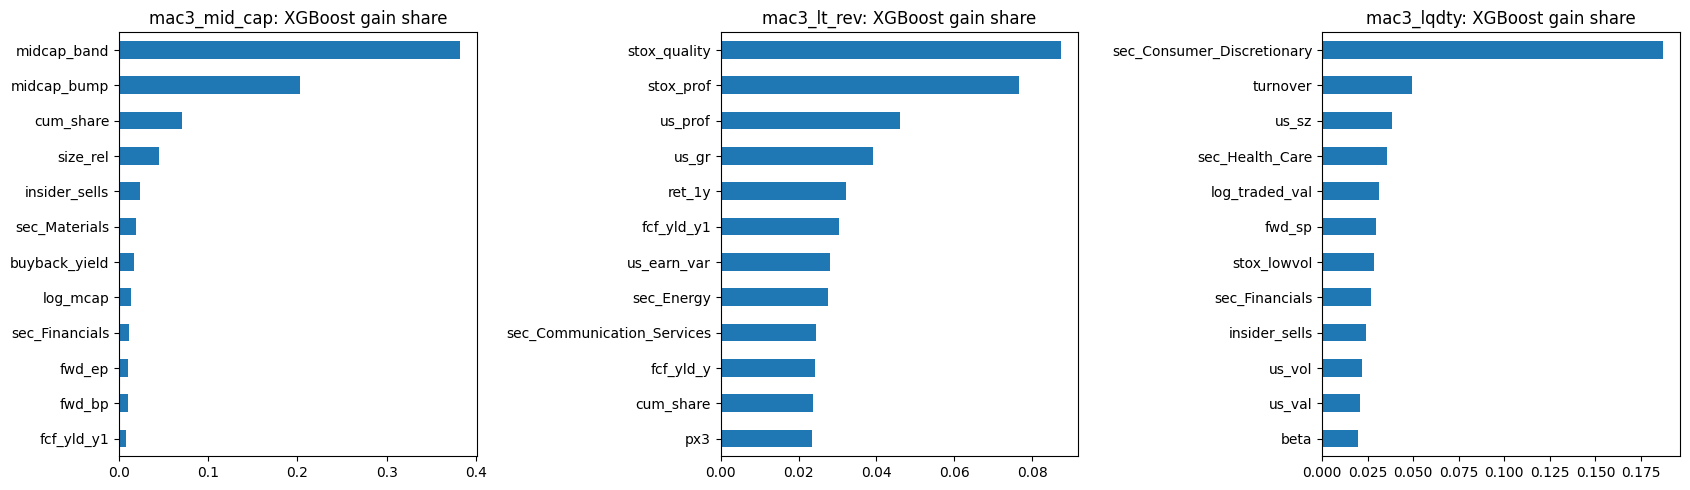

In [ ]:
def importances(f, s="2025", kind="xgb", top=12):
    m = TREES[(f, s, kind)]
    if kind == "xgb":
        imp = pd.Series(m.get_booster().get_score(importance_type="gain"))
    else:
        imp = pd.Series(m.get_feature_importance(), index=m.feature_names_)
    return (imp / imp.sum()).sort_values(ascending=False).head(top)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, f in zip(axes, ["mac3_mid_cap", "mac3_lt_rev", "mac3_lqdty"]):
    imp = importances(f)
    imp[::-1].plot.barh(ax=ax); ax.set_title(f"{f}: XGBoost gain share")
plt.tight_layout(); plt.show()
pd.concat({f: importances(f).round(3).reset_index().rename(columns={"index": "feature", 0: "gain"})
           for f in ["mac3_mid_cap", "mac3_lt_rev", "mac3_lqdty", "mac3_size"]}, axis=1)

**What the trees use:**
* **Mid Cap:** `midcap_band` (38%), `midcap_bump` (20%), `cum_share` (7%) and `size_rel` (5%): about **70% of the gain
  comes from the features built from the definition**.
* **Size:** `cum_share` (37%) and our own `size_rel` (26%) lead; raw `log_mcap` is only 2%. The tree prefers the
  within-date measures, which is good news for 2000, where raw market caps are a fifth of today's.
* **Long-Term Reversal:** no feature dominates; the top one, `stox_quality`, has only 9% and `px3` 2%. The signal is
  spread thinly over many weak proxies, which is why this factor is hard (3.7).
* **Liquidity:** the top feature is a **sector dummy** (Consumer Discretionary, 19%), ahead of `turnover` (5%) and
  `log_traded_val` (3%). The tree leans on sector because our only trading-activity input is a single day's traded
  value. This is a warning for 2000, where 55% of sectors come from the fill file.

### Does the tree still need the engineered feature?
Refit XGBoost without the definition-built features (Mid Cap: `cum_share`, `midcap_band`, `midcap_bump`, `size_rel`;
Long-Term Reversal: `px3`), and once more without any engineered feature at all.

In [ ]:
abl = []
for f, drop in [("mac3_mid_cap", ["cum_share", "midcap_band", "midcap_bump", "size_rel"]), ("mac3_lt_rev", ["px3"]),
                ("mac3_size", ["cum_share", "midcap_band", "midcap_bump", "size_rel"]),
                ("mac3_lqdty", ["turnover", "log_traded_val"])]:
    for s in SPLITS:
        tr, te = split_frames(s)
        full_sc = spearman_score(te[f], predict_tree("xgb", TREES[(f, s, "xgb")], te, TREE_NUM))
        num_wo = [c for c in TREE_NUM if c not in drop]
        m = fit_tree("xgb", tr, f, num_wo)
        sc_wo = spearman_score(te[f], predict_tree("xgb", m, te, num_wo))
        num_raw = BASE_NUM + ["mcap", "traded_val", "shares_out", "shares_out_y1", "employees", "employees_5y", "buyback_val"]
        m2 = fit_tree("xgb", tr, f, num_raw)
        sc_raw = spearman_score(te[f], predict_tree("xgb", m2, te, num_raw))
        abl.append({"factor": f, "test_year": s, "dropped": ", ".join(drop), "XGB all features": full_sc,
                    "XGB without them": sc_wo, "XGB raw dollars, no engineering": sc_raw})
ablation = pd.DataFrame(abl)
ablation["cost of dropping"] = ablation["XGB all features"] - ablation["XGB without them"]
ablation.round(3)

**Does the tree still need the engineered feature? Mostly not, unlike Ridge.**
* **Mid Cap:** dropping the four band features costs XGBoost only 0.009 / 0.011 (0.837 → 0.829, 0.823 → 0.812), against
  0.26 to 0.33 for Ridge. A tree can build the hump itself from market cap with two splits.
* **Long-Term Reversal:** dropping `px3` changes nothing (−0.004 / −0.002, slightly better without it). `px3` helps
  Ridge a little but adds nothing the trees cannot already find.
* **Size:** +0.001 / +0.008. **Liquidity:** mixed, −0.012 in 2025 and +0.025 in 2026.
* **Raw dollars with no engineering** score about the same as the full feature set within 2022 to 2026. That is
  expected: a tree only uses the order of a feature, so taking logs changes nothing.

**Why we keep the engineered features anyway:** the test years all have markets of similar size. In 2000 the market is
a fifth of 2025's, so a tree split at "market cap > \$10bn" would put 2000 stocks on the wrong side. Within-date features
(`cum_share`, `size_rel`) mean the same thing in any year. This score cannot show that difference; Part 4's drift
checks can.

### Why a random 80/20 split overstates accuracy
Same XGBoost, same features, but the 2022 to 2025 rows are shuffled into a random 80/20 split, so the same stock sits in
train and test in neighbouring years.

In [ ]:
from sklearn.model_selection import train_test_split
rnd = []
pool = panel[panel.date_str.isin(TRAIN_YEARS + ["20251130"])]
for f in ["mac3_lqdty", "mac3_lt_rev", "mac3_mid_cap", "mac3_gwth"]:
    p_ = pool[pool[f].notna()]
    a, b = train_test_split(p_, test_size=0.2, random_state=0)
    m = fit_tree("xgb", a, f, TREE_NUM)
    rnd.append({"factor": f, "random 80/20 Spearman": spearman_score(b[f], predict_tree("xgb", m, b, TREE_NUM)),
                "walk-forward 2025": R[(R.factor == f) & (R.model == "XGBoost") & (R.test_year == "2025")].spearman.iloc[0],
                "walk-forward 2026": R[(R.factor == f) & (R.model == "XGBoost") & (R.test_year == "2026")].spearman.iloc[0]})
pd.DataFrame(rnd).round(3)

**The random split flatters every factor**, by 0.02 to 0.07:

| Factor | Random 80/20 | Walk-forward 2025 | Walk-forward 2026 |
|---|---|---|---|
| Liquidity | 0.722 | 0.673 | 0.699 |
| Long-Term Reversal | 0.674 | 0.600 | 0.638 |
| Mid Cap | 0.867 | 0.837 | 0.823 |
| Growth | 0.807 | 0.787 | 0.759 |

With a random split, the same company appears in training and test in neighbouring years, and most MAC3 exposures barely
change from year to year (Part 1.7), so the model partly recognises the stock instead of learning the factor. In 2000
and 2007 every stock is unseen, so only the walk-forward score is an honest estimate, and even that is optimistic
(Part 4).

## 3.7 Diagnose before you tune: easy, curved, hard
* **easy**: the twin alone already gets ≥ 0.85, so MAC3 is close to a relabelled PORT US factor.
* **curved**: the best nonlinear model (degree-2 or trees) beats the best plain linear model by ≥ 0.03, so the shape matters.
* **hard**: even the best model stays below 0.80 on average.

Where a factor qualifies for two groups, "hard" wins, then "curved".

In [ ]:
avg = R.groupby(["factor", "model"])["spearman"].mean().unstack().reindex(MAC3)
diag = pd.DataFrame({
    "twin": avg["twin baseline"],
    "best linear": avg[["OLS", "Ridge", "Lasso"]].max(axis=1),
    "best deg2 / tree": avg[["Ridge deg2", "Lasso deg2", "XGBoost", "CatBoost"]].max(axis=1),
    "best overall": avg[ALL_MODELS].max(axis=1),
    "train-year persistence": mac3_dist["yr-to-yr rank corr (same stock)"],
})
diag["curve gain"] = diag["best deg2 / tree"] - diag["best linear"]
diag["group"] = np.where(diag["best overall"] < 0.80, "hard",
                np.where(diag["curve gain"] >= 0.03, "curved", np.where(diag["twin"] >= 0.85, "easy", "moderate")))
diag.round(3).sort_values("best overall")

**The diagnosis** (best model, average of 2025 and 2026):
* **Easy:** Dividend Yield (twin 0.91), Earnings Variability (0.87), Leverage (0.91): nearly relabelled PORT US factors.
* **Curved:** Mid Cap (+0.048 from going nonlinear), Profitability (+0.072), Quality (+0.037), Valuation (+0.037),
  Earnings Yield (+0.033).
* **Moderate:** Value, Size, Volatility, Residual Volatility, Beta, Momentum: high scores from a plain linear model.
* **Hard:** Long-Term Reversal (0.619), Liquidity (0.689), Growth (0.773).

**Why each hard factor is hard:**
* **Long-Term Reversal (0.62):** it is built from a stock's price move over several years. Our files have only the
  1-year and 3-month returns, plus `px3`, a rough 3-year proxy from FCF yields. The input it needs is not in the data. It
  is also the second least persistent factor (0.51), so it cannot be guessed from a stable stock trait.
* **Liquidity (0.69):** the opposite case. It barely changes from year to year (0.90 persistence), so it is a stable
  trait of the stock, but our only trading-activity input is **one day's** traded value (`D-1`), a noisy snapshot of
  how much a stock trades. The tree falls back on sector (3.6). The twin is useless (0.15): PORT US has no liquidity
  factor.
* **Growth (0.77):** MAC3 Growth is based on sales and earnings growth, which the files do not contain. We only have
  indirect proxies: employee growth, share growth, fixed-asset-turnover growth and PORT US Growth (twin 0.64).

**Momentum** is not labelled hard on average (0.858), but its 2026 score drops to 0.76 to 0.80 for every model. Its
persistence is 0.09, so it is re-ranked every year, and a model trained on past years transfers less well when the
market turns.

## 3.8 Choose a model per factor
The choice is made **without looking at the test years**: for each factor we compare candidates by their
leave-one-year-out (LOYO) Spearman on 2022 to 2024 (for the trees we run the same three LOYO folds), then lock the winner
and report its 2025 and 2026 walk-forward scores. **Rule:** take the best LOYO score, and choose the *simplest* model
within 0.005 of it, in the order Ridge → Lasso → Ridge deg2 → Lasso deg2 → XGBoost → CatBoost.

In [ ]:
def tree_loyo(kind, f):
    tr = panel[panel.date_str.isin(TRAIN_YEARS)]
    sc = []
    for hold in TRAIN_YEARS:
        a, v = tr[tr.date_str != hold], tr[(tr.date_str == hold) & tr[f].notna()]
        m = fit_tree(kind, a, f, TREE_NUM)
        sc.append(spearman_score(v[f], predict_tree(kind, m, v, TREE_NUM)))
    return np.mean(sc)

t0 = time.time()
cv_rows = []
for f in MAC3:
    r25 = R[(R.factor == f) & (R.test_year == "2025")].set_index("model")
    row = {"factor": f, "Ridge": r25.loc["Ridge", "loyo_cv"], "Lasso": r25.loc["Lasso", "loyo_cv"],
           "Ridge deg2": r25.loc["Ridge deg2", "loyo_cv"], "Lasso deg2": r25.loc["Lasso deg2", "loyo_cv"],
           "XGBoost": tree_loyo("xgb", f), "CatBoost": tree_loyo("cat", f)}
    cv_rows.append(row)
print(f"tree LOYO done in {time.time()-t0:.0f}s")
loyo = pd.DataFrame(cv_rows).set_index("factor")
ORDER = ["Ridge", "Lasso", "Ridge deg2", "Lasso deg2", "XGBoost", "CatBoost"]       # simplest first
def pick(row):
    best = row[ORDER].max()
    for m in ORDER:
        if row[m] >= best - 0.005:
            return m
loyo["chosen"] = loyo.apply(pick, axis=1)
loyo.round(3)

In [ ]:
final = []
for f in MAC3:
    m = loyo.loc[f, "chosen"]
    sc = R[(R.factor == f) & (R.model == m)].set_index("test_year")["spearman"]
    tw = R[(R.factor == f) & (R.model == "twin baseline")].set_index("test_year")["spearman"]
    final.append({"factor": f, "group": diag.loc[f, "group"], "chosen model": m, "LOYO 2022-24": loyo.loc[f, m],
                  "2025": sc["2025"], "2026": sc["2026"], "twin 2025": tw["2025"], "twin 2026": tw["2026"],
                  "beats twin both years": bool((sc["2025"] > tw["2025"]) and (sc["2026"] > tw["2026"]))})
final_tab = pd.DataFrame(final).set_index("factor")
final_tab.loc["MEAN"] = final_tab[["LOYO 2022-24", "2025", "2026", "twin 2025", "twin 2026"]].mean()
final_tab["beats twin both years"] = final_tab["beats twin both years"].map({1: "yes", 0: "no"}).fillna("")
CHOSEN = loyo["chosen"].to_dict()
for f in MAC3:
    record(f, "FINAL (" + CHOSEN[f] + ")", "2025", final_tab.loc[f, "2025"])
    record(f, "FINAL (" + CHOSEN[f] + ")", "2026", final_tab.loc[f, "2026"])
final_tab.round(3)

**Final choice per factor.** XGBoost wins 13 of 17 factors. Lasso is kept for Dividend Yield and Beta, and Ridge for
Volatility and Momentum, where the trees were not at least 0.005 better in LOYO. CatBoost scores within 0.005 of XGBoost
everywhere, so the simpler-first rule always picks XGBoost.

| | LOYO 2022-24 | Test 2025 | Test 2026 |
|---|---|---|---|
| Chosen models, mean of 17 | 0.891 | **0.890** | **0.877** |
| Twin baseline, mean of 17 | n/a | 0.651 | 0.540 |

* The LOYO score (0.891) predicts the 2025 test score almost exactly (0.890), so the selection did not overfit the
  training years.
* **16 of 17 factors beat the twin in both test years.** The exception is **Dividend Yield**: the chosen Lasso scores
  0.925 / 0.888, exactly the twin's score, because the alpha chosen by LOYO (0.1) shrinks it to a single feature, PORT US
  Dividend Yield itself. That is a finding, not a failure: for this factor the old model's own factor is already the
  best predictor we have (XGBoost is better in 2025, 0.929, but worse in 2026, 0.883).
* **Caveat:** α = 0.1 is the largest value in our Lasso grid (Dividend Yield in both splits, and plain Lasso for Mid Cap
  in 2026), so LOYO might have preferred an even stronger penalty. For Dividend Yield this would not change the
  conclusion, since it already keeps only one feature.
* Weakest factors to flag for the risk committee: Long-Term Reversal (0.60 / 0.64), Liquidity (0.67 / 0.70),
  Growth (0.79 / 0.76), Momentum in 2026 (0.76).

## Hand-off to Member C: one fitted model per factor
Each chosen model is refit on **all four labelled years before 2026** (2022 to 2025) with the same features and
preprocessing, and wrapped so that `predict_mac3(df)` returns all 17 factors for any dataframe that has gone through
`add_features` and the sector dummies (e.g. the 2000 and 2007 rows of `panel`). Linear models carry their own
`Prep` (clip bounds and medians from 2022 to 2025 only); the alpha is re-chosen by LOYO over those four years.

In [ ]:
class FactorModel:
    def __init__(self, f, choice):
        self.f, self.choice = f, choice
    def fit(self, tr):
        tr = tr[tr[self.f].notna()]
        if self.choice in ("XGBoost", "CatBoost"):
            self.kind = "xgb" if self.choice == "XGBoost" else "cat"
            self.m = fit_tree(self.kind, tr, self.f, TREE_NUM)
        else:
            kind = "ridge" if self.choice.startswith("Ridge") else "lasso"
            self.poly = self.choice.endswith("deg2")
            self.alpha, _ = loyo_alpha(kind, RIDGE_ALPHAS if kind == "ridge" else LASSO_ALPHAS, tr, self.f, NUM, self.poly)
            self.prep = Prep(NUM).fit(tr)
            X = self.prep.transform(tr).values
            if self.poly:
                self.pe = Poly2(len(NUM)).fit(X); X = self.pe.transform(X)
                self.mu, self.sd = X.mean(0), X.std(0); self.sd[self.sd == 0] = 1; X = (X - self.mu) / self.sd
            self.m = fit_linear(kind, self.alpha, X, tr[self.f].values)
        return self
    def predict(self, df):
        if self.choice in ("XGBoost", "CatBoost"):
            return predict_tree(self.kind, self.m, df, TREE_NUM)
        X = self.prep.transform(df).values
        if self.poly:
            X = (self.pe.transform(X) - self.mu) / self.sd
        return self.m.predict(X)

t0 = time.time()
FINAL_TRAIN = TRAIN_YEARS + ["20251130"]
MODELS = {f: FactorModel(f, CHOSEN[f]).fit(panel[panel.date_str.isin(FINAL_TRAIN)]) for f in MAC3}
print(f"final models fitted on {FINAL_TRAIN} in {time.time()-t0:.0f}s")

def predict_mac3(df):
    return pd.DataFrame({f: MODELS[f].predict(df) for f in MAC3}, index=df.index)

# sanity check on 2026 (not used in fitting these final models)
te26 = panel[panel.date_str == "20261009"]
p26 = predict_mac3(te26)
print("hand-off models on 2026:", {f: round(spearman_score(te26[f], p26[f]), 3) for f in MAC3})

In [ ]:
import joblib
joblib.dump({"models": MODELS, "MAC3": MAC3, "NUM": NUM, "SEC_COLS": SEC_COLS, "BAND": BAND, "chosen": CHOSEN},
            "mac3_models.joblib")
panel.to_pickle("clean_panel.pkl")
spearman_by_factor = pd.DataFrame(RESULTS)
spearman_by_factor.to_csv("spearman_by_factor.csv", index=False)
print("saved mac3_models.joblib, clean_panel.pkl and spearman_by_factor.csv with", len(spearman_by_factor), "rows")

# Part 4: Back to 2000 and 2007 *(Member C: Ronit Kumar Emmanuel)*

## 4.1 Coverage at the peaks vs 2025

Before applying the modern MAC3 reconstruction models to the historical peaks, we compare input-data coverage in 2000 and 2007 with 2025. This establishes which historical inputs are sparse and provides the missingness rates used in the stress tests that follow.

To keep the analysis consistent with Parts 1–3, this section uses the same cleaned `panel` and the same feature definitions already established earlier in the notebook.

In [ ]:
# Part 4.1 - Coverage at the historical peaks vs 2025

COVERAGE_DATES = {
    "2000": "20000324",
    "2007": "20071009",
    "2025": "20251130",
}

# Use the same raw feature definitions established in Part 1,
# but use the filled 'sector' field that the models actually use
# rather than the original partially-missing GICS field.
coverage_cols = list(dict.fromkeys(NUM_RAW + ["sector"]))

coverage_4_1 = pd.DataFrame({
    label: (
        panel.loc[panel["date_str"] == date, coverage_cols]
             .notna()
             .mean()
             .mul(100)
    )
    for label, date in COVERAGE_DATES.items()
})

# Percentage-point differences relative to 2025
coverage_4_1["2000 vs 2025 (pp)"] = (
    coverage_4_1["2000"] - coverage_4_1["2025"]
)

coverage_4_1["2007 vs 2025 (pp)"] = (
    coverage_4_1["2007"] - coverage_4_1["2025"]
)

coverage_4_1 = coverage_4_1.sort_values("2000 vs 2025 (pp)")

print("Feature coverage at the two historical peaks versus 2025 (%)")
display(coverage_4_1.round(1))

# Clearly identify the fields that 2000 barely has.
# We report both very sparse fields (<50% filled)
# and fields with a large historical coverage gap (>=25 percentage points).
barely_2000 = coverage_4_1[coverage_4_1["2000"] < 50]

large_gap_2000 = coverage_4_1[
    (coverage_4_1["2025"] - coverage_4_1["2000"]) >= 25
]

print("\nFields with less than 50% coverage in 2000:")
display(barely_2000.round(1))

print(
    "\nFields at least 25 percentage points sparser "
    "in 2000 than in 2025:"
)
display(large_gap_2000.round(1))

### 4.1 Interpretation

Historical feature coverage is substantially weaker at the 2000 market peak than in 2025. The largest gaps occur in forward-looking and capital-allocation variables. For example, `capex_fwd`, `capex_fwd_q4`, and `fwd_pb` have 0.0% coverage in 2000, compared with 87.8%, 83.1%, and 80.5% in 2025. Forward valuation measures are also incomplete: `fwd_ps` is available for 48.9% of stocks in 2000 and `fwd_pe` for 40.6%, compared with 96.0% and 81.1% in 2025.

Buyback variables are particularly sparse in the historical data, with `buyback_val` and `buyback_val_y1` unavailable in 2000 and `buyback_px` available for only 0.3% of stocks. Other notable gaps include `debt_growth_3y` at 38.4%, `fa_turnover_growth_5y` at 40.0%, and `fcf_yld_q12` at 47.9%.

Coverage in 2007 is generally much closer to 2025 than coverage in 2000, although forward CAPEX and buyback-related fields remain sparse. The filled `sector` field has 100% coverage in 2000, 2007, and 2025, so the same sector-cleaning decision from Part 1 is preserved in this analysis.

These coverage differences show why the modern MAC3 reconstruction models cannot simply be applied to 2000 and 2007 without testing their robustness to historical missingness. The observed 2000 and 2007 missingness rates will therefore be carried directly into the stress tests in Part 4.2.

## 4.2 Stress test with 2000 and 2007 gaps

Because true MAC3 exposures do not exist for 2000 or 2007, model robustness must be tested on a year where the true MAC3 values are known. We therefore take the 2025 test set and artificially impose the feature missingness observed at the 2000 and 2007 peaks.

To preserve the original walk-forward design, the final model type selected for each factor in Part 3 is refit using 2022–2024 only. No 2025 observations are used for fitting, preprocessing, hyperparameter selection, or missing-value statistics.

Historical missingness is imposed on the raw input fields first, after which the same engineered features used in Part 3 are rebuilt. Existing 2025 missing values are preserved; the stress test only removes additional observations and never fills unavailable data.

In [ ]:
# Part 4.2 - Build historical missingness stress-test datasets

# Rebuild the exact engineered features used by Part 3 after raw values
# have been blanked. This avoids creating a second feature definition.
def rebuild_part3_features(df):
    out = add_features(df.copy())

    # Recreate the same sector dummies from the training-year sector list
    for s_ in SECTORS:
        col = "sec_" + s_.replace(" ", "_")
        out[col] = (out["sector"] == s_).astype(float)

    # Recreate the same mid-cap definition selected in Part 3
    out["midcap_band"] = (
        out["cum_share"]
        .between(*BAND)
        .astype(float)
        .where(out["cum_share"].notna())
    )

    c = (BAND[0] + BAND[1]) / 2
    h = (BAND[1] - BAND[0]) / 2
    out["midcap_bump"] = (
        1 - ((out["cum_share"] - c) / h).abs()
    ).clip(lower=0)

    return out


def make_historical_gap_test(hist_label, seed):
    """
    Start with the real 2025 test set and remove additional observed values
    until each raw feature is approximately as well covered as it was in
    the requested historical year.

    Existing 2025 NaNs remain NaN. We never create data to reach a higher
    historical coverage rate.
    """
    rng = np.random.default_rng(seed)

    stressed = panel.loc[
        panel["date_str"] == "20251130"
    ].copy()

    n_rows = len(stressed)

    for col in NUM_RAW:
        if col not in stressed.columns:
            continue

        target_pct = coverage_4_1.loc[col, hist_label]

        observed_idx = stressed.index[
            stressed[col].notna()
        ].to_numpy()

        # Approximate number of observations that should remain available
        target_n = int(round((target_pct / 100.0) * n_rows))

        # A stress test can remove data but must never invent values
        target_n = min(target_n, len(observed_idx))

        n_to_blank = len(observed_idx) - target_n

        if n_to_blank > 0:
            blank_idx = rng.choice(
                observed_idx,
                size=n_to_blank,
                replace=False
            )
            stressed.loc[blank_idx, col] = np.nan

    # Recompute engineered features from the now-degraded raw inputs
    stressed = rebuild_part3_features(stressed)

    return stressed


t25_gap_2000 = make_historical_gap_test("2000", seed=2000)
t25_gap_2007 = make_historical_gap_test("2007", seed=2007)

print("Rows in untouched 2025 test set:",
      len(panel.loc[panel["date_str"] == "20251130"]))

print("Rows in 2000-gap stress set:", len(t25_gap_2000))
print("Rows in 2007-gap stress set:", len(t25_gap_2007))

In [ ]:
# Part 4.2 - Verify imposed historical missingness rates

def raw_coverage(df):
    return df[NUM_RAW].notna().mean().mul(100)

coverage_check_4_2 = pd.DataFrame({
    "2000 actual": coverage_4_1.loc[NUM_RAW, "2000"],
    "2025 stressed to 2000": raw_coverage(t25_gap_2000),
    "2007 actual": coverage_4_1.loc[NUM_RAW, "2007"],
    "2025 stressed to 2007": raw_coverage(t25_gap_2007),
    "2025 original": coverage_4_1.loc[NUM_RAW, "2025"],
})

coverage_check_4_2["2000 stress error (pp)"] = (
    coverage_check_4_2["2025 stressed to 2000"]
    - coverage_check_4_2["2000 actual"]
)

coverage_check_4_2["2007 stress error (pp)"] = (
    coverage_check_4_2["2025 stressed to 2007"]
    - coverage_check_4_2["2007 actual"]
)

print("Coverage check for the historical missingness stress test (%)")
display(coverage_check_4_2.round(1))

print(
    "\nMaximum absolute 2000 coverage difference:",
    round(
        coverage_check_4_2["2000 stress error (pp)"]
        .abs()
        .max(),
        2
    ),
    "percentage points"
)

print(
    "Maximum absolute 2007 coverage difference:",
    round(
        coverage_check_4_2["2007 stress error (pp)"]
        .abs()
        .max(),
        2
    ),
    "percentage points"
)

In [ ]:
# Part 4.2 - Refit chosen Part 3 models using 2022-2024 only
# so that 2025 remains completely out-of-sample

assert "total_return" not in NUM
assert "total_return" not in TREE_NUM

stress_train = panel[
    panel["date_str"].isin(TRAIN_YEARS)
].copy()

print(
    "Stress-test training years:",
    sorted(stress_train["date_str"].unique())
)

print("2025 included in fitting:",
      "20251130" in stress_train["date_str"].unique())

t0 = time.time()

STRESS_MODELS = {
    f: FactorModel(f, CHOSEN[f]).fit(stress_train)
    for f in MAC3
}

print(
    f"Fitted {len(STRESS_MODELS)} stress-test models "
    f"in {time.time() - t0:.0f}s"
)

assert len(STRESS_MODELS) == 17

print("Number of MAC3 factors:", len(MAC3))
print("Number of stress-test models:", len(STRESS_MODELS))
print("2025 used in fitting: NO")

In [ ]:
# Part 4.2 - Score untouched 2025 and the two historical-gap stress sets

t25 = panel.loc[
    panel["date_str"] == "20251130"
].copy()

stress_rows = []

for f in MAC3:
    model = STRESS_MODELS[f]

    # Same fitted model, three versions of the 2025 inputs
    pred_base = model.predict(t25)
    pred_2000 = model.predict(t25_gap_2000)
    pred_2007 = model.predict(t25_gap_2007)

    base_rho = spearman_score(t25[f], pred_base)
    rho_2000 = spearman_score(t25[f], pred_2000)
    rho_2007 = spearman_score(t25[f], pred_2007)

    stress_rows.append({
        "factor": f,
        "chosen model": CHOSEN[f],
        "2025 baseline": base_rho,
        "2000-gap Spearman": rho_2000,
        "Spearman lost - 2000 gaps": base_rho - rho_2000,
        "2007-gap Spearman": rho_2007,
        "Spearman lost - 2007 gaps": base_rho - rho_2007,
    })

stress_4_2 = (
    pd.DataFrame(stress_rows)
    .set_index("factor")
)

# Cross-factor summary
stress_4_2.loc["MEAN"] = {
    "chosen model": "",
    "2025 baseline":
        stress_4_2["2025 baseline"].mean(),
    "2000-gap Spearman":
        stress_4_2["2000-gap Spearman"].mean(),
    "Spearman lost - 2000 gaps":
        stress_4_2["Spearman lost - 2000 gaps"].mean(),
    "2007-gap Spearman":
        stress_4_2["2007-gap Spearman"].mean(),
    "Spearman lost - 2007 gaps":
        stress_4_2["Spearman lost - 2007 gaps"].mean(),
}

print("Part 4.2 - Historical missingness stress test")
display(stress_4_2.round(3))

In [ ]:
# Part 4.2 - Rank factors by sensitivity to historical missingness

worst_2000 = (
    stress_4_2.drop(index="MEAN")
    .sort_values(
        "Spearman lost - 2000 gaps",
        ascending=False
    )
    [[
        "2025 baseline",
        "2000-gap Spearman",
        "Spearman lost - 2000 gaps"
    ]]
)

worst_2007 = (
    stress_4_2.drop(index="MEAN")
    .sort_values(
        "Spearman lost - 2007 gaps",
        ascending=False
    )
    [[
        "2025 baseline",
        "2007-gap Spearman",
        "Spearman lost - 2007 gaps"
    ]]
)

print("Factors most damaged by 2000-style missingness:")
display(worst_2000.round(3))

print("\nFactors most damaged by 2007-style missingness:")
display(worst_2007.round(3))

### 4.2 Interpretation

The historical missingness stress test shows that the final MAC3 reconstruction models are much more sensitive to the data limitations of 2000 than to those of 2007.

Across all 17 factors, mean 2025 out-of-sample Spearman correlation is 0.890. After imposing 2000-style feature coverage, mean Spearman falls to 0.806, an average loss of 0.083. In contrast, imposing 2007-style missingness reduces mean Spearman only slightly to 0.878, an average loss of 0.012.

The factors most affected by 2000-style missingness are Liquidity, whose Spearman falls from 0.673 to 0.477, Profitability from 0.933 to 0.759, and Size from 0.955 to 0.835. Earnings Yield, Momentum, Quality, Growth, and Long-Term Reversal also show noticeable deterioration.

Some factors remain highly robust even under 2000-style gaps. Beta loses only 0.003 Spearman, Residual Volatility loses 0.013, and Volatility loses 0.018. These results suggest that historical reconstruction confidence should vary by factor rather than treating all 17 imputed factors as equally reliable.

The 2007 stress test is substantially less severe. The largest Spearman loss is only 0.036 for Liquidity, while most factors lose less than 0.015. This is consistent with the coverage analysis in Part 4.1, where 2007 data were generally much closer to modern coverage than the 2000 data.

These stress-test results provide the baseline against which the gap-filling methods in Parts 4.3–4.6 will be evaluated.

## 4.3 Twin fill for forward ratios

Forward valuation ratios are among the features with the largest historical coverage gaps, especially in 2000. To recover part of this information without using future data, we estimate log-linear relationships between each forward ratio and its trailing counterpart using the 2022–2024 training years only.

The three mappings are:

- Forward P/B from P/B
- Forward P/S from P/S
- Forward P/E from P/E

Only positive paired observations are used because the relationships are estimated in log space. The fitted relationships are then applied only where the forward ratio is missing but its trailing twin is available. Any values that still cannot be reconstructed remain missing for the later MICE step.

In [ ]:
# Part 4.3 - Fit forward-ratio twin models on 2022-2024 only

from sklearn.linear_model import LinearRegression

TWIN_SPECS = {
    "fwd_pb": "pb",
    "fwd_ps": "ps",
    "fwd_pe": "pe",
}

twin_train = panel[
    panel["date_str"].isin(TRAIN_YEARS)
].copy()

TWIN_MODELS = {}
twin_fit_rows = []

for forward_col, trailing_col in TWIN_SPECS.items():

    pair = twin_train[
        [trailing_col, forward_col]
    ].copy()

    # Log-linear relationship requires positive finite values
    valid = (
        pair[trailing_col].notna()
        & pair[forward_col].notna()
        & (pair[trailing_col] > 0)
        & (pair[forward_col] > 0)
    )

    fit_df = pair.loc[valid]

    X = np.log(
        fit_df[[trailing_col]].to_numpy()
    )

    y = np.log(
        fit_df[forward_col].to_numpy()
    )

    model = LinearRegression()
    model.fit(X, y)

    TWIN_MODELS[forward_col] = {
        "model": model,
        "trailing": trailing_col,
    }

    pred_train = np.exp(model.predict(X))

    train_rho = spearman_score(
        fit_df[forward_col],
        pred_train
    )

    twin_fit_rows.append({
        "forward ratio": forward_col,
        "trailing twin": trailing_col,
        "training rows": len(fit_df),
        "log intercept": model.intercept_,
        "log slope": model.coef_[0],
        "training Spearman": train_rho,
    })

twin_fit_summary = (
    pd.DataFrame(twin_fit_rows)
    .set_index("forward ratio")
)

print("Twin-fill models fitted using:",
      sorted(twin_train["date_str"].unique()))

print("2025 used in twin fitting:",
      "20251130" in twin_train["date_str"].unique())

display(twin_fit_summary.round(3))

In [ ]:
# Part 4.3 - Apply the trained twin relationships

def apply_twin_fill(df):
    out = df.copy()
    fill_counts = {}

    for forward_col, spec in TWIN_MODELS.items():
        trailing_col = spec["trailing"]
        model = spec["model"]

        fill_mask = (
            out[forward_col].isna()
            & out[trailing_col].notna()
            & (out[trailing_col] > 0)
        )

        if fill_mask.any():
            X = np.log(
                out.loc[
                    fill_mask,
                    [trailing_col]
                ].to_numpy()
            )

            out.loc[
                fill_mask,
                forward_col
            ] = np.exp(model.predict(X))

        fill_counts[forward_col] = int(
            fill_mask.sum()
        )

    # Rebuild downstream engineered features after changing raw inputs
    out = rebuild_part3_features(out)

    return out, fill_counts


t25_twin_2000, twin_counts_2000 = apply_twin_fill(
    t25_gap_2000
)

t25_twin_2007, twin_counts_2007 = apply_twin_fill(
    t25_gap_2007
)

print("Twin-filled observations in 2000-style stress set:")
print(twin_counts_2000)

print("\nTwin-filled observations in 2007-style stress set:")
print(twin_counts_2007)

In [ ]:
# Part 4.3 - Coverage restored by twin fill

twin_coverage_rows = []

for forward_col in TWIN_SPECS:

    twin_coverage_rows.append({
        "feature": forward_col,

        "2000-gap before":
            100 * t25_gap_2000[forward_col].notna().mean(),

        "2000-gap after twin":
            100 * t25_twin_2000[forward_col].notna().mean(),

        "2007-gap before":
            100 * t25_gap_2007[forward_col].notna().mean(),

        "2007-gap after twin":
            100 * t25_twin_2007[forward_col].notna().mean(),
    })

twin_coverage_4_3 = (
    pd.DataFrame(twin_coverage_rows)
    .set_index("feature")
)

print("Forward-ratio coverage before and after twin fill (%)")
display(twin_coverage_4_3.round(1))

In [ ]:
# Part 4.3 - Validate rebuilt forward P/B against true 2025 values

# True, untouched 2025 values
true_fwd_pb = t25["fwd_pb"]

# Reconstructed values from the 2000-style stress set
rebuilt_fwd_pb = t25_twin_2000["fwd_pb"]

# Evaluate only rows where:
# 1. true 2025 forward P/B exists and is positive
# 2. it was missing in the stressed dataset
# 3. twin fill successfully reconstructed it
pb_eval_mask = (
    true_fwd_pb.notna()
    & (true_fwd_pb > 0)
    & t25_gap_2000["fwd_pb"].isna()
    & rebuilt_fwd_pb.notna()
)

pb_true = true_fwd_pb.loc[pb_eval_mask]
pb_pred = rebuilt_fwd_pb.loc[pb_eval_mask]

pb_spearman = spearman_score(
    pb_true,
    pb_pred
)

pb_mae = np.mean(
    np.abs(pb_true - pb_pred)
)

pb_median_ape = np.median(
    np.abs((pb_true - pb_pred) / pb_true)
) * 100

print("Forward P/B twin-fill validation on blanked 2025 rows")
print("Evaluation rows:", len(pb_true))
print("Spearman:", round(pb_spearman, 3))
print("MAE:", round(pb_mae, 3))
print(
    "Median absolute percentage error:",
    round(pb_median_ape, 1),
    "%"
)

In [ ]:
# Part 4.3 - Leakage and completeness checks

assert "20251130" not in twin_train["date_str"].unique()

assert set(TWIN_MODELS.keys()) == {
    "fwd_pb",
    "fwd_ps",
    "fwd_pe",
}

print("Twin models fitted on training years only: YES")
print("Forward ratios reconstructed:", list(TWIN_MODELS.keys()))
print("No MAC3 targets or total_return used in twin fitting: YES")

### 4.3 Interpretation

The training-only twin relationships show that trailing valuation ratios can recover a substantial portion of the missing forward-ratio information without using future data. Forward P/B and Forward P/S have especially strong relationships with their trailing counterparts, with training-period Spearman correlations of 0.963 and 0.969. Forward P/E is less closely related to trailing P/E, with a Spearman correlation of 0.836, so its reconstruction should be treated somewhat more cautiously.

Twin filling substantially improves coverage under the historical stress scenarios. With 2000-style missingness, Forward P/B coverage increases from 0.0% to 80.6%, Forward P/S from 48.9% to 85.0%, and Forward P/E from 40.6% to 71.8%. With 2007-style missingness, coverage after twin filling reaches 94.0%, 97.3%, and 86.9%, respectively.

The required 2025 validation provides additional evidence that the Forward P/B reconstruction is useful. On 1,095 observations whose Forward P/B values were artificially blanked, the rebuilt values achieve a Spearman correlation of 0.968 with the true 2025 Forward P/B values and a median absolute percentage error of 8.0%. This indicates that the twin-fill method preserves the cross-sectional ranking very well, although extreme valuation observations can still create larger absolute errors.

Twin fill is therefore a useful first-stage repair for the historically sparse forward valuation fields. Remaining missing values are left unresolved rather than fabricated and will be handled by the MICE procedure in Part 4.4.

## 4.4 MICE (IterativeImputer)

Twin fill repairs the historically sparse forward valuation ratios where a valid trailing twin is available, but other model inputs can still remain missing. We therefore use MICE through scikit-learn's `IterativeImputer` as a second-stage gap-filling method.

For the 2025 stress test, the imputer is fitted using 2022–2024 training data only. It is applied only to numeric raw inputs that feed the final Part 3 models. Fields that Part 3 deliberately excluded from the model are not reintroduced here. The filled sector field is already complete and therefore does not require MICE.

MAC3 targets and `total_return` are never included in the imputer. After raw inputs are filled, the same Part 3 engineered features are rebuilt from those inputs.

In [ ]:
# Part 4.4 - Define leakage-safe numeric inputs for MICE

from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer

# These raw fields were explicitly excluded from the final Part 3 model,
# so Part 4 does not reintroduce them through MICE.
UNUSED_RAW_FOR_MODEL = {
    "capex_fwd",
    "capex_fwd_q4",
    "buyback_px",
    "buyback_val_y1",
}

MICE_RAW = [
    c for c in NUM_RAW
    if c not in UNUSED_RAW_FOR_MODEL
]

# Leakage guards
assert not any(c.startswith("mac3_") for c in MICE_RAW)
assert "total_return" not in MICE_RAW

print("Raw numeric fields used by MICE:", len(MICE_RAW))
print("Excluded Part 3 raw fields:",
      sorted(UNUSED_RAW_FOR_MODEL))
print("MAC3 targets included:", False)
print("total_return included:", False)

# Verify the training period has information for every MICE input
mice_train_check = panel.loc[
    panel["date_str"].isin(TRAIN_YEARS),
    MICE_RAW
]

all_missing_train = [
    c for c in MICE_RAW
    if mice_train_check[c].notna().sum() == 0
]

print("All-missing MICE fields in training:",
      all_missing_train)

assert len(all_missing_train) == 0

In [ ]:
# Part 4.4 - Fit MICE on 2022-2024 only

# Begin with the same training set used for the 2025 walk-forward test.
mice_train = panel.loc[
    panel["date_str"].isin(TRAIN_YEARS)
].copy()

# Apply the training-only twin models first.
mice_train_twin, mice_train_twin_counts = apply_twin_fill(
    mice_train
)

print("MICE training years:",
      sorted(mice_train_twin["date_str"].unique()))

print(
    "2025 included in MICE fitting:",
    "20251130" in mice_train_twin["date_str"].unique()
)

MICE_4_4 = IterativeImputer(
    max_iter=10,
    initial_strategy="median",
    sample_posterior=False,
    skip_complete=True,
    random_state=42
)

MICE_4_4.fit(
    mice_train_twin[MICE_RAW].astype(float)
)

print("MICE fitted successfully.")
print("2025 used in fitting: NO")

In [ ]:
# Part 4.4 - Reusable MICE transformation

def apply_mice_fill(df, imputer=MICE_4_4):
    out = df.copy()

    before_missing = int(
        out[MICE_RAW].isna().sum().sum()
    )

    imputed_values = imputer.transform(
        out[MICE_RAW].astype(float)
    )

    out.loc[:, MICE_RAW] = imputed_values

    after_missing = int(
        out[MICE_RAW].isna().sum().sum()
    )

    # Rebuild every Part 3 engineered feature after
    # modifying the raw numeric inputs.
    out = rebuild_part3_features(out)

    return out, before_missing, after_missing

In [ ]:
t25_twin_mice_2000, miss_before_2000, miss_after_2000 = (
    apply_mice_fill(t25_twin_2000)
)

t25_twin_mice_2007, miss_before_2007, miss_after_2007 = (
    apply_mice_fill(t25_twin_2007)
)

print("2000-style stress set")
print("Missing numeric model inputs before MICE:",
      miss_before_2000)
print("Missing numeric model inputs after MICE:",
      miss_after_2000)

print("\n2007-style stress set")
print("Missing numeric model inputs before MICE:",
      miss_before_2007)
print("Missing numeric model inputs after MICE:",
      miss_after_2007)

In [ ]:
# Part 4.4 - Verify that observed inputs were not overwritten

def max_change_on_observed(before, after):
    changes = {}

    for c in MICE_RAW:
        observed = before[c].notna()

        if observed.any():
            diff = (
                after.loc[observed, c]
                - before.loc[observed, c]
            ).abs()

            changes[c] = diff.max()

    return pd.Series(changes)


observed_change_2000 = max_change_on_observed(
    t25_twin_2000,
    t25_twin_mice_2000
)

observed_change_2007 = max_change_on_observed(
    t25_twin_2007,
    t25_twin_mice_2007
)

print(
    "Maximum change to an already-observed value "
    "(2000-style set):",
    observed_change_2000.max()
)

print(
    "Maximum change to an already-observed value "
    "(2007-style set):",
    observed_change_2007.max()
)

assert np.isclose(
    observed_change_2000.max(), 0
)

assert np.isclose(
    observed_change_2007.max(), 0
)

print("Observed values preserved: YES")

In [ ]:
# Part 4.4 - Final leakage checks

assert set(MICE_RAW).isdisjoint(MAC3)
assert "total_return" not in MICE_RAW
assert "20251130" not in mice_train_twin["date_str"].unique()

print("MICE training years only: YES")
print("MAC3 targets excluded: YES")
print("total_return excluded: YES")
print("Twin fill applied before MICE: YES")

### 4.4 Interpretation

MICE successfully fills the remaining missing numeric model inputs after the forward-ratio twin-fill step while preserving the project's leakage constraints. The imputer is fitted using only the 2022–2024 training years, with 2025 completely excluded from fitting.

The MICE input set contains 40 numeric raw features used by the modeling pipeline. MAC3 target variables and `total_return` are explicitly excluded, and raw fields that Part 3 deliberately removed from the final models are not reintroduced.

After twin filling, the 2000-style stress set still contains 15,413 missing numeric model inputs and the 2007-style set contains 6,858. MICE reduces both totals to zero. A separate integrity check confirms that values already observed in the data are unchanged, with a maximum modification of 0.0 in both stress sets.

This provides a leakage-safe second-stage repair method for the historical missingness problem. Its effect on MAC3 reconstruction accuracy will be compared with the no-fix and train-with-gaps approaches in Part 4.6.

## 4.5 Train with the future's gaps

The previous stress test showed that 2000-style missingness reduces reconstruction accuracy substantially for several MAC3 factors. A second robustness strategy is therefore to expose the models to this type of missingness during training.

For each 2022–2024 training observation, we create an additional degraded copy whose raw-feature coverage follows the 2000 historical pattern. The original clean training observations are retained, and the degraded copies are appended to them. MAC3 target values are never blanked or altered.

The same final model type selected in Part 3 is then refit on the combined clean and degraded training data. Evaluation remains fully out-of-sample on 2025.

In [ ]:
# Part 4.5 - Create 2000-style degraded copies of 2022-2024 training rows

def impose_coverage_pattern(df, hist_label, seed):
    """
    Remove observed raw-feature values until each feature's coverage
    approximately matches the requested historical coverage.

    Existing missing values remain missing.
    Targets are never modified.
    """
    rng = np.random.default_rng(seed)
    out = df.copy()

    n_rows = len(out)

    for col in NUM_RAW:
        if col not in out.columns:
            continue

        target_pct = coverage_4_1.loc[col, hist_label]

        observed_idx = out.index[
            out[col].notna()
        ].to_numpy()

        target_n = int(
            round((target_pct / 100.0) * n_rows)
        )

        # We may remove information, but never invent it.
        target_n = min(
            target_n,
            len(observed_idx)
        )

        n_to_blank = (
            len(observed_idx) - target_n
        )

        if n_to_blank > 0:
            blank_idx = rng.choice(
                observed_idx,
                size=n_to_blank,
                replace=False
            )

            out.loc[
                blank_idx,
                col
            ] = np.nan

    # Recompute the Part 3 engineered features from the
    # degraded raw values.
    out = rebuild_part3_features(out)

    return out


train_clean_4_5 = panel.loc[
    panel["date_str"].isin(TRAIN_YEARS)
].copy()

train_gap_2000 = impose_coverage_pattern(
    train_clean_4_5,
    hist_label="2000",
    seed=4500
)

print("Clean training rows:",
      len(train_clean_4_5))

print("2000-gap training copies:",
      len(train_gap_2000))

print(
    "Training years:",
    sorted(
        train_clean_4_5[
            "date_str"
        ].unique()
    )
)

print(
    "2025 included:",
    "20251130"
    in train_clean_4_5["date_str"].unique()
)

In [ ]:
# Part 4.5 - Verify coverage of degraded training copies

train_gap_coverage = (
    train_gap_2000[NUM_RAW]
    .notna()
    .mean()
    .mul(100)
)

train_gap_check = pd.DataFrame({
    "2000 actual":
        coverage_4_1.loc[NUM_RAW, "2000"],

    "degraded training copy":
        train_gap_coverage,
})

train_gap_check["difference (pp)"] = (
    train_gap_check[
        "degraded training copy"
    ]
    - train_gap_check["2000 actual"]
)

print(
    "Coverage of 2000-style degraded training copies (%)"
)

display(
    train_gap_check.round(1)
)

print(
    "Maximum absolute coverage difference:",
    round(
        train_gap_check[
            "difference (pp)"
        ].abs().max(),
        2
    ),
    "percentage points"
)

In [ ]:
# Part 4.5 - Verify targets were preserved

target_changes = {}

for f in MAC3:
    before = train_clean_4_5[f]
    after = train_gap_2000[f]

    same = (
        before.fillna(-999999)
        .equals(
            after.fillna(-999999)
        )
    )

    target_changes[f] = same

print(
    "All MAC3 targets unchanged:",
    all(target_changes.values())
)

assert all(target_changes.values())

print("MAC3 targets preserved: YES")
print("total_return used for augmentation: NO")

In [ ]:
# Part 4.5 - Augment training set with historical-gap copies

train_augmented_4_5 = pd.concat(
    [
        train_clean_4_5,
        train_gap_2000
    ],
    axis=0,
    ignore_index=True
)

print(
    "Original clean training rows:",
    len(train_clean_4_5)
)

print(
    "Degraded training rows added:",
    len(train_gap_2000)
)

print(
    "Total augmented training rows:",
    len(train_augmented_4_5)
)

print(
    "Expected augmented rows:",
    2 * len(train_clean_4_5)
)

assert (
    len(train_augmented_4_5)
    == 2 * len(train_clean_4_5)
)

print("Clean observations retained: YES")
print("Degraded copies added: YES")

In [ ]:
# Part 4.5 - Refit final model types on clean + degraded training data

t0 = time.time()

GAP_TRAINED_MODELS = {
    f: FactorModel(
        f,
        CHOSEN[f]
    ).fit(
        train_augmented_4_5
    )
    for f in MAC3
}

print(
    f"Fitted {len(GAP_TRAINED_MODELS)} "
    f"gap-trained models in "
    f"{time.time() - t0:.0f}s"
)

assert len(
    GAP_TRAINED_MODELS
) == 17

print(
    "Number of gap-trained models:",
    len(GAP_TRAINED_MODELS)
)

print("2025 used in fitting: NO")

In [ ]:
# Part 4.5 - Evaluate gap-trained models on historical stress tests

gap_train_rows = []

for f in MAC3:
    model = GAP_TRAINED_MODELS[f]

    pred_2000 = model.predict(
        t25_gap_2000
    )

    pred_2007 = model.predict(
        t25_gap_2007
    )

    rho_2000 = spearman_score(
        t25[f],
        pred_2000
    )

    rho_2007 = spearman_score(
        t25[f],
        pred_2007
    )

    gap_train_rows.append({
        "factor": f,
        "2000-gap Spearman":
            rho_2000,
        "2007-gap Spearman":
            rho_2007,
    })

gap_train_4_5 = (
    pd.DataFrame(gap_train_rows)
    .set_index("factor")
)

gap_train_4_5.loc["MEAN"] = {
    "2000-gap Spearman":
        gap_train_4_5[
            "2000-gap Spearman"
        ].mean(),

    "2007-gap Spearman":
        gap_train_4_5[
            "2007-gap Spearman"
        ].mean(),
}

print(
    "Part 4.5 - Performance after training "
    "with 2000-style gaps"
)

display(
    gap_train_4_5.round(3)
)

In [ ]:
# Part 4.5 - Improvement over the original no-fix stress models

gap_train_compare_4_5 = pd.DataFrame({
    "2000 no fix":
        stress_4_2[
            "2000-gap Spearman"
        ],

    "2000 train with gaps":
        gap_train_4_5[
            "2000-gap Spearman"
        ],

    "2007 no fix":
        stress_4_2[
            "2007-gap Spearman"
        ],

    "2007 train with gaps":
        gap_train_4_5[
            "2007-gap Spearman"
        ],
})

gap_train_compare_4_5[
    "2000 improvement"
] = (
    gap_train_compare_4_5[
        "2000 train with gaps"
    ]
    - gap_train_compare_4_5[
        "2000 no fix"
    ]
)

gap_train_compare_4_5[
    "2007 improvement"
] = (
    gap_train_compare_4_5[
        "2007 train with gaps"
    ]
    - gap_train_compare_4_5[
        "2007 no fix"
    ]
)

print(
    "Train-with-gaps improvement over no-fix"
)

display(
    gap_train_compare_4_5.round(3)
)

### 4.5 Interpretation

Training with historical-style gaps improves robustness substantially for the more difficult 2000 missingness pattern. The 2022–2024 training set contained 4,787 clean observations, and an additional 4,787 copies were created with raw-feature coverage matched to the 2000 pattern. The MAC3 targets were preserved unchanged, and 2025 remained completely outside the fitting process.

Across all 17 factors, mean Spearman on the 2000-style stress test increases from 0.806 with no gap treatment to 0.859 after training with gaps, an improvement of 0.053. The largest gains occur for Liquidity (+0.132), Profitability (+0.128), Size (+0.104), Momentum (+0.074), Mid Cap (+0.072), Quality (+0.064), and Earnings Yield (+0.063).

The effect on the 2007-style stress test is much smaller. Mean Spearman remains 0.878 overall, with only minor factor-level gains and losses. This is consistent with Part 4.1 and Part 4.2, which showed that 2007 coverage is already much closer to modern data.

The result suggests that training augmentation is most valuable when the deployment environment is substantially sparser than the modern training data. It will now be compared directly with Twin + MICE and the combined approach in Part 4.6.

## 4.6 Gap-fix comparison table

We now compare every gap-handling strategy on the same out-of-sample 2025 stress tests.

The methods are:

1. As-is 2025 data
2. Historical gaps with no additional fix
3. Twin fill followed by MICE
4. Training with 2000-style gaps
5. All three gap treatments together: Twin fill + MICE + training with gaps

All comparisons use the true 2025 MAC3 exposures only for scoring. No crash returns are used to select the gap treatment.

In [ ]:
# Part 4.6 - Score Twin + MICE and the combined all-three approach

def score_factor_models(models, test_df):
    scores = {}

    for f in MAC3:
        pred = models[f].predict(test_df)

        scores[f] = spearman_score(
            t25[f],
            pred
        )

    return pd.Series(scores)


# Clean-trained models + Twin/MICE repaired test inputs
twin_mice_scores_2000 = score_factor_models(
    STRESS_MODELS,
    t25_twin_mice_2000
)

twin_mice_scores_2007 = score_factor_models(
    STRESS_MODELS,
    t25_twin_mice_2007
)

# Gap-trained models + Twin/MICE repaired test inputs
all_three_scores_2000 = score_factor_models(
    GAP_TRAINED_MODELS,
    t25_twin_mice_2000
)

all_three_scores_2007 = score_factor_models(
    GAP_TRAINED_MODELS,
    t25_twin_mice_2007
)

print("Twin + MICE and all-three scores calculated for all factors.")
print("Factors scored:", len(twin_mice_scores_2000))

In [ ]:
# Part 4.6 - 2000-style gap comparison table

gap_compare_2000 = pd.DataFrame({
    "as is":
        stress_4_2.drop(index="MEAN")[
            "2025 baseline"
        ],

    "gaps with no fix":
        stress_4_2.drop(index="MEAN")[
            "2000-gap Spearman"
        ],

    "twin + MICE":
        twin_mice_scores_2000,

    "train with gaps":
        gap_train_4_5.drop(index="MEAN")[
            "2000-gap Spearman"
        ],

    "all three":
        all_three_scores_2000,
})

gap_compare_2000.loc["MEAN"] = (
    gap_compare_2000.mean()
)

print("Part 4.6 - 2000-style missingness comparison")
display(gap_compare_2000.round(3))

In [ ]:
# Part 4.6 - 2007-style gap comparison table

gap_compare_2007 = pd.DataFrame({
    "as is":
        stress_4_2.drop(index="MEAN")[
            "2025 baseline"
        ],

    "gaps with no fix":
        stress_4_2.drop(index="MEAN")[
            "2007-gap Spearman"
        ],

    "twin + MICE":
        twin_mice_scores_2007,

    "train with gaps":
        gap_train_4_5.drop(index="MEAN")[
            "2007-gap Spearman"
        ],

    "all three":
        all_three_scores_2007,
})

gap_compare_2007.loc["MEAN"] = (
    gap_compare_2007.mean()
)

print("Part 4.6 - 2007-style missingness comparison")
display(gap_compare_2007.round(3))

In [ ]:
# Part 4.6 - Best validated gap treatment by factor

GAP_METHODS = [
    "gaps with no fix",
    "twin + MICE",
    "train with gaps",
    "all three",
]

best_gap_2000 = (
    gap_compare_2000
    .drop(index="MEAN")[GAP_METHODS]
    .idxmax(axis=1)
)

best_gap_2007 = (
    gap_compare_2007
    .drop(index="MEAN")[GAP_METHODS]
    .idxmax(axis=1)
)

best_gap_summary_4_6 = pd.DataFrame({
    "best method for 2000":
        best_gap_2000,

    "best 2000 stress Spearman": [
        gap_compare_2000.loc[f, best_gap_2000[f]]
        for f in MAC3
    ],

    "best method for 2007":
        best_gap_2007,

    "best 2007 stress Spearman": [
        gap_compare_2007.loc[f, best_gap_2007[f]]
        for f in MAC3
    ],
})

print("Best gap treatment selected from 2025 stress validation")
display(best_gap_summary_4_6.round(3))

In [ ]:
# Part 4.6 - Overall mean performance by method

method_means_4_6 = pd.DataFrame({
    "2000-style stress":
        gap_compare_2000.loc["MEAN"],

    "2007-style stress":
        gap_compare_2007.loc["MEAN"],
})

method_means_4_6["average across stress scenarios"] = (
    method_means_4_6.mean(axis=1)
)

print("Mean Spearman by gap-handling method")
display(
    method_means_4_6
    .sort_values(
        "average across stress scenarios",
        ascending=False
    )
    .round(3)
)

In [ ]:
# Carry the validated Part 4.6 decision forward explicitly

FINAL_GAP_METHOD = "train with gaps"

print("Selected final gap strategy:", FINAL_GAP_METHOD)

### 4.6 Interpretation

The comparison shows that training augmentation is the strongest overall strategy for handling the historical missingness problem.

Under 2000-style missingness, mean Spearman falls from the clean 2025 benchmark of 0.890 to 0.806 with no additional gap treatment. Twin fill followed by MICE improves the mean to 0.831, while training with 2000-style gaps increases it further to 0.859. Combining training augmentation with Twin + MICE produces a lower mean of 0.838, showing that adding more gap treatments does not necessarily improve reconstruction accuracy.

The 2007 stress test is much less sensitive to missing data. Mean Spearman is 0.878 with no additional fix and remains approximately 0.878 after training with gaps. Twin + MICE and the combined approach perform slightly worse at 0.872 and 0.871. This is consistent with the substantially better feature coverage observed for 2007.

At the factor level, training with gaps is the best validated treatment for most factors in both historical stress scenarios. However, the final historical reconstruction uses one consistent gap-treatment decision rather than selecting a different method for each factor from the same validation sample.

Therefore, **training with historical-style gaps is selected as the final gap strategy for Part 4.7**. This decision is based entirely on out-of-sample 2025 stress-test performance and is made before examining the 2000 or 2007 crash outcomes.

## 4.7 Impute all 17 MAC3 factors at both peaks

Part 4.6 selected training with historical-style gaps as the consistent final gap strategy. For final deployment, the chosen Part 3 model type for each factor is therefore refit using all four labeled years before 2026 (2022–2025), together with degraded copies whose raw-feature coverage follows the 2000 historical pattern.

The 2000 and 2007 historical rows are then passed to these models without using crash returns or any true historical MAC3 values. The required outputs contain the ticker and all 17 reconstructed MAC3 factor exposures.

In [ ]:
# Part 4.7 - Final deployment training data

FINAL_TRAIN_4_7 = [
    "20221130",
    "20231130",
    "20241130",
    "20251130",
]

final_clean_4_7 = panel.loc[
    panel["date_str"].isin(FINAL_TRAIN_4_7)
].copy()

# Apply the selected 2000-style training-gap augmentation
final_gap_copy_4_7 = impose_coverage_pattern(
    final_clean_4_7,
    hist_label="2000",
    seed=4700
)

final_train_augmented_4_7 = pd.concat(
    [
        final_clean_4_7,
        final_gap_copy_4_7,
    ],
    ignore_index=True,
)

print(
    "Final clean training years:",
    sorted(final_clean_4_7["date_str"].unique())
)

print("Clean rows:", len(final_clean_4_7))
print("Degraded rows added:", len(final_gap_copy_4_7))
print(
    "Total final deployment rows:",
    len(final_train_augmented_4_7)
)

assert (
    len(final_train_augmented_4_7)
    == 2 * len(final_clean_4_7)
)

print("2026 used in fitting: NO")
print("Final gap strategy:", FINAL_GAP_METHOD)

In [ ]:
# Part 4.7 - Refit all 17 selected model types for historical deployment

t0 = time.time()

FINAL_GAP_MODELS_4_7 = {
    f: FactorModel(
        f,
        CHOSEN[f]
    ).fit(
        final_train_augmented_4_7
    )
    for f in MAC3
}

print(
    f"Fitted {len(FINAL_GAP_MODELS_4_7)} "
    f"final historical-imputation models in "
    f"{time.time() - t0:.0f}s"
)

assert len(FINAL_GAP_MODELS_4_7) == 17

print(
    "Final historical models:",
    len(FINAL_GAP_MODELS_4_7)
)

In [ ]:
# Part 4.7 - Prepare historical peak data

hist_2000_4_7 = panel.loc[
    panel["date_str"] == "20000324"
].copy()

hist_2007_4_7 = panel.loc[
    panel["date_str"] == "20071009"
].copy()

# Rebuild Part 3 features from the same cleaned historical rows
hist_2000_4_7 = rebuild_part3_features(
    hist_2000_4_7
)

hist_2007_4_7 = rebuild_part3_features(
    hist_2007_4_7
)

print("2000 stocks after de-duplication:",
      len(hist_2000_4_7))

print("2007 stocks after de-duplication:",
      len(hist_2007_4_7))

assert len(hist_2000_4_7) == 1586
assert len(hist_2007_4_7) == 1570

print("Historical universes preserved: YES")

In [ ]:
# Part 4.7 - Predict all 17 MAC3 factors at both historical peaks

pred_2000_4_7 = pd.DataFrame(
    {
        f: FINAL_GAP_MODELS_4_7[f].predict(
            hist_2000_4_7
        )
        for f in MAC3
    },
    index=hist_2000_4_7.index,
)

pred_2007_4_7 = pd.DataFrame(
    {
        f: FINAL_GAP_MODELS_4_7[f].predict(
            hist_2007_4_7
        )
        for f in MAC3
    },
    index=hist_2007_4_7.index,
)

imputed_mac3_2000 = pd.concat(
    [
        hist_2000_4_7[["ticker"]],
        pred_2000_4_7,
    ],
    axis=1,
)

imputed_mac3_2007 = pd.concat(
    [
        hist_2007_4_7[["ticker"]],
        pred_2007_4_7,
    ],
    axis=1,
)

print("2000 imputation shape:",
      imputed_mac3_2000.shape)

print("2007 imputation shape:",
      imputed_mac3_2007.shape)

print("MAC3 factors per file:", len(MAC3))

In [ ]:
# Part 4.7 - Validate historical imputation outputs

assert imputed_mac3_2000["ticker"].is_unique
assert imputed_mac3_2007["ticker"].is_unique

assert list(
    imputed_mac3_2000.columns
) == ["ticker"] + MAC3

assert list(
    imputed_mac3_2007.columns
) == ["ticker"] + MAC3

missing_pred_2000 = int(
    imputed_mac3_2000[MAC3]
    .isna()
    .sum()
    .sum()
)

missing_pred_2007 = int(
    imputed_mac3_2007[MAC3]
    .isna()
    .sum()
    .sum()
)

print(
    "Missing predicted MAC3 values - 2000:",
    missing_pred_2000
)

print(
    "Missing predicted MAC3 values - 2007:",
    missing_pred_2007
)

assert missing_pred_2000 == 0
assert missing_pred_2007 == 0

print("All historical stocks received all 17 factors: YES")

In [ ]:
# Part 4.7 - Save required historical MAC3 files

FILE_2000 = "imputed_mac3_20000324.csv"
FILE_2007 = "imputed_mac3_20071009.csv"

imputed_mac3_2000.to_csv(
    FILE_2000,
    index=False
)

imputed_mac3_2007.to_csv(
    FILE_2007,
    index=False
)

print(
    FILE_2000,
    "saved with",
    len(imputed_mac3_2000),
    "rows and",
    len(imputed_mac3_2000.columns),
    "columns"
)

print(
    FILE_2007,
    "saved with",
    len(imputed_mac3_2007),
    "rows and",
    len(imputed_mac3_2007.columns),
    "columns"
)

print("\nFirst five 2000 rows:")
display(imputed_mac3_2000.head())

print("\nFirst five 2007 rows:")
display(imputed_mac3_2007.head())

### 4.7 Interpretation

Using the gap strategy selected in Part 4.6, the final historical reconstruction models were refit on all four labeled pre-2026 years, 2022–2025, together with 2000-style degraded copies of those training observations. This produced 12,764 final training rows while keeping 2026 completely outside the fitting process.

All 17 MAC3 factors were then reconstructed for the full cleaned historical universes: 1,586 securities at the March 24, 2000 peak and 1,570 securities at the October 9, 2007 peak. No historical securities were dropped during prediction, and every stock received a value for all 17 reconstructed factors.

The required outputs were saved as `imputed_mac3_20000324.csv` and `imputed_mac3_20071009.csv`. Each file contains one ticker column and the 17 reconstructed MAC3 factor exposures. These same reconstructed values will be used in the remaining Part 4 checks and handed to Part 5 so that the historical factor definition remains consistent throughout the notebook.

## 4.8 Drift and structure checks

Historical reconstruction can produce complete predictions even when the historical input environment differs substantially from the modern data used to train the models. We therefore perform two additional checks before assigning confidence to the reconstructed factors.

First, we compare the distributions of the engineered features in 2000 and 2007 with the modern training years (2022–2024). Second, we compare the correlation structure among the 17 reconstructed historical MAC3 factors with the correlation structure observed in the real 2025 MAC3 exposures.

In [ ]:
# Part 4.8 - Compare engineered-feature distributions across eras

DRIFT_FEATURES = ENG + DEF

modern_4_8 = panel.loc[
    panel["date_str"].isin(TRAIN_YEARS)
].copy()

def distribution_summary(df, cols):
    return pd.DataFrame({
        "median": df[cols].median(),
        "q25": df[cols].quantile(0.25),
        "q75": df[cols].quantile(0.75),
        "coverage_pct": df[cols].notna().mean() * 100,
    })

modern_dist_4_8 = distribution_summary(
    modern_4_8,
    DRIFT_FEATURES
)

dist_2000_4_8 = distribution_summary(
    hist_2000_4_7,
    DRIFT_FEATURES
)

dist_2007_4_8 = distribution_summary(
    hist_2007_4_7,
    DRIFT_FEATURES
)

drift_4_8 = pd.DataFrame(index=DRIFT_FEATURES)

drift_4_8["modern median"] = modern_dist_4_8["median"]
drift_4_8["2000 median"] = dist_2000_4_8["median"]
drift_4_8["2007 median"] = dist_2007_4_8["median"]

drift_4_8["modern coverage %"] = modern_dist_4_8["coverage_pct"]
drift_4_8["2000 coverage %"] = dist_2000_4_8["coverage_pct"]
drift_4_8["2007 coverage %"] = dist_2007_4_8["coverage_pct"]

modern_iqr = (
    modern_dist_4_8["q75"]
    - modern_dist_4_8["q25"]
).replace(0, np.nan)

# Median drift measured in modern-training IQR units
drift_4_8["2000 median shift (IQR)"] = (
    (dist_2000_4_8["median"] - modern_dist_4_8["median"])
    / modern_iqr
)

drift_4_8["2007 median shift (IQR)"] = (
    (dist_2007_4_8["median"] - modern_dist_4_8["median"])
    / modern_iqr
)

print("Part 4.8 - Engineered-feature drift")
display(
    drift_4_8
    .sort_values(
        "2000 median shift (IQR)",
        key=lambda s: s.abs(),
        ascending=False
    )
    .round(3)
)

In [ ]:
# Part 4.8 - Identify engineered features with substantial distribution drift

drift_flags_4_8 = drift_4_8[
    (drift_4_8["2000 median shift (IQR)"].abs() >= 1)
    | (drift_4_8["2007 median shift (IQR)"].abs() >= 1)
    | (drift_4_8["2000 coverage %"] < 50)
    | (drift_4_8["2007 coverage %"] < 50)
].copy()

print(
    "Engineered features with >=1 IQR median shift "
    "or <50% historical coverage:"
)

display(drift_flags_4_8.round(3))

In [ ]:
# Part 4.8 - Compare historical imputed factor structure with real 2025 MAC3

corr_real_2025 = (
    t25[MAC3]
    .corr(method="spearman")
)

corr_imputed_2000 = (
    imputed_mac3_2000[MAC3]
    .corr(method="spearman")
)

corr_imputed_2007 = (
    imputed_mac3_2007[MAC3]
    .corr(method="spearman")
)

# Compare only unique off-diagonal factor pairs
upper = np.triu_indices(
    len(MAC3),
    k=1
)

real_pairs = corr_real_2025.to_numpy()[upper]
pairs_2000 = corr_imputed_2000.to_numpy()[upper]
pairs_2007 = corr_imputed_2007.to_numpy()[upper]

structure_rho_2000 = spearmanr(
    real_pairs,
    pairs_2000,
    nan_policy="omit"
)[0]

structure_rho_2007 = spearmanr(
    real_pairs,
    pairs_2007,
    nan_policy="omit"
)[0]

structure_mae_2000 = np.nanmean(
    np.abs(real_pairs - pairs_2000)
)

structure_mae_2007 = np.nanmean(
    np.abs(real_pairs - pairs_2007)
)

print("Factor-correlation structure vs real 2025 MAC3")
print(
    "2000 pairwise-correlation Spearman:",
    round(structure_rho_2000, 3)
)
print(
    "2000 mean absolute correlation difference:",
    round(structure_mae_2000, 3)
)

print(
    "2007 pairwise-correlation Spearman:",
    round(structure_rho_2007, 3)
)
print(
    "2007 mean absolute correlation difference:",
    round(structure_mae_2007, 3)
)

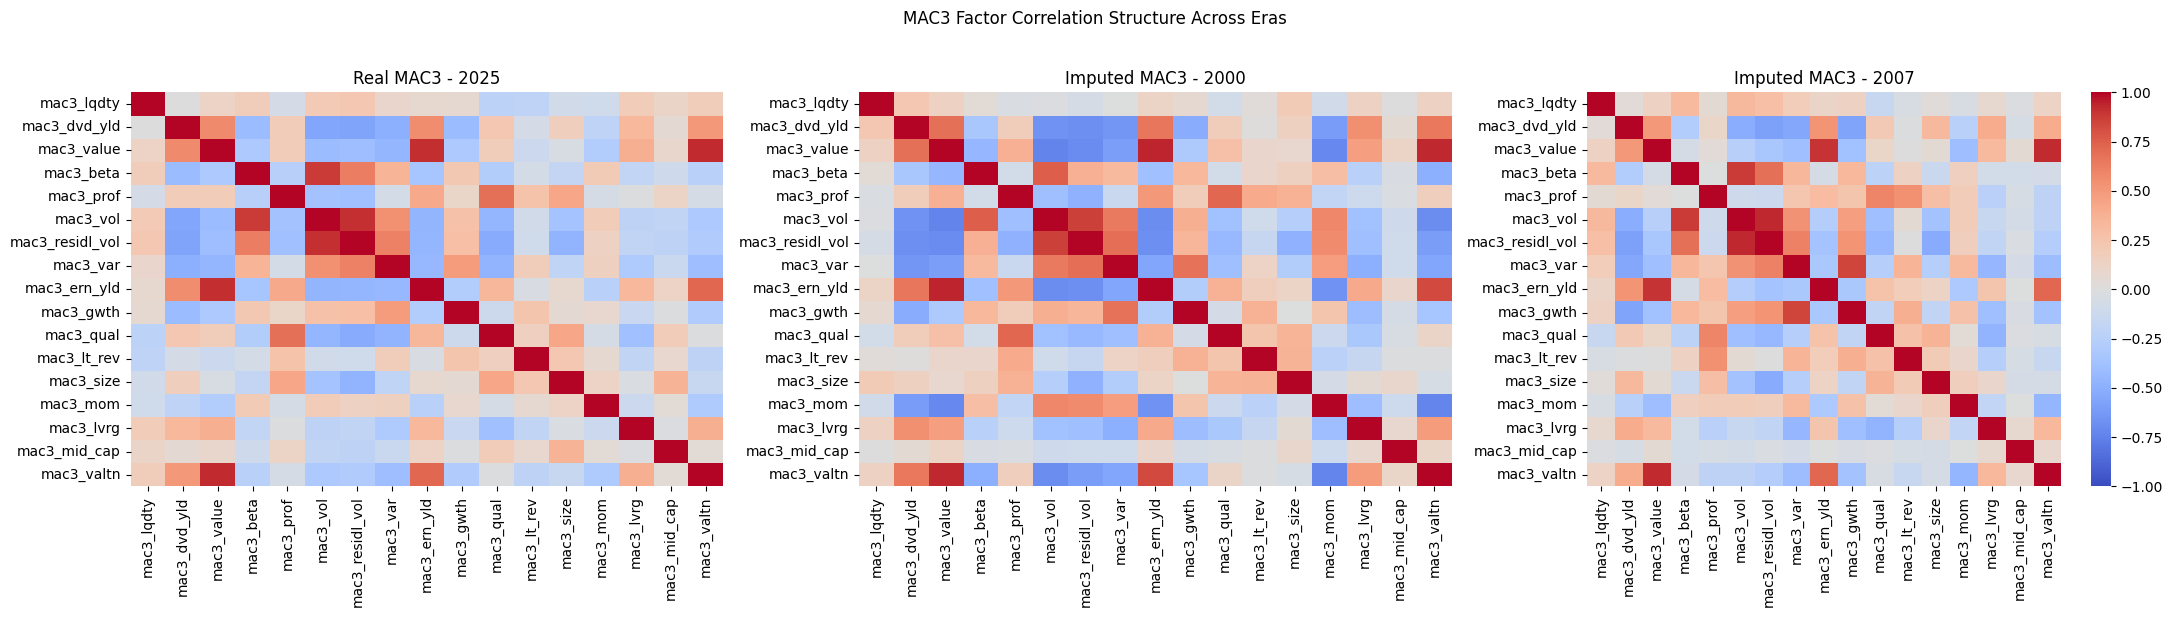

In [ ]:
# Part 4.8 - Correlation heatmaps
import seaborn as sns
fig, axes = plt.subplots(
    1,
    3,
    figsize=(22, 6)
)

sns.heatmap(
    corr_real_2025,
    ax=axes[0],
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    cbar=False
)
axes[0].set_title("Real MAC3 - 2025")

sns.heatmap(
    corr_imputed_2000,
    ax=axes[1],
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    cbar=False
)
axes[1].set_title("Imputed MAC3 - 2000")

sns.heatmap(
    corr_imputed_2007,
    ax=axes[2],
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)
axes[2].set_title("Imputed MAC3 - 2007")

plt.suptitle(
    "MAC3 Factor Correlation Structure Across Eras",
    y=1.02
)

plt.tight_layout()
plt.show()

### 4.8 Interpretation

The engineered-feature drift check shows that most features retain broadly comparable cross-sectional meaning between the historical peaks and the 2022–2024 training years, although several important coverage limitations remain.

The relative market-position features are particularly stable. `cum_share`, `size_rel`, `midcap_band`, and `midcap_bump` show very small median shifts across eras. This supports their use for historical transfer because they describe a stock relative to the market on the same date rather than relying only on absolute modern dollar levels.

Some absolute-scale features shift more noticeably in 2000. The medians of `log_employees`, `log_mcap`, and `log_traded_val` are lower than in the modern training period by roughly one-half to two-thirds of a modern interquartile range. These shifts are plausible given the smaller scale of firms and the overall market in 2000, but they reinforce the need for caution when applying modern models historically.

The largest concerns are driven by missingness. `buyback_yield` has no usable coverage in 2000 and almost none in 2007. `employee_growth` is available for only 46.3% of the 2000 universe, while `px3` is available for only 29.9%. These features therefore do not carry the same level of historical reliability as the better-covered relative features.

Despite these input differences, the reconstructed MAC3 factors retain a broadly similar correlation structure to the real 2025 MAC3 system. The pairwise factor-correlation structure has a Spearman correlation of 0.906 for the 2000 reconstruction and 0.912 for 2007 when compared with 2025. The corresponding mean absolute correlation differences are 0.135 and 0.105. The closer 2007 match is consistent with its generally stronger historical feature coverage.

Overall, the reconstructed factor system is structurally plausible, but confidence should vary by factor according to modern validation strength, historical missingness sensitivity, and dependence on historically weak engineered inputs. These results are used directly in the factor-by-factor confidence assessment in Part 4.9.

## 4.9 Confidence level per factor

The historical MAC3 reconstructions do not have a true 2000 or 2007 answer key, so confidence must be based on the years where the models can be checked and on their robustness to historical missingness.

To make the risk-committee assessment consistent across all 17 factors, we use the following decision rule:

- **Use:** Spearman correlation is at least 0.80 in 2025, 2026, the 2000-style stress test, and the 2007-style stress test.
- **Use with caution:** the worst of those four scores is between 0.70 and 0.80.
- **Do not use:** at least one of the four scores is below 0.70.

The historical stress results use the train-with-gaps strategy selected in Part 4.6. Crash returns are not used to assign confidence. These cutoffs are a team-defined decision rule for this project; they are not thresholds supplied by Bloomberg or the course.

In [ ]:
# Part 4.9 - Confidence level for each reconstructed MAC3 factor

confidence_4_9 = pd.DataFrame(index=MAC3)

# Modern out-of-sample validation from Part 3
confidence_4_9["2025 validation"] = (
    final_tab.loc[MAC3, "2025"].astype(float)
)

confidence_4_9["2026 validation"] = (
    final_tab.loc[MAC3, "2026"].astype(float)
)

# Historical-missingness validation using the gap strategy
# selected in Part 4.6
confidence_4_9["2000 stress"] = (
    gap_train_4_5.loc[
        MAC3,
        "2000-gap Spearman"
    ].astype(float)
)

confidence_4_9["2007 stress"] = (
    gap_train_4_5.loc[
        MAC3,
        "2007-gap Spearman"
    ].astype(float)
)

SCORE_COLS_4_9 = [
    "2025 validation",
    "2026 validation",
    "2000 stress",
    "2007 stress",
]

confidence_4_9["worst-case Spearman"] = (
    confidence_4_9[SCORE_COLS_4_9]
    .min(axis=1)
)

confidence_4_9["worst-case test"] = (
    confidence_4_9[SCORE_COLS_4_9]
    .idxmin(axis=1)
)


def confidence_label(worst_score):
    if worst_score >= 0.80:
        return "Use"
    elif worst_score >= 0.70:
        return "Use with caution"
    else:
        return "Do not use"


confidence_4_9["confidence"] = (
    confidence_4_9["worst-case Spearman"]
    .apply(confidence_label)
)

print("Part 4.9 - Risk committee confidence by factor")

display(
    confidence_4_9.round(3)
)

In [ ]:
# Part 4.9 - One-line reason for every confidence decision

def confidence_reason(row):
    score = row["worst-case Spearman"]
    test = row["worst-case test"]
    label = row["confidence"]

    if label == "Use":
        return (
            f"All four validation/stress Spearman scores are >= 0.80; "
            f"worst case is {test} at {score:.3f}."
        )

    if label == "Use with caution":
        return (
            f"Worst-case Spearman is {score:.3f} in {test}; "
            f"usable, but below the 0.80 high-confidence threshold."
        )

    return (
        f"Worst-case Spearman is only {score:.3f} in {test}; "
        f"historical reconstruction is not reliable enough for risk use."
    )


confidence_4_9["reason"] = (
    confidence_4_9.apply(
        confidence_reason,
        axis=1
    )
)

confidence_output_4_9 = confidence_4_9[
    [
        "confidence",
        "2025 validation",
        "2026 validation",
        "2000 stress",
        "2007 stress",
        "reason",
    ]
]

display(confidence_output_4_9.round(3))

In [ ]:
# Part 4.9 - Confidence summary

confidence_counts_4_9 = (
    confidence_4_9["confidence"]
    .value_counts()
    .reindex(
        [
            "Use",
            "Use with caution",
            "Do not use",
        ],
        fill_value=0
    )
)

print("Risk-committee confidence summary")
display(
    confidence_counts_4_9
    .rename("number of factors")
    .to_frame()
)

print(
    "\nFactors marked Do not use:",
    confidence_4_9.index[
        confidence_4_9["confidence"]
        == "Do not use"
    ].tolist()
)

print(
    "Factors marked Use with caution:",
    confidence_4_9.index[
        confidence_4_9["confidence"]
        == "Use with caution"
    ].tolist()
)

### 4.9 Interpretation

The confidence assessment classifies 13 of the 17 reconstructed MAC3 factors as **Use**, two as **Use with caution**, and two as **Do not use**.

Liquidity and Long-Term Reversal are the two factors that should not be relied on by the risk committee. Liquidity has a worst-case Spearman correlation of 0.609 under the 2000-style stress test, while Long-Term Reversal falls to 0.546. Both were also among the weakest factors in the modern walk-forward validation, so their historical reconstruction weakness is not limited to missingness alone.

Growth and Momentum are classified as **Use with caution**. Growth reaches a worst-case Spearman of 0.744 under 2000-style missingness, while Momentum's weakest result is 0.764 in the 2026 walk-forward test. Their reconstructions still preserve meaningful ranking information but are less stable than the high-confidence factors.

The remaining 13 factors maintain Spearman correlations of at least 0.80 across both modern validation years and both historical-missingness stress scenarios. These include Value, Beta, Profitability, Volatility, Residual Volatility, Earnings Yield, Quality, Size, Leverage, Valuation, Dividend Yield, Earnings Variability, and Mid Cap.

These confidence labels reflect performance only in the years and stress scenarios where reconstruction quality can be tested. There is still no true MAC3 answer key for 2000 or 2007, so even factors labeled **Use** should be interpreted as validated reconstructions rather than known historical truth.

## 4.10 HANDOFF: Imputed factors to Member D

Part 4 is now complete. The historical MAC3 reconstructions handed to Part 5 are:

- `imputed_mac3_20000324.csv` — 1,586 securities, ticker + 17 reconstructed MAC3 factors
- `imputed_mac3_20071009.csv` — 1,570 securities, ticker + 17 reconstructed MAC3 factors

The final historical reconstruction uses the **train-with-gaps** strategy selected in Part 4.6 from out-of-sample 2025 stress-test performance. This decision was made before examining crash outcomes.

Member D should use these exact reconstructed factors for the crash-validation and cross-crash analyses rather than rebuilding or substituting another historical MAC3 dataset.

### Confidence caveats

- **Use:** 13 factors
- **Use with caution:** Growth and Momentum
- **Do not use:** Liquidity and Long-Term Reversal

These confidence labels are based on modern walk-forward validation and historical-missingness stress tests. There is no true MAC3 answer key for 2000 or 2007.

In [ ]:
# Part 4.10 - Final Member C handoff verification

HANDOFF_FILES = {
    "2000": "imputed_mac3_20000324.csv",
    "2007": "imputed_mac3_20071009.csv",
}

# Verify the exact in-memory outputs that Part 5 should use
assert imputed_mac3_2000.shape == (1586, 18)
assert imputed_mac3_2007.shape == (1570, 18)

assert list(imputed_mac3_2000.columns) == ["ticker"] + MAC3
assert list(imputed_mac3_2007.columns) == ["ticker"] + MAC3

assert imputed_mac3_2000[MAC3].isna().sum().sum() == 0
assert imputed_mac3_2007[MAC3].isna().sum().sum() == 0

assert FINAL_GAP_METHOD == "train with gaps"

print("PART 4 HANDOFF READY")
print("--------------------")
print("2000 file:", HANDOFF_FILES["2000"])
print("2000 universe:", len(imputed_mac3_2000))
print("2007 file:", HANDOFF_FILES["2007"])
print("2007 universe:", len(imputed_mac3_2007))
print("MAC3 factors per file:", len(MAC3))
print("Final gap strategy:", FINAL_GAP_METHOD)

print("\nConfidence summary:")
display(
    confidence_counts_4_9
    .rename("number of factors")
    .to_frame()
)

print(
    "\nUse with caution:",
    confidence_4_9.index[
        confidence_4_9["confidence"] == "Use with caution"
    ].tolist()
)

print(
    "Do not use:",
    confidence_4_9.index[
        confidence_4_9["confidence"] == "Do not use"
    ].tolist()
)

print("\nMember D should use these exact Part 4 outputs: YES")

# Part 5: Crash Validation with the Analysts' Hint  *(Member D: Pratham)*

**The measure.** A *basket* is the n stocks with the highest risk score, held equal-weighted over the crash; its return
is the plain average of their `total_return` (in percent): `df.nlargest(n, score)["total_return"].mean()`, with n = 30
and n = 50. The **benchmark** is the equal-weighted return of all stocks on that date. A basket shows skill only if it
fell **further** than the benchmark.

**Nothing here is tuned on the outcome.** The score is exactly the one the analysts' hint prescribes, fixed before any
basket was looked at: the sum of two percentile ranks with equal weight, `hint_score = vol_rank + excess_rank`. All
ranks are percentile ranks within one date (`rank(pct=True)`, 1.0 = highest), which is a fair within-date transform.
Part 1 only described `total_return` (EDA); here it is used for the first time to score anything, and it never entered an imputation model (Parts 3 and 4).

| Peak | Epicenter (`sector`) | Excess | `excess_rank` with imputed MAC3 | with PORT US |
|---|---|---|---|---|
| 2000-03-24 | Information Technology, Communication Services | expensive | `(-mac3_value).rank(pct=True)` | `(-us_val).rank(pct=True)` |
| 2007-10-09 | Financials | levered | `mac3_lvrg.rank(pct=True)` | `us_lev.rank(pct=True)` |

High MAC3 Value and high PORT US Value both mean *cheap*, which is why "expensive" is the rank of minus Value.

In [ ]:
# Part 5 input: Member C's imputed factors (the Part 4 deliverables), joined to the clean panel by ticker
IMPUTED_COLS = ["date_str", "ticker", "name", "sector", "sector_source", "mcap", "total_return"] + US + SEC_COLS
parts = []
for d in PEAKS:
    imp = pd.read_csv(f"imputed_mac3_{d}.csv")
    assert list(imp.columns) == ["ticker"] + MAC3, "file must hold ticker plus the 17 MAC3 factors"
    assert imp["ticker"].is_unique and imp[MAC3].notna().all().all()
    base = panel.loc[panel.date_str == d, IMPUTED_COLS]
    assert set(imp["ticker"]) == set(base["ticker"]), f"{d}: imputed tickers must match the panel"
    parts.append(base.merge(imp, on="ticker", how="left", validate="one_to_one"))
IMPUTED_PEAKS = pd.concat(parts, ignore_index=True)
assert "total_return" not in MAC3
print("rows per peak:", IMPUTED_PEAKS.groupby("date_str").size().to_dict())

In [ ]:
# Part 5 - the measure and the hint score, exactly as the brief defines them
N_BASKET = [30, 50]
CRASH_LABEL = {"20000324": "2000-2002", "20071009": "2007-2009"}
EPICENTER = {"20000324": ["Information Technology", "Communication Services"], "20071009": ["Financials"]}
# (volatility, value, leverage) in each factor model
SCORE_COLS = {"imputed MAC3": ("mac3_vol", "mac3_value", "mac3_lvrg"), "PORT US": ("us_vol", "us_val", "us_lev")}

def basket_return(df, score_column, n):
    # Equal-weighted total_return of the n highest-scored stocks (a stock with no score is never picked)
    return df.nlargest(n, score_column)["total_return"].mean()

def crash_rows(d, src=None):
    # Step 1: that peak's stocks with the imputed MAC3 columns, dropping only rows with no total_return
    src = IMPUTED_PEAKS if src is None else src
    return src[src.date_str == d].dropna(subset=["total_return"]).copy()

def hint_frames(d, model="imputed MAC3", src=None):
    # Steps 2-5 (step 6 when model="PORT US"): all-stock vol rank, then epicenter, re-ranked vol + excess
    vol, val, lev = SCORE_COLS[model]
    df = crash_rows(d, src)
    df["vol_rank"] = df[vol].rank(pct=True)                               # step 2: over all stocks
    epi = df[df["sector"].isin(EPICENTER[d])].copy()                      # step 3: keep the epicenter
    epi["vol_rank"] = epi[vol].rank(pct=True)                             # step 4: re-rank inside it
    epi["excess_rank"] = ((-epi[val]).rank(pct=True) if d == "20000324"    #   2000: expensive = low Value
                          else epi[lev].rank(pct=True))                    #   2007: levered
    epi["hint_score"] = epi["vol_rank"] + epi["excess_rank"]              # step 5
    return df, epi

# Who is in each step (step 1 drops only the stocks with no return at all)
chk = []
for d in PEAKS:
    allrows = IMPUTED_PEAKS[IMPUTED_PEAKS.date_str == d]
    df, epi = hint_frames(d)
    _, epi_us = hint_frames(d, "PORT US")
    chk.append({"peak": d, "stocks at peak": len(allrows), "no total_return (dropped)": int(allrows.total_return.isna().sum()),
                "stocks scored": len(df), "imputed MAC3 vol filled": int(df.mac3_vol.notna().sum()),
                "PORT US vol filled": int(df.us_vol.notna().sum()), "epicenter stocks": len(epi),
                "epicenter sector from fill file": int((epi.sector_source == "sector-fill file").sum()),
                "epicenter with a PORT US hint score": int(epi_us.hint_score.notna().sum())})
    print(f"{d}: {100 * df.us_vol.isna().mean():.1f}% of the scored stocks have no PORT US volatility exposure")
pd.DataFrame(chk).set_index("peak").T

Imputed MAC3 gives **every** stock a score, including the ones whose PORT US exposures are blank (13% of the 2000
universe). The PORT US baskets can only pick from the stocks that have the PORT US columns; we leave those blanks
as they are rather than fill them, because that *is* the old model as the desk had it.

## 5.1 The crash validation table

In [ ]:
# Part 5 - crash validation table: volatility only and the hint, imputed MAC3 against PORT US
cv_rows = []
for d in PEAKS:
    all_stocks = crash_rows(d)["total_return"].mean()
    # the brief's three rows, in its order, then PORT US volatility only as an extra comparison
    for label, score, model in [("Volatility only, MAC3", "Volatility only", "imputed MAC3"),
                                ("Hint score, imputed MAC3", "Hint score", "imputed MAC3"),
                                ("Hint score, PORT US", "Hint score", "PORT US"),
                                ("Volatility only, PORT US (extra)", "Volatility only", "PORT US")]:
        df, epi = hint_frames(d, model)
        frame, col = (df, "vol_rank") if score == "Volatility only" else (epi, "hint_score")
        row = {"Crash": CRASH_LABEL[d], "Score": label}
        for n in N_BASKET:
            row[f"Top-{n} EW total return"] = basket_return(frame, col, n)
        row["All stocks EW total return"] = all_stocks
        row["Epicenter EW total return"] = epi["total_return"].mean()
        row["stocks ranked"] = int(frame[col].notna().sum())
        cv_rows.append(row)
crash_validation = pd.DataFrame(cv_rows)
for n in N_BASKET:
    crash_validation[f"Top-{n} minus all stocks"] = (crash_validation[f"Top-{n} EW total return"]
                                                      - crash_validation["All stocks EW total return"])
    crash_validation[f"Top-{n} minus epicenter"] = (crash_validation[f"Top-{n} EW total return"]
                                                     - crash_validation["Epicenter EW total return"])
crash_validation.to_csv("crash_validation.csv", index=False)
print("saved crash_validation.csv (returns in percent)")
crash_validation.round(1)

### Is the gap bigger than luck?
A basket of 30 stocks is a small sample, so we ask how often a basket of the same size **drawn at random** from all the
stocks on that date falls as far (10,000 random baskets, fixed seed). This uses no information beyond the table above;
it only tells us whether a gap is larger than the noise of picking 30 names.

In [ ]:
# Part 5 - share of random baskets (same size, all stocks of that date) that did at least as badly
rng = np.random.default_rng(5)
def random_share(d, basket_ret, n, draws=10_000):
    r = crash_rows(d)["total_return"].to_numpy()
    sims = np.array([r[rng.choice(len(r), n, replace=False)].mean() for _ in range(draws)])
    return (sims <= basket_ret).mean()

luck = crash_validation[["Crash", "Score"]].copy()
for n in N_BASKET:
    luck[f"Top-{n}: share of random baskets as bad"] = [
        random_share({v: k for k, v in CRASH_LABEL.items()}[c], r, n)
        for c, r in zip(crash_validation["Crash"], crash_validation[f"Top-{n} EW total return"])]
luck.round(4)

**What the table says.**
* **Every basket fell much further than the market.** With imputed MAC3, the hint baskets lost **92.8% / 93.8%**
  (top 30 / top 50) over 2000 to 2002, against **46.1%** for all stocks, and **80.1% / 77.6%** over 2007 to 2009,
  against **57.6%**. Volatility alone lost 90.8% / 89.5% and 73.2% / 74.0%.
* **It is not luck.** At most 0.07% of 10,000 random baskets of the same size did as badly as any score in the table
  (0.00% for every imputed MAC3 basket in 2000, and at most 0.01% in 2007).
* **The epicenter alone already explains a lot.** Holding the whole epicenter lost 78.5% (tech, 2000) and 65.8%
  (Financials, 2007). The hint baskets fell a further 14.3 / 15.3 points (2000) and 14.3 / 11.8 points (2007) beyond
  that, so the ranking inside the epicenter adds something on top of the sector call.

## 5.2 Name names: the top 10 by hint score at each peak

In [ ]:
# Part 5 step 7 - top 10 stocks by hint score (imputed MAC3), with their actual total return
for d in PEAKS:
    _, epi = hint_frames(d)
    top = epi.nlargest(10, "hint_score")[["ticker", "name", "sector", "sector_source", "vol_rank", "excess_rank",
                                         "hint_score", "total_return"]]
    print(f"\n{CRASH_LABEL[d]}: top 10 by hint score  (top-10 average {top.total_return.mean():.1f}%, "
          f"all stocks {crash_rows(d).total_return.mean():.1f}%)")
    display(top.round(3).reset_index(drop=True))

**The names.** The 2000 list is the dot-com bust: Rhythms NetConnections, NorthPoint, Globix, Mpower and Interwave
lost more than 99%, and the top 10 lost **93.1%** on average. The 2007 list is the financial crisis: Lehman Brothers
(−99.95%), IndyMac (−99.8%), BankUnited (−98.4%), MBIA (−95.4%), CIT Group (−94.1%), Countrywide and Bear Stearns,
with the top 10 losing **85.6%** on average. Bear Stearns shows only −42.8% because it stopped trading before the
bottom (JPMorgan bought it in 2008), so its `total_return` ends at its last filled window (Part 1.5). People Inc Group
(−49.9%) is the only 2000 name that did not fall by more than 90%.

Note that **9 of the 10 names on each list** get their sector from the sector-fill file, not Bloomberg: the companies
that crashed hardest are the ones that later disappeared, which is exactly why Bloomberg has no GICS sector for them.
Without the fill file (built from company names only, never from returns) the epicenter step would miss them.

## 5.3 What each half of the hint contributes
A diagnostic, not a new score: inside the epicenter we rank by each half of the hint alone, and compare with simply
holding the whole epicenter. The score itself stays the equal-weighted sum fixed above.

In [ ]:
# Part 5 - decomposition of the hint inside the epicenter (imputed MAC3)
dec = []
for d in PEAKS:
    df, epi = hint_frames(d)
    for label, col in [("epicenter, volatility rank only", "vol_rank"), ("epicenter, excess rank only", "excess_rank"),
                       ("epicenter, hint score (both)", "hint_score")]:
        dec.append({"Crash": CRASH_LABEL[d], "Score": label,
                    **{f"Top-{n}": basket_return(epi, col, n) for n in N_BASKET},
                    "Whole epicenter EW": epi.total_return.mean(), "All stocks EW": df.total_return.mean()})
    dec.append({"Crash": CRASH_LABEL[d], "Score": "all stocks, volatility rank only",
                **{f"Top-{n}": basket_return(df, "vol_rank", n) for n in N_BASKET},
                "Whole epicenter EW": epi.total_return.mean(), "All stocks EW": df.total_return.mean()})
    top_v = df.nlargest(30, "vol_rank")
    print(f"{CRASH_LABEL[d]}: {top_v.sector.isin(EPICENTER[d]).sum()} of the 30 most volatile stocks (all-stock rank) "
          f"are already in the epicenter; their sectors: {top_v.sector.value_counts().to_dict()}")
pd.DataFrame(dec).round(1)

**What each half contributes.**
* **2000:** the 30 most volatile stocks of the whole market already include **23 in tech** (19 IT and 4 Communication
  Services), so the epicenter filter changes little. Inside the epicenter, volatility alone (−92.8% / −91.1%) does
  better than expensiveness alone (−89.2% / −88.0%), and the sum of the two matches the better half on the top 30
  (−92.8%) and beats both on the top 50 (−93.8%).
* **2007:** the 30 most volatile stocks are mostly Materials, IT, Consumer Discretionary and Industrials, with **only
  2 Financials**. Volatility alone misses the epicenter. Inside Financials, **leverage does most of the work** (excess
  rank alone −79.4% / −79.3% against volatility alone −73.0% / −69.7%), which is the analysts' point: in 2007 it was
  the levered financials that fell hardest. The sum (−80.1% / −77.6%) is close to leverage alone.

## 5.4 The three questions

In [ ]:
# Part 5 - answer the three questions straight from the table
cvi = crash_validation.set_index(["Crash", "Score"])
for d in PEAKS:
    c = CRASH_LABEL[d]
    bench = cvi.loc[(c, "Hint score, imputed MAC3"), "All stocks EW total return"]
    h, v, u = (cvi.loc[(c, s)] for s in ["Hint score, imputed MAC3", "Volatility only, MAC3", "Hint score, PORT US"])
    print(f"--- {c} (all stocks {bench:.1f}%)")
    for n in N_BASKET:
        k = f"Top-{n} EW total return"
        print(f"  top-{n}: hint MAC3 {h[k]:.1f}% | vol-only MAC3 {v[k]:.1f}% | hint PORT US {u[k]:.1f}%  ->  "
              f"beats all stocks: {h[k] < bench}, beats PORT US: {h[k] < u[k]}, hint beats vol only: {h[k] < v[k]}")

**The three questions, one sentence each.**
1. **Did the imputed MAC3 baskets beat the all-stocks portfolio?** Yes, every one in both crashes: the hint baskets fell
   46.7 / 47.7 points further than the market in 2000 to 2002 and 22.5 / 20.1 points further in 2007 to 2009 (top 30 /
   top 50), far beyond what a random basket does.
2. **Did they beat PORT US?** In 2000, yes: hint −92.8% / −93.8% against −84.6% / −86.9% for PORT US, and volatility
   alone by a wide margin (−90.8% / −89.5% against −77.5% / −75.1%), partly because PORT US is blank for 13.1% of the
   2000 stocks and so cannot rank them (only 624 of the 762 epicenter stocks have a PORT US hint score). In 2007, no:
   the PORT US hint fell further (−83.4% / −80.3% against −80.1% / −77.6%), and volatility alone is a tie (−73.2% vs
   −73.9% for the top 30, −74.0% vs −70.9% for the top 50). PORT US Leverage is nearly the same factor as MAC3 Leverage
   (Part 1.7: Spearman 0.94), so in 2007 the imputed MAC3 adds nothing over the real old model.
3. **Did the hint beat volatility alone in both crashes?** Yes: in 2000 −92.8% / −93.8% against −90.8% / −89.5%, and in
   2007 −80.1% / −77.6% against −73.2% / −74.0%. The gain is larger in 2007, because the most volatile stocks of 2000
   were already the tech stocks, while in 2007 volatility alone looks outside Financials.

# Part 6: Can One Crash Predict the Next?  *(Member D: Pratham)*

The desk's idea: learn what crashing stocks looked like in one crash and use that model for the next. We test it in
both directions, **training on one crash and scoring only on the other** (a score on the training crash is not a test).

**Set-up, fixed before any test result is seen:**
* **Inputs:** the 17 imputed MAC3 factors, each turned into a percentile rank within its date (minus 0.5, so it is
  centred), plus the 11 sector dummies. Ranking within the date puts the small market of 2000 and the larger one of
  2007 on one scale.
* **Target:** `total_return` ranked within its date the same way. A stock that fell further than most has a low target.
* **Risk score:** `risk_score = -predicted_return`, scored with the Part 5 basket return (top 30 and top 50 against
  the all-stocks portfolio of the **test** crash).
* **Models:** linear regression; Ridge with alpha 1, 10, 100, 1000; Lasso with four alphas; CatBoost from deep and
  lightly regularised to shallow and heavily regularised. Hyperparameters are a fixed grid, not tuned on the test
  crash (there is no third crash to tune on).
* We also report the **rank IC**, the Spearman correlation between the risk score and the stock's actual loss over the
  whole test universe, which uses every stock and not just the top 30.

In [ ]:
# Part 6 - cross-crash design: within-date ranks for features and target
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from catboost import CatBoostRegressor

CROSS_FEATS = MAC3 + SEC_COLS
def cross_xy(d, src=None):
    df = crash_rows(d, src)
    X = pd.concat([df[MAC3].rank(pct=True) - 0.5, df[SEC_COLS].astype(float)], axis=1)[CROSS_FEATS]
    y = df["total_return"].rank(pct=True) - 0.5
    return df, X, y

RIDGE_X = [1, 10, 100, 1000]
LASSO_X = [0.0005, 0.002, 0.005, 0.01]
CAT_X = [(6, 3), (4, 10), (2, 30), (1, 100)]          # deep and light -> shallow and heavy
def cross_models():
    yield "Linear regression", LinearRegression()
    for a in RIDGE_X:
        yield f"Ridge, alpha = {a}", Ridge(alpha=a)
    for a in LASSO_X:
        yield f"Lasso, alpha = {a}", Lasso(alpha=a, max_iter=50_000)
    for dp, l2 in CAT_X:
        yield f"CatBoost, depth = {dp}, l2_leaf_reg = {l2}", CatBoostRegressor(
            iterations=500, learning_rate=0.03, depth=dp, l2_leaf_reg=l2, random_seed=42, verbose=0, thread_count=-1)

for d in PEAKS:
    df, X, y = cross_xy(d)
    print(f"{CRASH_LABEL[d]}: {X.shape[0]} stocks x {X.shape[1]} features, no blanks: {not X.isna().any().any()}, "
          f"target range [{y.min():.3f}, {y.max():.3f}]")

## 6.1 Train on one crash, test on the other

In [ ]:
# Part 6 - train on one crash, test on the other, for every model
DIRECTIONS = [("20000324", "20071009"), ("20071009", "20000324")]
cc_rows, FITTED, insample = [], {}, []
t0 = time.time()
for d_tr, d_te in DIRECTIONS:
    _, Xtr, ytr = cross_xy(d_tr)
    te, Xte, yte = cross_xy(d_te)
    for name, m in cross_models():
        m.fit(Xtr, ytr)
        FITTED[(d_tr, name)] = m
        te = te.assign(risk_score=-m.predict(Xte))
        row = {"Train on": CRASH_LABEL[d_tr], "Test on": CRASH_LABEL[d_te], "Model and regularization": name,
               **{f"Top-{n} EW total return": basket_return(te, "risk_score", n) for n in N_BASKET},
               "All stocks EW total return": te["total_return"].mean(),
               "rank IC on test crash": spearmanr(te["risk_score"], -te["total_return"])[0]}
        if name.startswith("Lasso"):
            row["features kept"] = int((np.abs(m.coef_) > 1e-10).sum())
        cc_rows.append(row)
        insample.append({"Train on": CRASH_LABEL[d_tr], "Model": name,
                         "in-sample rank IC (training crash, NOT a test)": spearmanr(-m.predict(Xtr), -ytr)[0],
                         "out-of-sample rank IC (other crash)": row["rank IC on test crash"]})
    # the plain rule from Part 5, which needs no training at all
    v = cvi.loc[(CRASH_LABEL[d_te], "Volatility only, MAC3")]
    df_v, _ = hint_frames(d_te)
    cc_rows.append({"Train on": "none", "Test on": CRASH_LABEL[d_te], "Model and regularization": "Volatility only (Part 5)",
                    **{f"Top-{n} EW total return": v[f"Top-{n} EW total return"] for n in N_BASKET},
                    "All stocks EW total return": v["All stocks EW total return"],
                    "rank IC on test crash": spearmanr(df_v["vol_rank"], -df_v["total_return"])[0]})
print(f"cross-crash models fitted in {time.time()-t0:.0f}s")
cross_crash = pd.DataFrame(cc_rows)
cross_crash.to_csv("cross_crash.csv", index=False)
print("saved cross_crash.csv (returns in percent)")
cross_crash.round(3)

**Step 1, the plain linear regression:**
* **Train on 2000, test on 2007:** top 30 / top 50 lost **66.8% / 71.8%** against 57.6% for all stocks. It beats the
  market, but volatility alone lost **73.2% / 74.0%**.
* **Train on 2007, test on 2000:** **83.4% / 83.8%** against 46.1% for all stocks; volatility alone lost
  **90.8% / 89.5%**.

So the model learned something that carries over, but less than volatility alone, which needs no training at all.
The table in 6.2 makes this exact for every model.

## 6.2 Did the trained model beat the plain rule?

In [ ]:
# Part 6 step 2 - each trained model against volatility only, on the same test crash
cmp = cross_crash[cross_crash["Train on"] != "none"].copy()
vol_only = cross_crash[cross_crash["Train on"] == "none"].set_index("Test on")
for n in N_BASKET:
    k = f"Top-{n} EW total return"
    cmp[f"top-{n} vs vol only (pp)"] = cmp[k] - cmp["Test on"].map(vol_only[k])     # negative = fell further = better
cmp["IC vs vol only"] = cmp["rank IC on test crash"] - cmp["Test on"].map(vol_only["rank IC on test crash"])
cmp["beats vol only, top-30 and top-50"] = (cmp["top-30 vs vol only (pp)"] < 0) & (cmp["top-50 vs vol only (pp)"] < 0)
print("models that beat volatility only on both basket sizes:",
      cmp.groupby("Train on")["beats vol only, top-30 and top-50"].sum().to_dict(), "of", len(RIDGE_X + LASSO_X + CAT_X) + 1)
cmp[["Train on", "Test on", "Model and regularization", "top-30 vs vol only (pp)", "top-50 vs vol only (pp)",
     "IC vs vol only", "beats vol only, top-30 and top-50"]].round(3)

**Did the trained models beat volatility alone? No, not reliably.**
* **Over the whole test universe (rank IC), no model beats volatility in either direction.** On 2007, volatility alone
  has a rank IC of **0.328**; the best trained model (Lasso, alpha 0.0005) reaches 0.273. On 2000, volatility alone has
  **0.649**; the best trained model (Lasso, alpha 0.01) reaches 0.602.
* **On the 30- and 50-stock baskets**, none of the 13 models trained on 2000 falls further than volatility alone at
  both sizes. Of the 13 trained on 2007, only the two most heavily penalised Lassos do (alpha 0.005: −91.5% / −90.7%;
  alpha 0.01: −93.6% / −92.2%), by 0.7 to 2.8 points, within the noise of a 30-stock average. Those two are the models
  closest to volatility itself: the alpha 0.01 Lasso keeps only Volatility, Quality and two sector dummies (6.4).
* As the brief says, a trained model that does no better than volatility alone is a result, not a bug.

## 6.3 Look inside the model
The target is the return rank, so a **negative** coefficient means "stocks high on this fell further" (a sign of
**danger**), and a positive one means a sign of **safety**. We print the plain linear model trained on 2000, and next
to it the same model trained on 2007, to see which lessons the two crashes share.

In [ ]:
# Part 6 step 3 - coefficients of the linear models (plain linear regression)
coefs = pd.DataFrame({f"trained on {CRASH_LABEL[d]}": pd.Series(FITTED[(d, "Linear regression")].coef_, index=CROSS_FEATS)
                      for d in PEAKS})
c00 = coefs["trained on 2000-2002"].sort_values()
print("2000 model, largest signs of DANGER (most negative):")
display(c00.head(8).round(3).to_frame().join(coefs["trained on 2007-2009"].round(3)))
print("2000 model, largest signs of SAFETY (most positive):")
display(c00.tail(8)[::-1].round(3).to_frame().join(coefs["trained on 2007-2009"].round(3)))
agree = np.sign(coefs.iloc[:, 0]) == np.sign(coefs.iloc[:, 1])
print(f"features whose sign agrees between the two crashes: {agree.sum()} of {len(agree)}; "
      f"correlation of the two coefficient vectors: {coefs.corr().iloc[0, 1]:.2f}")
print("hint factors:", coefs.loc[["mac3_vol", "mac3_value", "mac3_lvrg", "sec_Information_Technology",
                                  "sec_Communication_Services", "sec_Financials"]].round(3).to_dict("index"))
# MAC3 Volatility and Residual Volatility are close cousins, so a linear model splits one effect between them
for d in PEAKS:
    _, X_, _ = cross_xy(d)
    c_ = coefs[f"trained on {CRASH_LABEL[d]}"]
    print(f"{CRASH_LABEL[d]}: rank corr(mac3_vol, mac3_residl_vol) = {X_.mac3_vol.corr(X_.mac3_residl_vol):.2f}; "
          f"combined volatility coefficient = {c_['mac3_vol'] + c_['mac3_residl_vol']:.3f}")

**What the 2000 model learned.**
* **Signs of danger:** Residual Volatility (−0.403, the largest), Earnings Yield (−0.232), Valuation (−0.160), Momentum
  (−0.156), Real Estate (−0.132), Leverage (−0.125), Earnings Variability (−0.117), Communication Services (−0.113;
  IT −0.097).
* **Signs of safety:** Value (+0.506, the largest coefficient of all: *cheap* was safe and *expensive* was dangerous),
  Profitability (+0.180), Energy (+0.129), Health Care (+0.110), Consumer Staples (+0.104), and Financials (+0.038).
* Correlated factors share one effect, so they have to be read together. MAC3 Volatility gets almost nothing (−0.026)
  because Residual Volatility, with a rank correlation of 0.86, takes the effect: their combined coefficient is
  **−0.430**, clearly danger (−0.478 in 2007). In the same way Earnings Yield and Valuation are cousins of Value, and the
  valuation group is led by Value's +0.506.

**Against the 2007 hint, which half should carry over?**
* **Should carry over: volatility.** The analysts say the most volatile stocks fell hardest in *both* crashes, and the
  2007-trained model agrees (Volatility −0.250, Residual Volatility −0.228).
* **Should not: "expensive tech is dangerous, financials are safe".** That was 2000's epicenter. The 2000 model's
  strongest safety sign is cheapness (Value +0.506, against +0.198 in the 2007 model), and it treats Financials as
  *safe* (+0.038), while in 2007 Financials were the epicenter (−0.100 in the 2007 model). Its leverage sign (−0.125)
  happens to point the right way for 2007, but the hint is about leverage *inside Financials*, a sector-factor
  interaction that one linear coefficient across all sectors cannot express.
* Overall only 20 of 28 coefficient signs agree between the two crashes, and the two coefficient vectors have a
  correlation of 0.57.

## 6.4 Does regularization help?

In [ ]:
# Part 6 step 4 - regularization path, both directions side by side
path = cross_crash[cross_crash["Train on"] != "none"].pivot_table(
    index="Model and regularization", columns="Train on",
    values=["Top-30 EW total return", "Top-50 EW total return", "rank IC on test crash"], sort=False)
display(path.round(3))
lk = cross_crash[cross_crash["Model and regularization"].str.startswith("Lasso")]
print("Lasso features kept (of", len(CROSS_FEATS), "):",
      lk.pivot_table(index="Model and regularization", columns="Train on", values="features kept", sort=False).to_dict())
for d in PEAKS:
    m_ = FITTED[(d, f"Lasso, alpha = {LASSO_X[-1]}")]
    print(f"Lasso alpha {LASSO_X[-1]} trained on {CRASH_LABEL[d]} keeps:",
          pd.Series(m_.coef_, index=CROSS_FEATS)[lambda c: c.abs() > 1e-10].round(3).to_dict())
print("\nIn-sample against out-of-sample rank IC (the in-sample column is a fit diagnostic, not a test):")
pd.DataFrame(insample).pivot_table(index="Model", columns="Train on", sort=False,
    values=["in-sample rank IC (training crash, NOT a test)", "out-of-sample rank IC (other crash)"]).round(3)

In [ ]:
# Part 6 step 4 - why the most flexible model transferred worst: what the deep tree trained on 2007 picks in 2000
deep = "CatBoost, depth = 6, l2_leaf_reg = 3"
te, Xte, _ = cross_xy("20000324")
te["risk_score"] = -FITTED[("20071009", deep)].predict(Xte)
top = te.nlargest(30, "risk_score")
print(f"{deep}, trained on 2007-2009, top 30 in 2000: average {top.total_return.mean():.1f}% "
      f"(all stocks {te.total_return.mean():.1f}%)")
print("sectors of those 30:", top.sector.value_counts().to_dict())
print("2000-2002 EW total return by sector:", te.groupby("sector").total_return.mean().round(1).to_dict())
print("\nits largest feature importances:")
pd.Series(FITTED[("20071009", deep)].get_feature_importance(), index=CROSS_FEATS).sort_values(ascending=False).head(8).round(1)

**Did more regularization help? In one direction, not in the other.**
* **Train on 2007, test on 2000: yes.** The rank IC is highest at the heaviest penalties: Lasso from 0.491 (alpha 0.0005, 21
  features kept) to **0.602** (alpha 0.01, 4 kept), Ridge from 0.512 (alpha 1) to 0.549 (alpha 1000), and CatBoost from
  0.365 (depth 6) to 0.466 (depth 1).
* **Train on 2000, test on 2007: no.** Ridge falls from 0.264 (alpha 1) to 0.178 (alpha 1000), Lasso from 0.273 to
  0.242, and CatBoost stays flat at 0.245 to 0.257. Shrinking keeps only the strongest effects of the training crash,
  and in 2000 those are crash-specific: the heaviest Lasso (alpha 0.01) trained on 2000 keeps the two volatility
  factors, but also Value (cheap = safe) and the IT and Communication Services dummies. Trained on 2007, the same Lasso
  keeps Volatility, Quality, Financials and Health Care, and the volatility part is what pays off in 2000.
* **Lasso features kept:** trained on 2000, 21, 15, 9 and 7 of 28; trained on 2007, 21, 14, 10 and 4.

**The most flexible model transferred worst.** CatBoost with depth 6 has the best in-sample fit (rank IC 0.919 on
2000 and 0.832 on 2007, against 0.784 and 0.489 for the linear model) and the worst transfer. Trained on 2007 and
applied to 2000, its top 30 lost only **27.6%** and its top 50 **25.9%**, *less* than the 46.1% of all stocks: the score
points the wrong way. Depth 4 does the same (−34.0% / −32.5%), depth 2 is about level with the market (−38.7% / −45.6%),
and only depth 1 beats it (−63.6% / −62.8%). The reason is printed above: 17 of the deep tree's 30 riskiest 2000 names
are **Financials**, the 2007 epicenter, which in 2000 to 2002 lost only 7.9% on average. A deep tree memorises the
interactions of the crash it was trained on (this sector with that factor), and those are exactly the parts that
change from one crash to the next. The linear models on ranks mostly carry the volatility signal, which is the part
that transfers.

## 6.5 The lesson

> **Each crash had its own epicenter, and a model trained on the last crash learns the last crash's epicenter. Only one
> lesson carried over, that the most volatile stocks fall hardest: volatility alone, with no training, ranked the next
> crash better than every model we trained on the other crash, and the only models that matched it were the ones
> regularised until they were little more than volatility.**

**Limits of Parts 5 and 6, stated plainly.**
* There is no MAC3 answer key for 2000 or 2007. These baskets test whether the *imputed* factors point at the stocks
  that crashed, which is evidence the reconstruction is useful, not proof that each value is right.
* Two crashes are two data points. A 30-stock basket is noisy (one name moves the average by 2 to 3 points), so
  differences of a few points between scores should not be over-read; the rank IC over the full universe is the more
  stable comparison.
* `total_return` stops at delisting for takeovers and bankruptcies (Part 1.5), so a takeover such as Bear Stearns looks
  better than holding it to the bottom would have been.
* The hint itself came from analysts who had already seen both crashes. Part 5 shows that the imputed factors carry
  the hint's signal; Part 6 is the honest test of what could have been known *before* a crash.

# Reality checks and critical evaluation

Professor Low's **Critical Considerations** and the **Week 7 walkthrough** (which imputed five focus factors: Size, Value, Momentum, Liquidity and Mid Cap) give reference numbers. The cell below prints ours next to them, all computed from the tables above, so every number in the video can be traced to this notebook.

Two differences from Week 7 to keep in mind when comparing:
* **Twin for Liquidity.** Week 7 used turnover (0.39) because PORT US has no liquidity factor; following the brief, our twin is the closest *PORT US factor*, which is weaker for Liquidity. That lowers our Liquidity baseline, not our models.
* **17 factors, not 5.** Week 7's averages are over the five focus factors, so we report both our five-factor mean and our 17-factor mean.

In [ ]:
# Reality checks: our results against the brief's Critical Considerations and the Week 7 walkthrough
R_all = pd.DataFrame(RESULTS)
FOCUS5 = ["mac3_size", "mac3_value", "mac3_mom", "mac3_lqdty", "mac3_mid_cap"]       # the Week 7 focus factors
def mean_sp(model, year, factors=MAC3):
    r = R_all[(R_all.model == model) & (R_all.test_year == year) & R_all.factor.isin(factors)]
    return r.spearman.mean()
best_lin = max(["OLS", "Ridge", "Lasso"], key=lambda m: mean_sp(m, "2025"))
best_tree = max(["XGBoost", "CatBoost"], key=lambda m: mean_sp(m, "2025"))
cvx = crash_validation.set_index(["Crash", "Score"])
trained = cross_crash[cross_crash["Train on"] != "none"]
volonly = cross_crash[cross_crash["Train on"] == "none"].set_index("Test on")
checks = [
    ("Twin baseline, 2025, mean of the 5 Week 7 factors", "about 0.60", mean_sp("twin baseline", "2025", FOCUS5)),
    ("Twin baseline, 2025, mean of all 17", "about 0.60", mean_sp("twin baseline", "2025")),
    (f"Best plain linear model ({best_lin}), 2025, mean of 5", "0.77 to 0.84", mean_sp(best_lin, "2025", FOCUS5)),
    (f"Best plain linear model ({best_lin}), 2025, mean of 17", "0.77 to 0.84", mean_sp(best_lin, "2025")),
    (f"Best tree ({best_tree}), 2025, mean of 5", "about 0.87", mean_sp(best_tree, "2025", FOCUS5)),
    (f"Best tree ({best_tree}), 2025, mean of 17", "about 0.87", mean_sp(best_tree, "2025")),
    ("Final model, Size, 2025", "above 0.90", final_tab.loc["mac3_size", "2025"]),
    ("Final model, Value, 2025", "above 0.90", final_tab.loc["mac3_value", "2025"]),
    ("Final model, Momentum, 2025", "above 0.90", final_tab.loc["mac3_mom", "2025"]),
    ("Final model, Liquidity, 2025", "about 0.66 (hardest of the 5)", final_tab.loc["mac3_lqdty", "2025"]),
    ("Final model, Long-Term Reversal, 2025", "far below 0.99 (0.99 = a leak)", final_tab.loc["mac3_lt_rev", "2025"]),
    ("All stocks EW total return, 2000-2002 (%)", "about -46", cvx.loc[("2000-2002", "Hint score, imputed MAC3"), "All stocks EW total return"]),
    ("All stocks EW total return, 2007-2009 (%)", "about -58", cvx.loc[("2007-2009", "Hint score, imputed MAC3"), "All stocks EW total return"]),
    ("Hint top-30 minus all stocks, 2000-2002 (pp)", "negative (riskiest fell further)", cvx.loc[("2000-2002", "Hint score, imputed MAC3"), "Top-30 minus all stocks"]),
    ("Hint top-30 minus all stocks, 2007-2009 (pp)", "negative (riskiest fell further)", cvx.loc[("2007-2009", "Hint score, imputed MAC3"), "Top-30 minus all stocks"]),
    ("Part 6: best trained rank IC minus volatility only, test 2007-2009", "<= 0 is a result, not a bug",
     trained[trained["Test on"] == "2007-2009"]["rank IC on test crash"].max() - volonly.loc["2007-2009", "rank IC on test crash"]),
    ("Part 6: best trained rank IC minus volatility only, test 2000-2002", "<= 0 is a result, not a bug",
     trained[trained["Test on"] == "2000-2002"]["rank IC on test crash"].max() - volonly.loc["2000-2002", "rank IC on test crash"]),
]
reality = pd.DataFrame(checks, columns=["check", "reference (brief / Week 7)", "ours"]).set_index("check")
reality["ours"] = reality["ours"].astype(float).round(3)
reality

**What the reality checks say.**
* **Twin baseline.** 0.651 over all 17 factors in 2025. Over Week 7's five focus factors it is 0.554, below Week 7's 0.60 for one reason: Week 7's Liquidity twin was turnover (0.39), ours is the closest PORT US factor (0.17, Part 2), as the brief asks. The other four twins match Week 7.
* **Models.** The best plain linear model (Lasso) reaches 0.838 on the five factors, inside the 0.77 to 0.84 range, and XGBoost 0.869, matching "about 0.87". Over all 17 factors the means are 0.860 and 0.891.
* **Factor by factor.** Size 0.955, Value 0.961 and Momentum 0.913 are above 0.90; Liquidity 0.673 is close to Week 7's 0.66. Long-Term Reversal is 0.600 and Liquidity far below 0.99, so there is no sign of a leak.
* **Crashes.** The all-stocks benchmarks are −46.1% and −57.6% (brief: about −46% and −58%), and the hint's 30 riskiest stocks fell 46.7 and 22.5 points further than all stocks, so the score points the right way.
* **Part 6.** The best trained cross-crash model has a rank IC 0.054 (tested on 2007) and 0.047 (tested on 2000) below volatility alone: as the brief says, a result, not a bug.

## Critical evaluation
1. **Why a random 80/20 split overstates accuracy.** Most MAC3 exposures barely change from year to year (Part 1.7), so a random split lets the model recognise the same stock in a neighbouring year. Part 3.6 measured it: the random split flatters every factor tested by 0.02 to 0.07.
2. **Relabelled factors and new information.** Leverage, Dividend Yield, Earnings Variability and Value are close to a PORT US factor (2025 twin Spearman 0.88 to 0.94); Beta, Long-Term Reversal, Liquidity and Mid Cap carry information PORT US does not have (below 0.50, Part 1.7). Those four are where imputation adds most, and where it is hardest.
3. **How far 2000 is from the training years.** The 2000 market was about a fifth of 2025's size, half its sectors come from the fill file, and many inputs are much sparser (Parts 1.7 and 4.1). That is why we use within-date features (cumulative market-cap share, ranks) and train with 2000-style gaps (Part 4.5).
4. **A good 2025 Spearman does not guarantee a good 2000 reconstruction.** Imposing 2000's missingness on 2025 costs 0.083 Spearman on average with no fix (Part 4.2), and the models disagree most on exactly the weak factors in 2000 (Bonus B.3). There is no MAC3 answer key for 2000 or 2007: these are validated, stress-tested reconstructions, not known truth.
5. **What the cross-crash test says.** A model trained on one crash learns that crash's epicenter; only volatility carried over, and no trained model ranked the next crash better than volatility alone (Part 6).

**What we would improve:** a multi-year price history for Long-Term Reversal, several days of traded value for Liquidity, and sales and earnings growth for Growth, the inputs those factors are built from and the files lack (Part 3.7); and quantile models for a proper uncertainty band (Bonus B.3 gives a first version).

# Bonus *(prepared by Member A: Muhammad Talha Khan)*

Three extra-credit items. None of them changes Parts 1 to 6: they reuse the Part 4.7 imputations, the Part 5 hint score and the Part 6 lesson, and every score below is fixed before its outcome is looked at.

1. **B.1 2026 watch list:** the 30 stocks we would watch most closely on 2026-10-09, saved as `watchlist_2026.csv`.
2. **B.2 Beyond the epicenter:** stocks the score flags as risky outside the hint's epicenter, and whether they crashed.
3. **B.3 Uncertainty:** a range for every imputed factor instead of a single number, and whether the Part 5 crash results survive it.

## B.1 2026 watch list

**Method, chosen before looking at any 2026 list: volatility alone.** `vol_rank = mac3_vol.rank(pct=True)` over all 2026 stocks, using the real MAC3 Volatility exposure (MAC3 is real in 2026, so nothing is imputed), and the watch list is the top 30.

**Why volatility and not a hint of our own:** Part 6 showed that the only lesson that carried from one crash to the next was volatility. Every model that learned an epicenter learned the *last* crash's epicenter, and transferred worse than volatility alone. We cannot know the next epicenter in advance, so the saved list does not bet on one.

**A scenario, reported but not saved:** the 2026 market is again concentrated in technology, so we also apply the 2000 hint to 2026 (epicenter Information Technology and Communication Services, excess = expensive, `(-mac3_value).rank(pct=True)`) and report how many names the two lists share. There is no answer key: this is graded on method and reasoning.

In [ ]:
# Bonus 1 - 2026 watch list (real MAC3 in 2026, no imputation; no crash returns exist for 2026)
cap_w = (panel.groupby(["date_str", "sector"])["mcap"].sum()
         / panel.groupby("date_str")["mcap"].sum() * 100).unstack(0)
print("Sector weights by market cap (%), the concentration question from Project 1:")
display(cap_w[["20000324", "20071009", "20251130", "20261009"]].sort_values("20261009", ascending=False).round(1))

W26 = panel[panel.date_str == "20261009"].dropna(subset=["mac3_vol"]).copy()
print(f"2026 stocks: {(panel.date_str == '20261009').sum()}, with a MAC3 volatility exposure: {len(W26)}")
W26["vol_rank"] = W26["mac3_vol"].rank(pct=True)          # the method: volatility only, over all stocks
# Many stocks share the same MAC3 Volatility value near the top, so a cut at 30 can fall inside a tie. The tie-break is
# fixed here, before looking at the list: MAC3 Residual Volatility, the other volatility factor.
cut = W26["mac3_vol"].nlargest(30).min()
print(f"30th-largest MAC3 Volatility {cut:.4f}: {int((W26.mac3_vol > cut).sum())} stocks above it, "
      f"{int((W26.mac3_vol == cut).sum())} tied at it; ties broken by MAC3 Residual Volatility")
watch = W26.sort_values(["mac3_vol", "mac3_residl_vol"], ascending=False, na_position="last").head(30).copy()

# Scenario only (not the saved list): the 2000-style hint applied to 2026
epi26 = W26[W26["sector"].isin(EPICENTER["20000324"])].copy()
epi26["vol_rank"] = epi26["mac3_vol"].rank(pct=True)
epi26["excess_rank"] = (-epi26["mac3_value"]).rank(pct=True)
epi26["hint_score"] = epi26["vol_rank"] + epi26["excess_rank"]
scenario_26 = epi26.nlargest(30, "hint_score")

watch["in tech-expensive scenario"] = watch["ticker"].isin(scenario_26["ticker"])
watch["mcap_bn"] = watch["mcap"] / 1e9
watchlist_2026 = watch[["ticker", "name", "sector", "mcap_bn", "mac3_vol", "vol_rank", "mac3_value", "mac3_lvrg",
                        "in tech-expensive scenario"]].reset_index(drop=True)
watchlist_2026.index = watchlist_2026.index + 1
watchlist_2026.to_csv("watchlist_2026.csv", index_label="rank")
print("saved watchlist_2026.csv with", len(watchlist_2026), "names")
print("sectors of the 30:", watchlist_2026["sector"].fillna("(missing)").value_counts().to_dict())
print("median market cap of the 30: $%.1fbn, against $%.1fbn for all 2026 stocks"
      % (watchlist_2026["mcap_bn"].median(), W26["mcap"].median() / 1e9))
print("names also on the tech-expensive scenario list:", int(watchlist_2026["in tech-expensive scenario"].sum()), "of 30")
display(watchlist_2026.round(3))

**What the watch list says.**
* **The 2026 market looks like 2000, not 2007.** Information Technology (34.2%) and Communication Services (14.5%) are 48.7% of 2026 market cap, close to 2000's 52.7% and far above 2007's 20.1%.
* **The 30 names are small, volatile and mostly tech:** 21 Information Technology, 6 Industrials, one each in Health Care, Materials and Energy, with a median market cap of $2.9bn against $11.1bn for all 2026 stocks. Many are crypto-mining and AI data-centre names (IREN, Hut 8, Cipher, Bitdeer, CoreWeave), quantum-computing names (D-Wave, Quantum Corp) and small semiconductors (Tower, Navitas, Wolfspeed, AXT, Aehr).
* **Volatility alone already lands in a 2000-style epicenter:** 17 of the 30 are also on the tech-and-expensive scenario list, and 29 of the 30 have a negative MAC3 Value (expensive). This is what happened in 2000 too, when 23 of the 30 most volatile stocks were tech (Part 5.3).
* **Ties:** 27 stocks are above the 30th value of MAC3 Volatility and 3 are tied at it, so the pre-set tie-break did not change who is on the list.

There is no answer key for 2026. The list is a risk screen built on the one signal that transferred between crashes, not a forecast and not investment advice.

## B.2 Beyond the epicenter

The hint score only ranks stocks inside the epicenter. Here we look at the stocks the **volatility score** (imputed MAC3, ranked over all stocks, as in Part 5 step 2) flags as risky but that sit **outside** the epicenter, and ask whether they crashed. Two views:
* the stocks among the 30 most volatile of the whole market that are outside the epicenter, by name;
* the 30 and 50 most volatile stocks among the non-epicenter stocks only, against the equal-weighted return of all non-epicenter stocks, with the same random-basket check as Part 5.

In [ ]:
# Bonus 2 - stocks the volatility score flags as risky that sit outside the hint's epicenter (imputed MAC3)
rng_b2 = np.random.default_rng(7)
b2_rows, b2_flagged = [], {}
for d in PEAKS:
    df, _ = hint_frames(d)                                       # every stock with a return; all-stock vol_rank
    outside = df[~df["sector"].isin(EPICENTER[d])].copy()
    top30 = df.nlargest(30, "vol_rank")
    flagged = top30[~top30["sector"].isin(EPICENTER[d])]          # flagged by the score, outside the epicenter
    outside["vol_rank_out"] = outside["mac3_vol"].rank(pct=True)  # re-ranked among the non-epicenter stocks only
    row = {"Crash": CRASH_LABEL[d],
           "stocks outside epicenter": len(outside),
           "outside-epicenter EW total return": outside["total_return"].mean(),
           "all stocks EW total return": df["total_return"].mean(),
           "of the 30 most volatile, outside epicenter": len(flagged),
           "their EW total return": flagged["total_return"].mean(),
           "their share that fell > 50% (%)": 100 * (flagged["total_return"] < -50).mean(),
           "all outside stocks: share that fell > 50% (%)": 100 * (outside["total_return"] < -50).mean()}
    for n in N_BASKET:
        row[f"top-{n} by volatility among outside stocks"] = basket_return(outside, "vol_rank_out", n)
    r_ = outside["total_return"].to_numpy()
    sims = np.array([r_[rng_b2.choice(len(r_), 30, replace=False)].mean() for _ in range(10_000)])
    row["top-30 outside: share of random outside baskets as bad"] = (sims <= row["top-30 by volatility among outside stocks"]).mean()
    b2_rows.append(row)
    b2_flagged[d] = flagged
beyond_epicenter = pd.DataFrame(b2_rows).set_index("Crash").T
display(beyond_epicenter.round(3))
for d in PEAKS:
    print(f"\n{CRASH_LABEL[d]}: the {len(b2_flagged[d])} stocks among the 30 most volatile that are outside the epicenter")
    display(b2_flagged[d][["ticker", "name", "sector", "sector_source", "vol_rank", "total_return"]]
            .sort_values("total_return").round(3).reset_index(drop=True))

**What lies beyond the epicenter.**
* **2000-2002:** the 777 stocks outside tech lost only 14.4% on average (all stocks −46.1%), yet 7 of the 30 most volatile stocks sat outside tech, and they lost 83.1% on average; 6 of the 7 fell by more than half, against a third of all non-tech stocks. Re-ranking volatility among the non-tech stocks alone, the top 30 lost 82.3% and the top 50 79.7%, and none of 10,000 random non-tech baskets did as badly. The names are mostly internet-era companies classified outside tech: BravoSolution (−99.9%), Precision Optics (−99.1%), Aclara Biosciences (−96.9%), PartsBase (−90.4%), and online brokers Ameritrade (−85.9%) and National Discount Brokers (−36.6%).
* **2007-2009:** the crisis was broad (stocks outside Financials lost 56.4%, all stocks 57.6%). 28 of the 30 most volatile stocks were outside Financials; they lost 73.0% on average and 82% of them fell by more than half (63% of all non-Financials). The top 30 by volatility outside Financials lost 74.0%, again worse than every random basket. Homebuilders led (Champion Enterprises −98.4%, Beazer Homes −97.4%, Hovnanian −95.0%), then dry-bulk shipping (DryShips −96.4%) and Chinese ADRs. The exceptions were fertiliser makers (CF Industries −15.5%, Terra −18.6%).
* **Lesson:** the hint's epicenter is not the whole crash. In both crashes the volatility score found stocks that crashed outside it (in 2007 the housing names, a different part of the same crisis), which is the Part 6 lesson from another angle: volatility is the part of the hint that travels.

## B.3 Uncertainty: a range for every imputed factor

There is no MAC3 answer key for 2000 or 2007, so one honest measure of uncertainty is **how much the reconstruction depends on the model we happened to choose**. We refit three model families for all 17 factors on exactly the Part 4.7 training rows (2022 to 2025 plus the 2000-style gap copies) and impute both peaks again:

| Variant | Model for each factor |
|---|---|
| chosen (Part 4.7) | the per-factor choice from Part 3.8 (the saved files) |
| all XGBoost | XGBoost for every factor |
| all CatBoost | CatBoost for every factor |
| all Ridge | Ridge (alpha by leave-one-year-out) for every factor |

For each stock and factor the range is the lowest and highest value across the four variants (saved as `imputed_mac3_range_<date>.csv`). Because Parts 5 and 6 use ranks, we also measure the range on the within-date percentile-rank scale. Then we rerun the Part 5 baskets with each variant to see whether the crash results survive.

In [ ]:
# Bonus 3a - refit three model families on the Part 4.7 training set and impute both peaks again
VARIANTS = ["XGBoost", "CatBoost", "Ridge"]
t0 = time.time()
VARIANT_MODELS = {"chosen (Part 4.7)": FINAL_GAP_MODELS_4_7}
for v in VARIANTS:
    VARIANT_MODELS[f"all {v}"] = {f: (FINAL_GAP_MODELS_4_7[f] if CHOSEN[f] == v
                                      else FactorModel(f, v).fit(final_train_augmented_4_7)) for f in MAC3}
print(f"fitted {len(VARIANTS)} model families x 17 factors in {time.time() - t0:.0f}s on the Part 4.7 training rows "
      f"({len(final_train_augmented_4_7)} rows: 2022-2025 plus 2000-style gap copies)")
HIST_4_7 = {"20000324": hist_2000_4_7, "20071009": hist_2007_4_7}
VNAMES = list(VARIANT_MODELS)
VAR_PRED = {(v, d): pd.DataFrame({f: VARIANT_MODELS[v][f].predict(h) for f in MAC3}, index=h.index)
            for v in VNAMES for d, h in HIST_4_7.items()}
# the chosen variant must reproduce the saved Part 4.7 imputations exactly
assert np.allclose(VAR_PRED[("chosen (Part 4.7)", "20000324")].values, pred_2000_4_7[MAC3].values)
assert np.allclose(VAR_PRED[("chosen (Part 4.7)", "20071009")].values, pred_2007_4_7[MAC3].values)
print("chosen variant reproduces imputed_mac3_20000324.csv and imputed_mac3_20071009.csv: YES")

In [ ]:
# Bonus 3b - the range of each imputed factor across the four variants
unc_rows = []
for d, h in HIST_4_7.items():
    rng_tab = h[["ticker"]].copy()
    for f in MAC3:
        V_ = pd.concat({v: VAR_PRED[(v, d)][f] for v in VNAMES}, axis=1)
        R_ = V_.rank(pct=True)                                    # percentile ranks within the date, per variant
        width = R_.max(axis=1) - R_.min(axis=1)
        rng_tab[f + "_low"] = V_.min(axis=1)
        rng_tab[f] = V_["chosen (Part 4.7)"]
        rng_tab[f + "_high"] = V_.max(axis=1)
        pair = [spearmanr(R_[a], R_[b])[0] for i, a in enumerate(VNAMES) for b in VNAMES[i + 1:]]
        unc_rows.append({"peak": CRASH_LABEL[d], "factor": f, "lowest pairwise Spearman": min(pair),
                         "median rank range (pct points)": 100 * width.median(),
                         "90th pct rank range (pct points)": 100 * width.quantile(0.9)})
    rng_tab.to_csv(f"imputed_mac3_range_{d}.csv", index=False)
uncertainty = pd.DataFrame(unc_rows).pivot_table(index="factor", columns="peak", sort=False,
    values=["lowest pairwise Spearman", "median rank range (pct points)", "90th pct rank range (pct points)"]).reindex(MAC3)
uncertainty.columns = [f"{a}, {b}" for a, b in uncertainty.columns]
uncertainty["confidence (4.9)"] = confidence_4_9["confidence"]
print("saved imputed_mac3_range_20000324.csv and imputed_mac3_range_20071009.csv (low / chosen / high for each factor)")
uncertainty.sort_values("median rank range (pct points), 2000-2002").round(3)

In [ ]:
# Bonus 3c - do the Part 5 crash results survive? Rerun the Part 5 baskets with each variant's factors
def peaks_from(v):
    parts = []
    for d, h in HIST_4_7.items():
        imp = pd.concat([h[["ticker"]], VAR_PRED[(v, d)]], axis=1)
        base = panel.loc[panel.date_str == d, IMPUTED_COLS]
        parts.append(base.merge(imp, on="ticker", how="left", validate="one_to_one"))
    return pd.concat(parts, ignore_index=True)

surv = []
for v in VNAMES:
    src_v = peaks_from(v)
    for d in PEAKS:
        df, epi = hint_frames(d, "imputed MAC3", src_v)
        for score, frame, col in [("Volatility only, MAC3", df, "vol_rank"), ("Hint score, imputed MAC3", epi, "hint_score")]:
            surv.append({"Crash": CRASH_LABEL[d], "Score": score, "variant": v,
                         **{f"Top-{n}": basket_return(frame, col, n) for n in N_BASKET},
                         "All stocks": df["total_return"].mean()})
surv = pd.DataFrame(surv)
# the chosen variant must reproduce the Part 5 table
for _, r in surv[surv.variant == "chosen (Part 4.7)"].iterrows():
    assert np.isclose(r["Top-30"], cvi.loc[(r["Crash"], r["Score"]), "Top-30 EW total return"])
    assert np.isclose(r["Top-50"], cvi.loc[(r["Crash"], r["Score"]), "Top-50 EW total return"])
display(surv.pivot_table(index=["Crash", "Score"], columns="variant", values=["Top-30", "Top-50"], sort=False).round(1))
survival = surv.groupby(["Crash", "Score"], sort=False).agg(**{
    "Top-30 lowest": ("Top-30", "min"), "Top-30 highest": ("Top-30", "max"),
    "Top-50 lowest": ("Top-50", "min"), "Top-50 highest": ("Top-50", "max"), "All stocks": ("All stocks", "first")})
survival["every variant fell further than all stocks"] = ((survival["Top-30 highest"] < survival["All stocks"])
                                                          & (survival["Top-50 highest"] < survival["All stocks"]))
display(survival.round(1))
hb = surv.pivot_table(index=["Crash", "variant"], columns="Score", values=["Top-30", "Top-50"], sort=False)
hint_beats_vol = ((hb[("Top-30", "Hint score, imputed MAC3")] < hb[("Top-30", "Volatility only, MAC3")])
                  & (hb[("Top-50", "Hint score, imputed MAC3")] < hb[("Top-50", "Volatility only, MAC3")]))
print("Hint beats volatility only on both basket sizes (per crash and variant):")
print(hint_beats_vol.unstack(0).to_string())

**What the uncertainty says.**
* **Ranges.** The four model variants agree closely on the factors that matter most for the hint: in 2000 the median stock's rank moves by 5.8 percentile points for Volatility, 6.6 for Leverage and 9.1 for Value, and the lowest pairwise Spearman between variants is 0.96, 0.96 and 0.86. Seven factors have a lowest pairwise Spearman of at least 0.93 in 2000.
* **The widest ranges are the factors Part 4.9 already flagged:** Liquidity (median range 20.9 points in 2000, lowest pairwise Spearman 0.56) and Long-Term Reversal (17.4 points, 0.69), both "Do not use". **Mid Cap** (16.4) and **Dividend Yield** (15.5) are labelled "Use" in 4.9 but are almost as model-dependent in 2000, so we would add a caution for 2000 use. Momentum is the opposite case: "Use with caution" because of its 2026 test score, yet the most stable factor across models.
* **2007 is tighter than 2000 for every factor except Momentum**, consistent with its better coverage (Part 4.1).
* **The crash results survive.** With every variant, every basket fell far further than all stocks: in 2000 the hint's top 30 lost 92.8% to 97.0% and volatility alone 87.9% to 90.8% (all stocks −46.1%); in 2007, 79.0% to 80.3% and 68.0% to 73.2% (all stocks −57.6%). The hint beat volatility alone on both basket sizes for all four variants in 2007 and for three of four in 2000; the exception is the all-CatBoost top 50 in 2000 (−89.8% against −90.8%), while its top 30 is the best basket of all (−97.0%). So "the imputed baskets beat the market" is robust to the model choice, and "the hint beats volatility" is robust in 2007 but marginal in 2000, where the most volatile stocks were already the tech stocks (Part 5.3).
* **Limit:** this spread measures how much the answer depends on the model, not the distance to the true MAC3, which nobody has for 2000 or 2007. It is a lower bound on the uncertainty.

# Part 7: Code Quality and Reproducibility

* The notebook is run with **Runtime → Restart session and run all**; no cell depends on a manual order or hidden state.
* Randomness is fixed: `np.random.seed(42)`, `random_state=42` / `random_seed=42` in every model, and a fixed seed for every random blanking (Part 4) and every random basket (Part 5, Bonus).
* The cell below re-reads every results file from disk, checks its shape, and re-asserts the leakage rules.
* Every number quoted in our video is printed by a cell of this notebook.

In [ ]:
# Part 7 - reproducibility checks: environment, results files and leakage guards
import sys, sklearn, xgboost, catboost
print("python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__, "| catboost", catboost.__version__)
EXPECTED = {"imputed_mac3_20000324.csv": (len(imputed_mac3_2000), 18), "imputed_mac3_20071009.csv": (len(imputed_mac3_2007), 18),
            "spearman_by_factor.csv": None, "crash_validation.csv": None, "cross_crash.csv": None, "watchlist_2026.csv": (30, 10)}
for fn, shape in EXPECTED.items():
    df_ = pd.read_csv(fn)
    assert shape is None or df_.shape == shape, (fn, df_.shape)
    print(f"{fn:28s} {df_.shape[0]:>5} rows x {df_.shape[1]:>2} columns")
sbf = pd.read_csv("spearman_by_factor.csv")
assert {"factor", "model", "test_year", "spearman"} <= set(sbf.columns)
assert set(sbf.factor) == set(MAC3) and set(sbf.test_year.astype(str)) == {"2025", "2026"}
print("spearman_by_factor.csv:", sbf.model.nunique(), "models x 17 factors x 2 test years")
# leakage guards
assert "total_return" not in NUM and "total_return" not in TREE_NUM and "total_return" not in MICE_RAW
assert not any(c.startswith("mac3_") for c in NUM + MICE_RAW)
assert set(TRAIN_YEARS).isdisjoint(TEST_YEARS) and not set(PEAKS) & set(TRAIN_YEARS + TEST_YEARS)
print("leakage guards passed: total_return and the MAC3 targets are never model inputs; train, test and peak dates are disjoint")

# AI Disclosure Statement

Course policy requires every use of AI assistance to be documented. All four members used AI tools; this statement lists, for each part, who used which tool, for what, and how the result was checked.

**Team-wide rules we followed**
* No number in this notebook or in our video comes from an AI tool. Every number is printed by a cell of this notebook, and the notebook runs top to bottom after *Restart session and run all* with no errors.
* Every library and function we call (pandas, NumPy, SciPy, scikit-learn, XGBoost, CatBoost, seaborn, joblib) is a real, installed package; any AI-suggested code that did not run, or did not do what it claimed, was rewritten.
* AI tools were never given `total_return` as something to optimise, and every leakage rule in the brief was checked by us, not assumed (see the assertions in Parts 2, 4 and 7).

| Member | Part(s) owned | AI tools | What the AI was used for | How we checked it |
|---|---|---|---|---|
| Muhammad Talha Khan (A) | 1 and 2: inventory, merging, EDA, validation framework, twin baseline | Claude (Anthropic) | Help writing and debugging the loading, merging and EDA code, and wording the written interpretations | Checked every count against the raw files (1,600 securities per file, the 2026 four-ticker mismatch explained); confirmed the all-stocks crash returns match the brief (about −46% and −58%) and the twin baseline matches the Week 7 reality check (about 0.60) |
| Muhammad Talha Khan (A), project-wide | notebook review, reality checks, Bonus, Part 7 | Claude (Anthropic), through Claude in Chrome | Setting up the Trello board and dividing the tasks; reviewing the whole notebook for inconsistencies (member headers, factor names such as "Professionalism" corrected to Profitability, a broken cross-reference, an empty cell, missing headers); writing the reality-check cell, the Bonus section and the Part 7 checks | Ran the notebook top to bottom; the Bonus cells assert that they reproduce the Part 4.7 files and the Part 5 table exactly; numbers in the Bonus text copied from the printed output |
| Zain Ul Abideen (B) | 3: the 17 imputation models, degree-2 expansion, engineered features, importances, final choice per factor | Claude (Anthropic) | Help writing and debugging the preprocessing, linear, degree-2 and tree-model code, and wording the interpretations | All scores walk-forward on 2025 and 2026, with alphas and the final model chosen by leave-one-year-out on the training years only; results checked against the Week 7 numbers and the brief's reality check (no 0.99 on Liquidity or Long-Term Reversal); random 80/20 split shown to overstate accuracy |
| Ronit Kumar Emmanuel (C) | 4: coverage, stress tests, twin fill, MICE, training with gaps, imputing 2000 and 2007, drift and confidence | Gemini in Colab; Claude (Anthropic) | Code suggestions and completion in Colab; help writing and debugging the stress-test, gap-fill and imputation code, and wording the interpretations | Assertions that 2025 never enters any fit, that MICE never sees the MAC3 targets or `total_return`, that observed values are never overwritten, and that every peak stock receives all 17 factors; stressed coverage checked against the real 2000 and 2007 coverage |
| Pratham (D) | 5 and 6: hint score, crash validation, cross-crash test | Gemini in Colab; ChatGPT (OpenAI) | Code suggestions and completion in Colab; help writing and debugging the basket, hint-score and cross-crash code, and wording the interpretations | Hint score implemented exactly as the brief specifies and fixed before any basket was looked at; random-basket test for luck; every Part 6 model scored only on the other crash, with in-sample results shown separately as a diagnostic |

*Before submission, each member checks that their own row describes exactly what they used the AI for.*